<div style="border-top: 3px solid #ac543f; padding-top: 12px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65;">Technical assessment &middot; Presentation</span></div>

# <span style="font-family: Newsreader, Georgia, serif; font-size: 48px; font-weight: 400;">Concept Transformer on CUB-200-2011</span>

<div style="font-family: Newsreader, Georgia, serif; font-style: italic; font-size: 20px; line-height: 1.4; opacity: 0.85; max-width: 44em;">Reproducing &ldquo;Attention-based Interpretability with Concept Transformers&rdquo; (Rigotti et al., ICLR 2022) and reading what its concepts explain</div>
<div style="font-size: 13.5px; opacity: 0.65; margin-top: 10px;">Mengyuan Zhang &middot; October 2026 &middot; HiPerGator, one NVIDIA L4</div>
<div style="margin-top: 26px;"><div style="display: inline-block; vertical-align: top; padding-top: 8px; width: 23%; margin-right: 2%; border-top: 1px solid rgba(128, 128, 128, 0.45);"><div style="font-family: Newsreader, Georgia, serif; font-size: 28px; font-weight: 300; line-height: 1.2;">5 min</div><div style="font-size: 13.5px; line-height: 1.4; opacity: 0.8;">Paper and model overview</div></div><div style="display: inline-block; vertical-align: top; padding-top: 8px; width: 23%; margin-right: 2%; border-top: 1px solid rgba(128, 128, 128, 0.45);"><div style="font-family: Newsreader, Georgia, serif; font-size: 28px; font-weight: 300; line-height: 1.2;">10 min</div><div style="font-size: 13.5px; line-height: 1.4; opacity: 0.8;">Walkthrough: setup, data, training, results</div></div><div style="display: inline-block; vertical-align: top; padding-top: 8px; width: 23%; margin-right: 2%; border-top: 1px solid rgba(128, 128, 128, 0.45);"><div style="font-family: Newsreader, Georgia, serif; font-size: 28px; font-weight: 300; line-height: 1.2;">10 min</div><div style="font-size: 13.5px; line-height: 1.4; opacity: 0.8;">Live demonstration</div></div><div style="display: inline-block; vertical-align: top; padding-top: 8px; width: 23%; border-top: 1px solid rgba(128, 128, 128, 0.45);"><div style="font-family: Newsreader, Georgia, serif; font-size: 28px; font-weight: 300; line-height: 1.2;">5 min</div><div style="font-size: 13.5px; line-height: 1.4; opacity: 0.8;">Discussion and next steps</div></div></div>

<div style="border-top: 1px solid rgba(128, 128, 128, 0.45); padding-top: 10px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65;">Configuration</span></div>
<div style="font-size: 15px; line-height: 1.5; margin-top: 6px; max-width: 46em;">The paths required for the setup.</div>

In [1]:
# Configuration:
from pathlib import Path
import json
import os
import platform
import sys

PROJECT_DIR = Path.cwd()  # repository root: the folder holding this notebook
WORK_DIR = PROJECT_DIR  # data and venv live in this checkout
DATA_DIR = WORK_DIR / "CUB-200-2011" / "CUB_200_2011"  # the --data_dir passed to cvit_cub.py
REPO_DIR = PROJECT_DIR / "concept_transformer"  # IBM repository code at the pinned commit
WALKTHROUGH = PROJECT_DIR / "concept_transformer_walkthrough.ipynb"  # executed notebook holding the run records
ARTIFACT_DIR = PROJECT_DIR / "explanation_artifacts" / "disjoint-45478721"
SETUP_LOGS = PROJECT_DIR / "setup_logs"

assert (REPO_DIR / "cvit_cub.py").is_file(), "Set PROJECT_DIR to the repository folder."
assert sys.version_info[:2] == (3, 8), "Select the 'Concept Transformer (HPG Python 3.8)' kernel."
assert platform.system() == "Linux", "Run in the HiPerGator Linux environment."

# Cap BLAS threads at the Slurm allocation before numpy or torch start their thread pools.
CPU_THREADS = max(1, min(int(os.environ.get("SLURM_CPUS_PER_TASK", "4")), len(os.sched_getaffinity(0))))
for variable in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[variable] = str(CPU_THREADS)
os.environ["TORCH_HOME"] = str(PROJECT_DIR / ".cache" / "torch")
os.environ["MPLCONFIGDIR"] = str(PROJECT_DIR / ".cache" / "matplotlib")
for path in (PROJECT_DIR, REPO_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from presentation.helpers import PALETTE, caption, fact_table, show_image, stat_row, use_paper_style

use_paper_style()
EVIDENCE = json.loads(WALKTHROUGH.read_text())["metadata"]  # verified records of both completed L4 runs
RUNS = EVIDENCE["completed_run_comparison"]["runs"]
REPO_RUN, DISJOINT_RUN = "45387524", "45478721"
RUN_LABEL = {REPO_RUN: "Repository split", DISJOINT_RUN: "Disjoint split"}
RUN_COLOR = {REPO_RUN: PALETTE["neg"], DISJOINT_RUN: PALETTE["accent"]}
assert all(RUNS[job]["snapshot"]["run_status"] == "complete" for job in (REPO_RUN, DISJOINT_RUN))
print(f"Ready: {PROJECT_DIR} | Python {platform.python_version()} | {CPU_THREADS} CPU threads")

Ready: /orange/cruzalmeida/li.xiaohan/research/concept_transformer_explain | Python 3.8.20 | 4 CPU threads


<div style="border-top: 1px solid rgba(128, 128, 128, 0.45); padding-top: 10px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65;">Paper overview</span></div>

## <span style="font-family: Newsreader, Georgia, serif; font-size: 34px; font-weight: 400;">1. Introduction</span>

### 1.1 Research question

<div style="border-top: 3px solid #ac543f; background: rgba(172, 84, 63, 0.07); padding: 12px 18px 14px 18px;"><div style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65; margin-bottom: 6px;">Research question</div><div style="font-family: Newsreader, Georgia, serif; font-size: 21px; line-height: 1.4;">Can a classifier attend to concepts that are meaningful to humans, rather than just raw input features?</div></div>

### 1.2 Existing approaches, and where they fall short

<div><div style="display: inline-block; vertical-align: top; width: 31%; margin-right: 3%; border-top: 3px solid #4978a7; padding-top: 8px;"><div style="font-family: Newsreader, Georgia, serif; font-size: 22px; margin-bottom: 2px;">Post-hoc saliency</div><div style="font-size: 13.5px; opacity: 0.7; margin-bottom: 6px;">Grad-CAM, LIME, SHAP</div><div style="font-size: 15px; line-height: 1.5;">Score pixels or input features after training to show where a black-box model looked.</div><div style="font-size: 15px; line-height: 1.5; margin-top: 6px;"><b>Falls short:</b> the explanation is fitted from outside, so nothing guarantees that it matches the computation, and pixels are not the concepts people reason with.</div></div><div style="display: inline-block; vertical-align: top; width: 31%; margin-right: 3%; border-top: 3px solid #4978a7; padding-top: 8px;"><div style="font-family: Newsreader, Georgia, serif; font-size: 22px; margin-bottom: 2px;">Attention as explanation</div><div style="font-size: 13.5px; opacity: 0.7; margin-bottom: 6px;">attention weights over patches or words</div><div style="font-size: 15px; line-height: 1.5;">Read the model's own attention weights to see which inputs it used.</div><div style="font-size: 15px; line-height: 1.5; margin-top: 6px;"><b>Falls short:</b> later layers mix the attended features, so a high weight need not mean a large effect on the decision; hence &ldquo;attention is not explanation&rdquo; (Jain &amp; Wallace, 2019).</div></div><div style="display: inline-block; vertical-align: top; width: 31%; border-top: 3px solid #4978a7; padding-top: 8px;"><div style="font-family: Newsreader, Georgia, serif; font-size: 22px; margin-bottom: 2px;">Concept and prototype models</div><div style="font-size: 13.5px; opacity: 0.7; margin-bottom: 6px;">TCAV, ProtoPNet, SENN</div><div style="font-size: 15px; line-height: 1.5;">Explain with human-defined concepts or with learned part prototypes.</div><div style="font-size: 15px; line-height: 1.5; margin-top: 6px;"><b>Falls short:</b> concepts are probed after training or prototypes are learned apart from the decision, so faithfulness is not guaranteed; part prototypes cannot express whole-object concepts such as size or shape, and SENN does not localize its concepts.</div></div></div>

### 1.3 The Concept Transformer: attention over named concepts

The Concept Transformer replaces the classifier head: every token attends over learned concept embeddings, and the class scores are read straight from that attention.

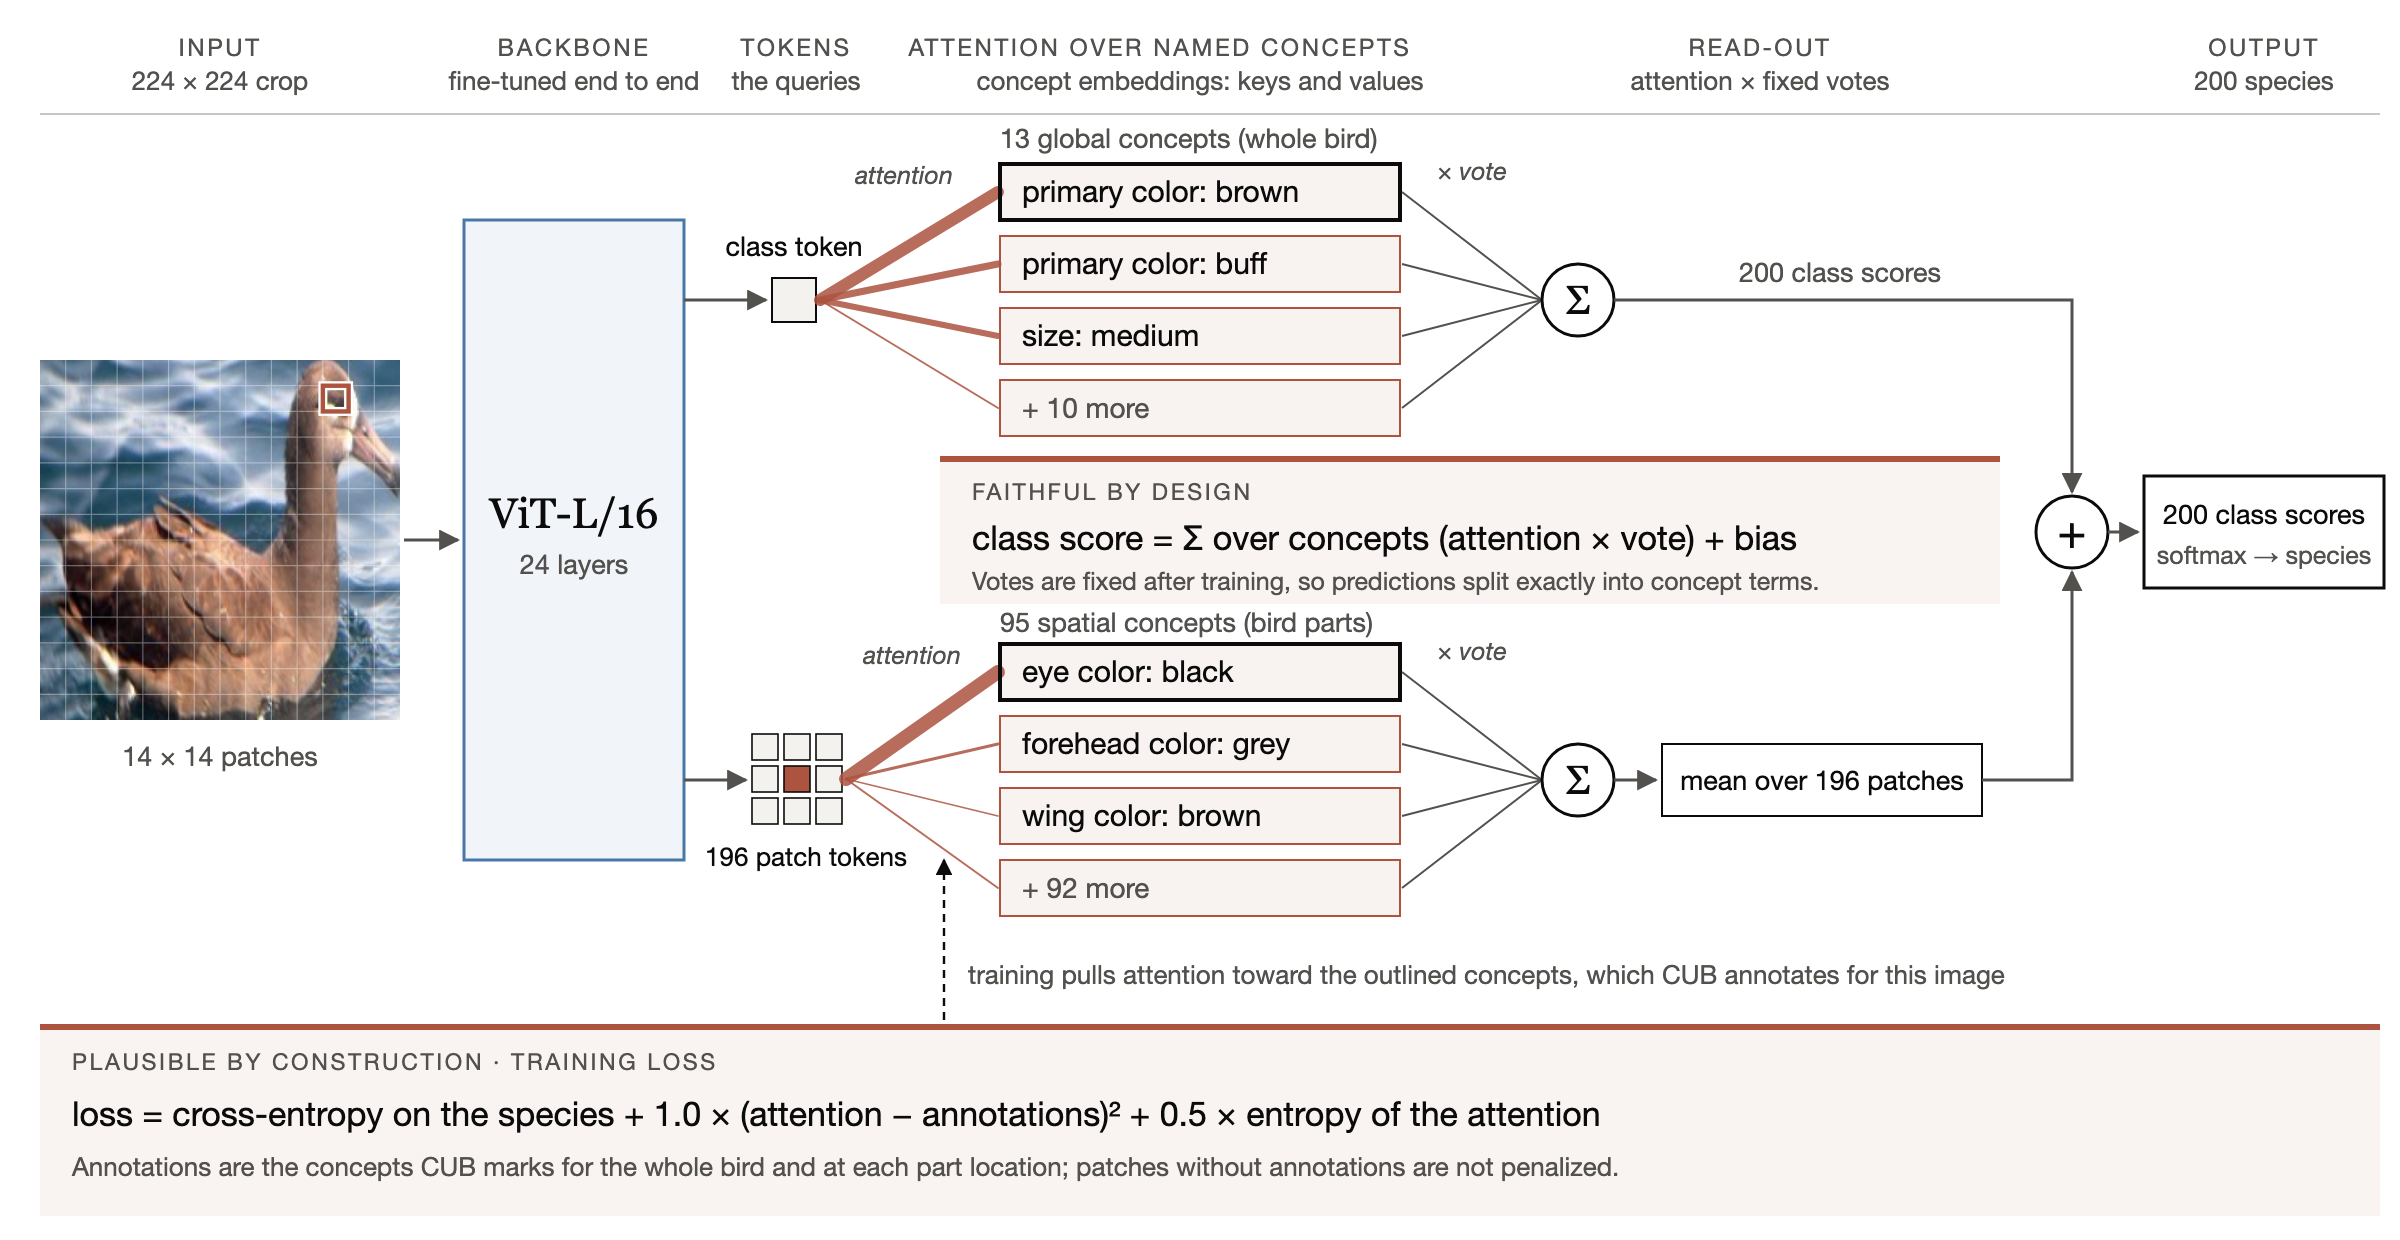

<div style="font-size: 13.5px; line-height: 1.45; opacity: 0.8; margin: 4px 0 10px 0; max-width: 960px;"><b>Figure 1.1</b> The model as the repository builds it for CUB-200-2011 (<code>cub_cvit</code> in <code>concept_transformer/ctc/vit.py</code>), drawn on test image 3. The two shaded boxes are the paper's two claims. Line weights only illustrate attention; Figures 1.2 and 1.3 show what the trained model computed for this image.</div>

<details><summary style="cursor: pointer; font-size: 15px;"><b>Backup:</b> the read-out as an equation, and how the 108 concepts were chosen</summary>

$$\text{score}_k(x) \;=\; \sum_{c} \gamma_c(x)\,\beta_{ck} \;+\; b_k, \qquad \gamma_c(x) \;=\; \frac{1}{P}\sum_{p=1}^{P} \alpha_{pc}(x)$$

$\alpha_{pc}$ is the attention of patch $p$ on concept $c$, $\gamma_c$ its average over the $P$ patches (for a global concept, the class token's attention), and $\beta_{ck}$ the fixed vote of concept $c$ for class $k$: its value vector times the output projection (the paper's Equation 2). With several attention heads, the sum runs over head and concept pairs.

The 13 global and 95 spatial concepts are the CUB attributes, out of 312, present in at least 45% of a species' images and in at least 9 species.

</details>

### 1.4 The method on one test image

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; set <code>EXAMPLE_IMAGE_ID</code> to 3, 190 or 622 (predicted correctly) or 434, 1593 or 2904 (wrong) and re-run</span></div>

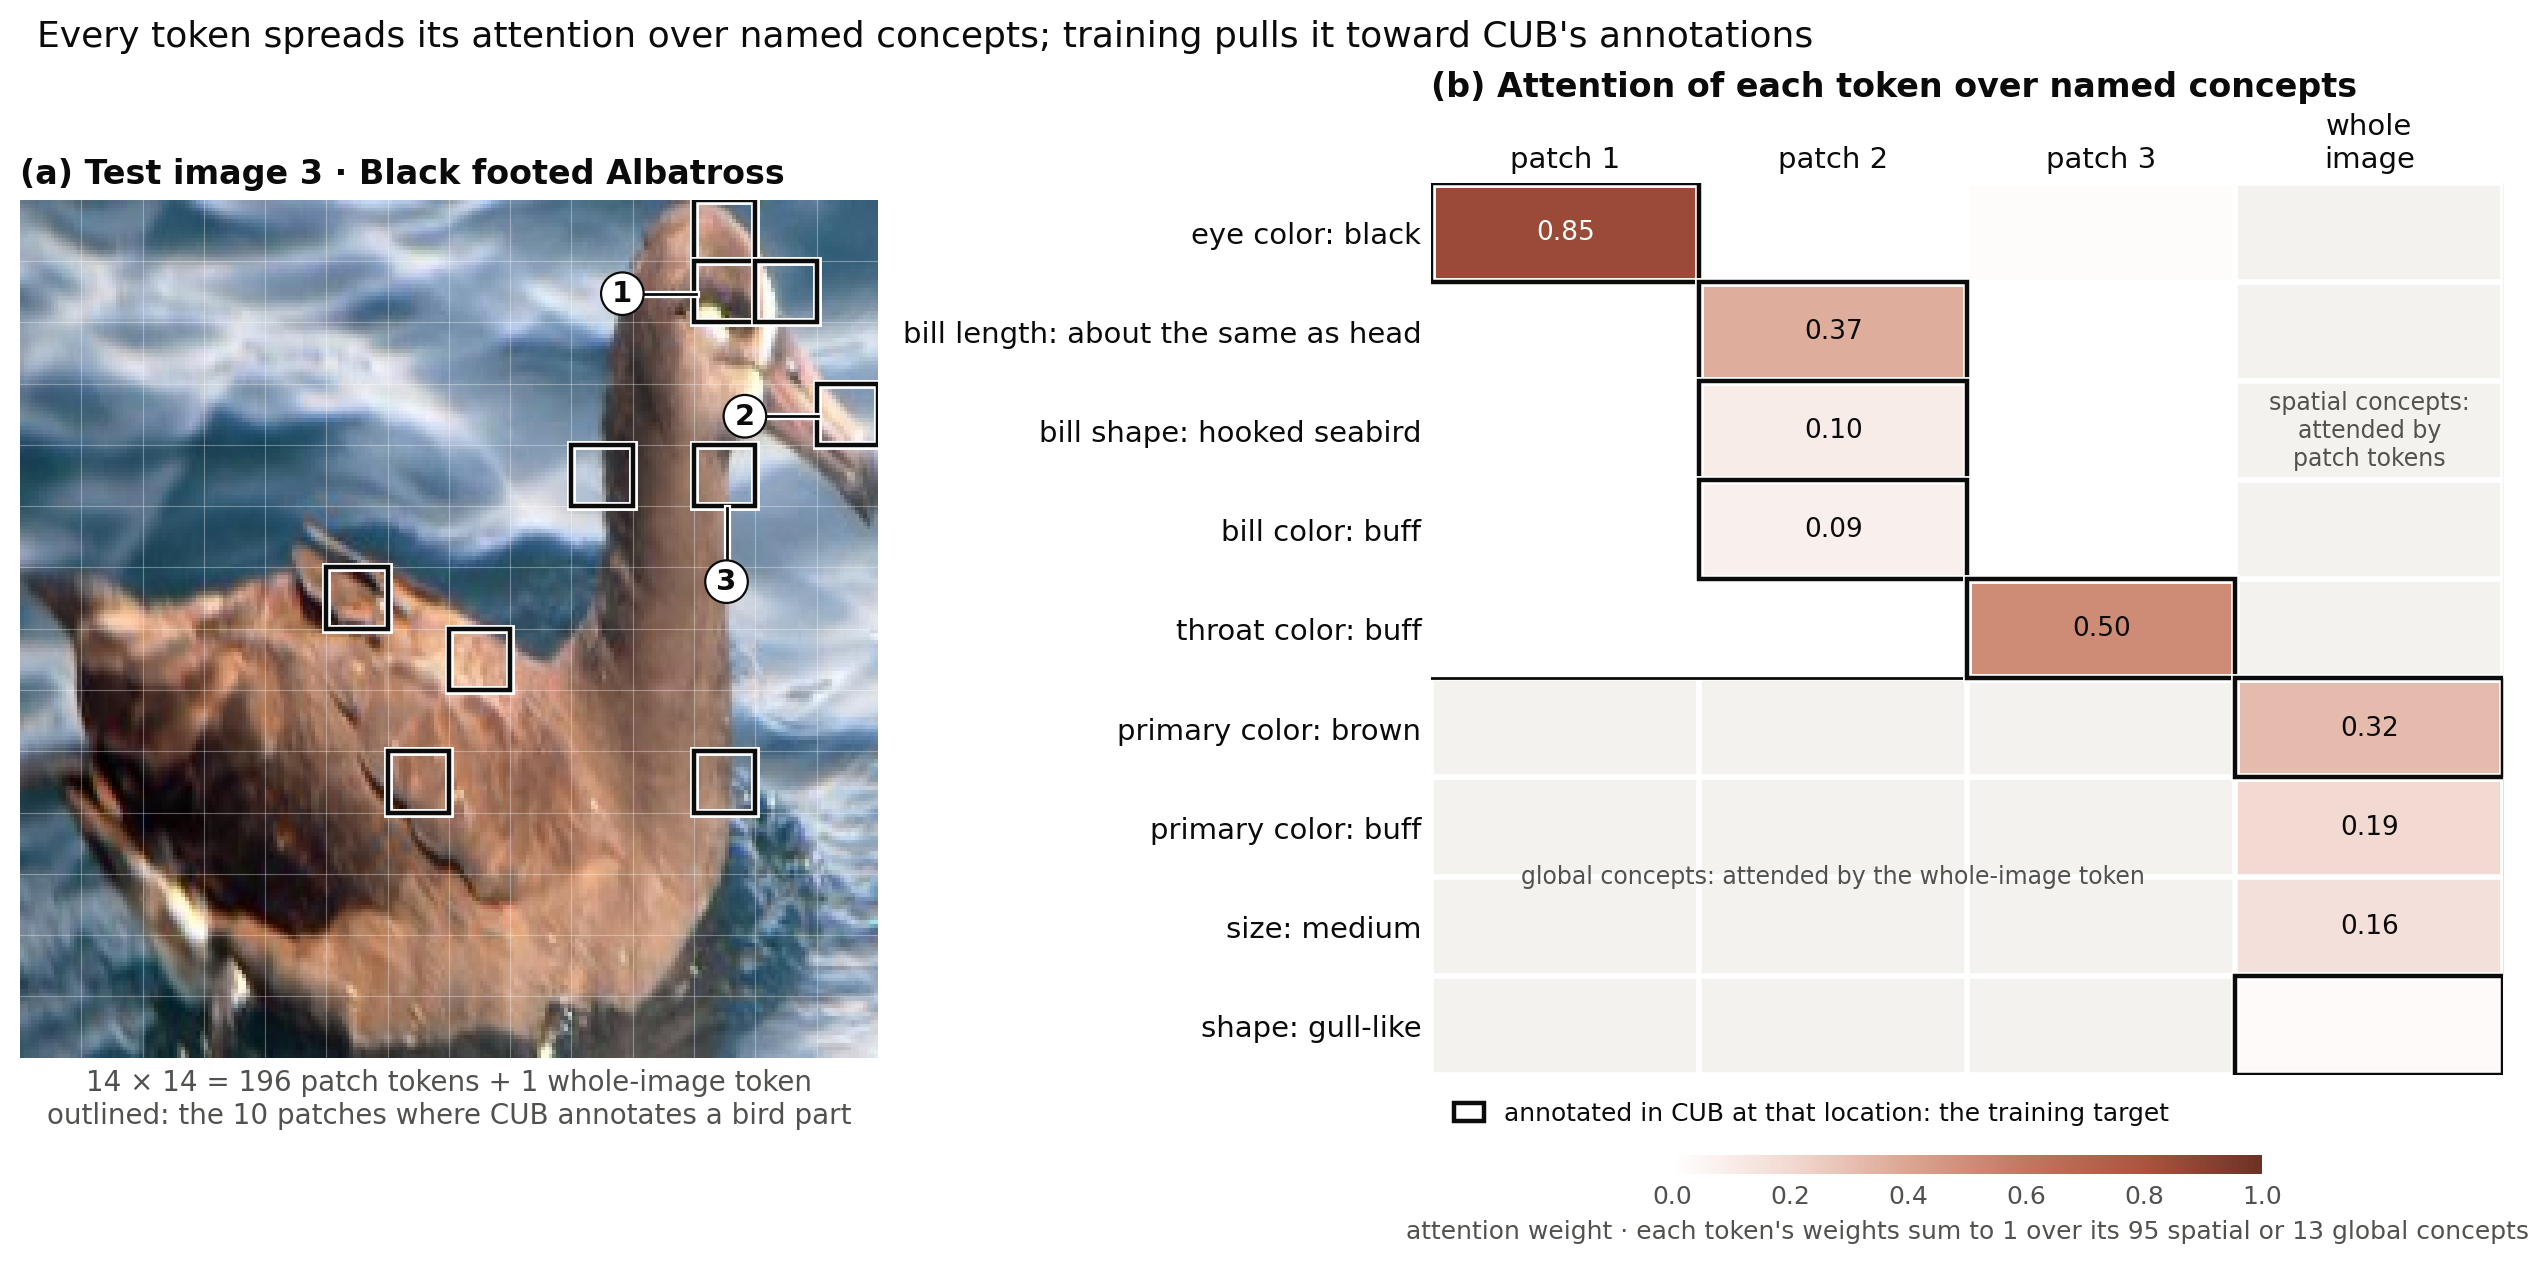

In [33]:
# Figure 1.2: one test image as tokens, and each token's attention over named concepts.
EXAMPLE_IMAGE_ID = 3  # a cached test image: 3, 190, 622 (predicted correctly) or 434, 1593, 2904 (wrong)
PATCHES_SHOWN = 3   # annotated patches drawn as table columns

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

INK, MUTED = "#0b0b0b", "#52514e"
ATTENTION = LinearSegmentedColormap.from_list(  # white to terracotta: the darker the cell, the more attention
    "attention", ["#ffffff", "#f2d9d1", "#dca592", "#c27660", PALETTE["accent"], "#6b3225"])
ATTENTION.set_bad("#f3f2ee")  # cells a token cannot attend to: patches see no global concepts, and vice versa

report = json.loads((ARTIFACT_DIR / "examples.json").read_text())
arrays = np.load(ARTIFACT_DIR / "selected_examples.npz")
saved_ids = [sample["image_id"] for sample in report["examples"]]
assert EXAMPLE_IMAGE_ID in saved_ids, "Choose EXAMPLE_IMAGE_ID from {}".format(saved_ids)
index = saved_ids.index(EXAMPLE_IMAGE_ID)
example = report["examples"][index]


def concept_label(attribute):
    """'has_eye_color::black' -> 'eye color: black'; size ranges are dropped."""
    family, value = attribute.replace("has_", "").split("::")
    return "{}: {}".format(family.replace("_", " "), value.split("_(")[0].replace("_", " "))


global_names = [concept_label(name) for name in report["global_attributes"]]
spatial_names = [concept_label(name) for name in report["spatial_attributes"]]
image = arrays["images"][index]                         # the 224 x 224 test crop, de-normalized
spatial_attention = arrays["spatial_attention"][index]  # (patches, spatial concepts); each row sums to 1
spatial_targets = arrays["spatial_targets"][index]      # 1 = annotated there; all-NaN row = no annotation
global_attention = arrays["global_attention"][index]    # (global concepts,); sums to 1
global_targets = arrays["global_targets"][index]
n_patches, n_spatial = spatial_attention.shape
grid = int(round(n_patches ** 0.5))
patch_size = image.shape[0] / grid
annotated = [int(p) for p in np.flatnonzero(~np.isnan(spatial_targets).all(axis=1))]


def best_annotated_concept(patch):
    concepts = np.flatnonzero(spatial_targets[patch] == 1)
    return int(concepts[np.argmax(spatial_attention[patch, concepts])])


# Columns: for each concept family, the annotated patch whose attention best matches its annotation.
shown, families = [], set()
for patch in sorted(annotated, key=lambda p: -spatial_attention[p, best_annotated_concept(p)]):
    family = spatial_names[best_annotated_concept(patch)].split(":")[0]
    if family not in families:
        shown.append(patch)
        families.add(family)
    if len(shown) == PATCHES_SHOWN:
        break
shown.sort()

# Rows: each shown patch's annotated concepts (up to 3) and its most-attended concept,
# then the whole-image token's annotated global concepts and its top 3.
spatial_rows = []
for patch in shown:
    marked = np.flatnonzero(spatial_targets[patch] == 1)
    marked = marked[np.argsort(-spatial_attention[patch, marked])][:3]
    for concept in list(marked) + [np.argmax(spatial_attention[patch])]:
        if int(concept) not in spatial_rows:
            spatial_rows.append(int(concept))
global_rows = sorted({int(c) for c in np.flatnonzero(global_targets == 1)}
                     | {int(c) for c in np.argsort(-global_attention)[:3]},
                     key=lambda c: -global_attention[c])
n_spatial_rows = len(spatial_rows)
table = np.full((n_spatial_rows + len(global_rows), len(shown) + 1), np.nan)
is_target = np.zeros(table.shape, dtype=bool)
for column, patch in enumerate(shown):
    table[:n_spatial_rows, column] = spatial_attention[patch, spatial_rows]
    is_target[:n_spatial_rows, column] = spatial_targets[patch, spatial_rows] == 1
table[n_spatial_rows:, -1] = global_attention[global_rows]
is_target[n_spatial_rows:, -1] = global_targets[global_rows] == 1
n_rows, n_columns = table.shape


def outline(ax, x, y, width, height):
    """Annotation outline: ink inside a white halo, readable on light and dark pixels."""
    for color, linewidth in [("white", 3.2), (INK, 1.6)]:
        ax.add_patch(Rectangle((x, y), width, height, fill=False, edgecolor=color,
                               linewidth=linewidth, zorder=3))


def patch_center(patch):
    row, col = divmod(patch, grid)
    return np.array([(col + 0.5) * patch_size, (row + 0.5) * patch_size])


def badge_spot(patch, placed):
    """Near the patch and inside the image, clear of other badges and, if possible, of every outline."""
    candidates = [patch_center(patch) + 1.7 * patch_size * np.array(offset) for offset in
                  [(-1, 0), (0, -1), (1, 0), (0, 1), (-0.8, -0.8), (0.8, -0.8), (-0.8, 0.8), (0.8, 0.8)]]
    candidates = [spot for spot in candidates if (spot >= 0.6 * patch_size).all()
                  and (spot <= image.shape[0] - 0.6 * patch_size).all()]
    for avoid in [annotated, shown]:
        for spot in candidates:
            if all(np.abs(spot - patch_center(p)).max() > 1.05 * patch_size for p in avoid) and \
                    all(np.abs(spot - other).max() > 1.3 * patch_size for other in placed):
                return spot
    return candidates[0]


def patch_edge_toward(patch, spot):
    """Point on the patch's border facing the badge, where its leader line ends."""
    direction = spot - patch_center(patch)
    return patch_center(patch) + direction * 0.5 * patch_size / np.abs(direction).max()


with plt.rc_context({"axes.grid": False, "font.size": 10.5, "text.color": INK,
                     "xtick.color": INK, "ytick.color": INK}):
    figure, (ax_image, ax_table) = plt.subplots(
        1, 2, figsize=(12.5, 6.2), gridspec_kw={"width_ratios": [1, 1.25]}, constrained_layout=True)

    # (a) The image as tokens: the patch grid, annotated part locations, numbered table columns.
    ax_image.imshow(image)
    for k in range(1, grid):
        ax_image.axhline(k * patch_size - 0.5, color="white", linewidth=0.4, alpha=0.35)
        ax_image.axvline(k * patch_size - 0.5, color="white", linewidth=0.4, alpha=0.35)
    for patch in annotated:
        row, col = divmod(patch, grid)
        outline(ax_image, col * patch_size - 0.5, row * patch_size - 0.5, patch_size, patch_size)
    placed = []
    for number, patch in enumerate(shown, start=1):
        spot = badge_spot(patch, placed)
        placed.append(spot)
        edge = patch_edge_toward(patch, spot)
        for color, linewidth in [("white", 2.6), (INK, 1.0)]:
            ax_image.plot([edge[0], spot[0]], [edge[1], spot[1]], color=color, linewidth=linewidth, zorder=3.5)
        ax_image.text(spot[0], spot[1], str(number), ha="center", va="center", fontsize=10.5,
                      fontweight="bold", zorder=4,
                      bbox={"boxstyle": "circle,pad=0.25", "facecolor": "white", "edgecolor": INK,
                            "linewidth": 0.8})
    ax_image.set_xlim(-0.5, image.shape[1] - 0.5)
    ax_image.set_ylim(image.shape[0] - 0.5, -0.5)
    ax_image.set_xticks([])
    ax_image.set_yticks([])
    ax_image.set_title("(a) Test image {} · {}".format(example["image_id"], example["true_class"]),
                       loc="left", fontsize=12)
    ax_image.set_xlabel("{0} × {0} = {1} patch tokens + 1 whole-image token\n"
                        "outlined: the {2} patches where CUB annotates a bird part".format(
                            grid, n_patches, len(annotated)), color=MUTED, fontsize=10)

    # (b) Each token's attention over named concepts; outlined cells are the training target.
    cells = ax_table.imshow(np.ma.masked_invalid(table), cmap=ATTENTION, vmin=0, vmax=1, aspect="auto")
    for position in np.arange(-0.5, n_rows):
        ax_table.plot([-0.5, n_columns - 0.5], [position, position], color="white", linewidth=2)
    for position in np.arange(-0.5, n_columns):
        ax_table.plot([position, position], [-0.5, n_rows - 0.5], color="white", linewidth=2)
    for (r, c), value in np.ndenumerate(table):
        if np.isfinite(value) and value >= 0.05:
            ax_table.text(c, r, "{:.2f}".format(value), ha="center", va="center", fontsize=9.5,
                          color="white" if value >= 0.7 else INK)
        if is_target[r, c]:
            outline(ax_table, c - 0.5, r - 0.5, 1, 1)
    ax_table.plot([-0.5, n_columns - 0.5], [n_spatial_rows - 0.5] * 2, color=INK, linewidth=1.0)
    ax_table.text(n_columns - 1, (n_spatial_rows - 1) / 2, "spatial concepts:\nattended by\npatch tokens",
                  ha="center", va="center", fontsize=8.5, color=MUTED)
    ax_table.text((n_columns - 2) / 2, n_spatial_rows + (len(global_rows) - 1) / 2,
                  "global concepts: attended by the whole-image token", ha="center", va="center",
                  fontsize=8.5, color=MUTED)
    ax_table.set_xlim(-0.5, n_columns - 0.5)
    ax_table.set_ylim(n_rows - 0.5, -0.5)
    ax_table.set_xticks(range(n_columns))
    ax_table.set_xticklabels(["patch {}".format(n) for n in range(1, len(shown) + 1)] + ["whole\nimage"])
    ax_table.xaxis.tick_top()
    ax_table.set_yticks(range(n_rows))
    ax_table.set_yticklabels([spatial_names[c] for c in spatial_rows] + [global_names[c] for c in global_rows])
    ax_table.tick_params(length=0)
    ax_table.set_title("(b) Attention of each token over named concepts", loc="left", fontsize=12)
    for ax in (ax_image, ax_table):
        for spine in ax.spines.values():
            spine.set_visible(False)
    colorbar = figure.colorbar(cells, ax=ax_table, orientation="horizontal", fraction=0.04, pad=0.02,
                               shrink=0.55, aspect=30)
    colorbar.outline.set_visible(False)
    colorbar.ax.tick_params(labelsize=9, colors=MUTED, length=0)
    colorbar.set_label("attention weight · each token's weights sum to 1 over its {} spatial or {} global concepts"
                       .format(n_spatial, len(global_names)), color=MUTED, fontsize=9)
    ax_table.legend(handles=[Rectangle((0, 0), 1, 1, fill=False, edgecolor=INK, linewidth=1.6)],
                    labels=["annotated in CUB at that location: the training target"], loc="upper left",
                    bbox_to_anchor=(0, -0.005), frameon=False, fontsize=9, handlelength=1.2)
    figure.suptitle("Every token spreads its attention over named concepts; training pulls it toward "
                    "CUB's annotations", x=0.01, ha="left", fontsize=13)
    plt.show()
caption("<b>Figure 1.2</b> How the model reads test image {}. (a) The crop as {} patch tokens. Outlined patches carry "
        "CUB part annotations; numbers mark the table's columns, which are, per concept family, the annotated patch "
        "whose attention best matches its annotation. (b) Each column is one token's attention: patch tokens attend "
        "only over spatial concepts, the whole-image token only over global ones. Outlined cells are what CUB "
        "annotates at that location, the target the explanation loss pulls attention toward. Values are cached "
        "from the disjoint run's selected checkpoint.".format(EXAMPLE_IMAGE_ID, n_patches))

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; set <code>EXAMPLE_IMAGE_ID</code> to the image shown in Figure 1.2; <code>CONCEPTS_SHOWN</code> sets how many concepts get their own bar</span></div>

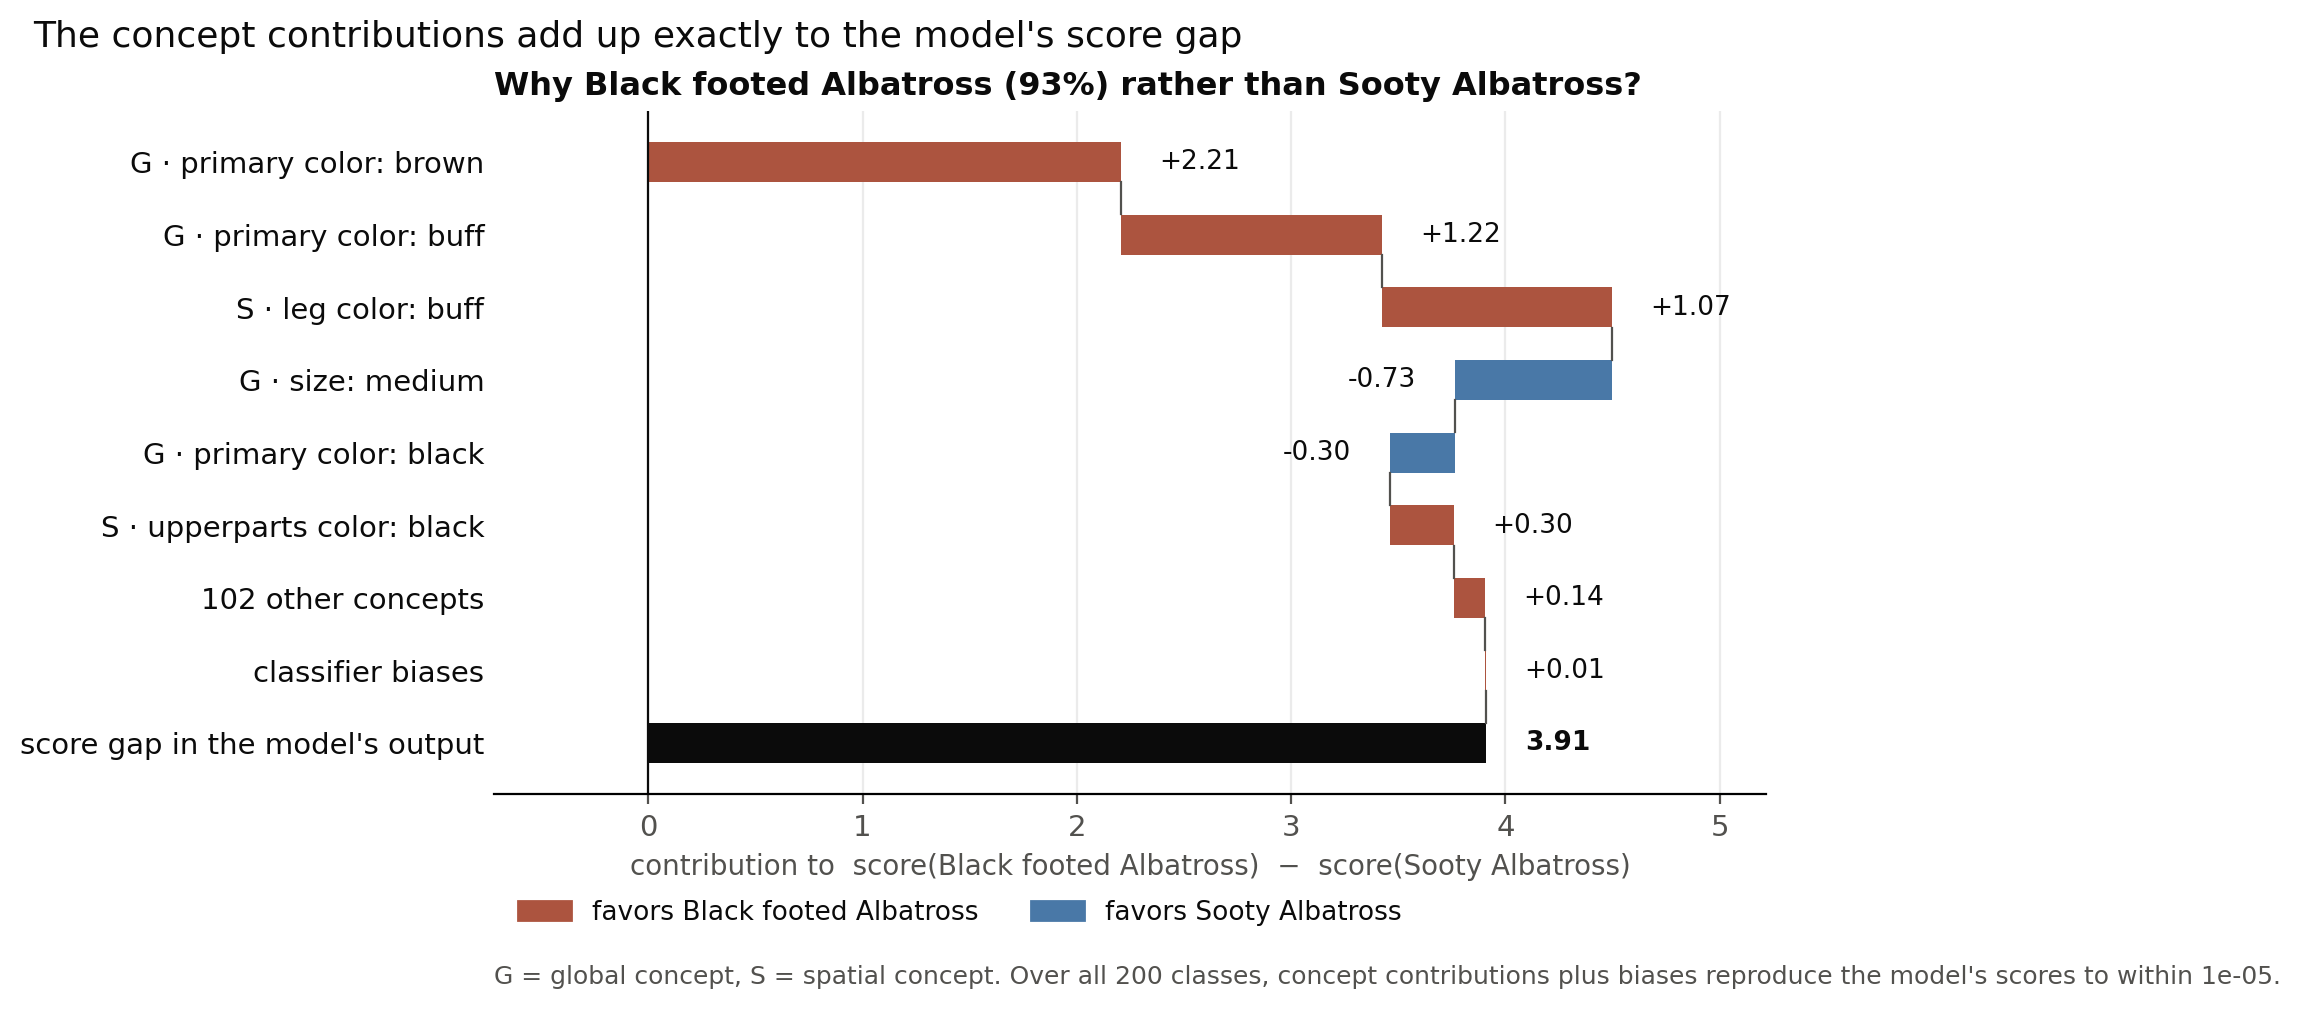

In [3]:
# Figure 1.3: the same prediction split into per-concept contributions that add up to the model's score gap.
EXAMPLE_IMAGE_ID = 3  # the image from Figure 1.2: 3, 190, 622 (predicted correctly) or 434, 1593, 2904 (wrong)
CONCEPTS_SHOWN = 6    # largest contributions drawn one by one; the remaining concepts share one bar

from matplotlib.patches import Patch

INK, MUTED = "#0b0b0b", "#52514e"
report = json.loads((ARTIFACT_DIR / "examples.json").read_text())
arrays = np.load(ARTIFACT_DIR / "selected_examples.npz")
saved_ids = [sample["image_id"] for sample in report["examples"]]
assert EXAMPLE_IMAGE_ID in saved_ids, "Choose EXAMPLE_IMAGE_ID from {}".format(saved_ids)
index = saved_ids.index(EXAMPLE_IMAGE_ID)
example = report["examples"][index]


def concept_label(attribute):
    """'has_eye_color::black' -> 'eye color: black'; size ranges are dropped."""
    family, value = attribute.replace("has_", "").split("::")
    return "{}: {}".format(family.replace("_", " "), value.split("_(")[0].replace("_", " "))


# The cached contributions list the 13 global concepts, then the 95 spatial ones, each summed over heads.
concept_names = (["G · " + concept_label(name) for name in report["global_attributes"]]
                 + ["S · " + concept_label(name) for name in report["spatial_attributes"]])
contributions = arrays["contributions"][index]  # (concepts, classes)
logits, bias = arrays["logits"][index], arrays["bias"]
assert contributions.shape[0] == len(concept_names)
predicted, comparison = example["predicted_label"], example["comparison_label"]
predicted_name, comparison_name = example["predicted_class"], example["comparison_class"]

gap_by_concept = contributions[:, predicted] - contributions[:, comparison]
order = np.argsort(-np.abs(gap_by_concept))
steps = list(gap_by_concept[order[:CONCEPTS_SHOWN]]) + [
    gap_by_concept[order[CONCEPTS_SHOWN:]].sum(), bias[predicted] - bias[comparison]]
labels = [concept_names[c] for c in order[:CONCEPTS_SHOWN]] + [
    "{} other concepts".format(len(order) - CONCEPTS_SHOWN), "classifier biases"]
score_gap = logits[predicted] - logits[comparison]
largest_error = np.abs(contributions.sum(axis=0) + bias - logits).max()  # over all classes
assert abs(sum(steps) - score_gap) < 1e-3, "The contributions should rebuild the score gap."

with plt.rc_context({"axes.grid": False, "font.size": 10.5, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": INK}):
    figure, ax = plt.subplots(figsize=(10.5, 4.9), constrained_layout=True)
    starts = np.concatenate([[0.0], np.cumsum(steps)[:-1]])
    reach = np.concatenate([[0.0, score_gap], np.cumsum(steps)])
    pad = 0.04 * (reach.max() - reach.min())
    ax.barh(range(len(steps)), steps, left=starts, height=0.55,
            color=[PALETTE["accent"] if step >= 0 else PALETTE["neg"] for step in steps])
    ax.barh(len(steps), score_gap, height=0.55, color=INK)
    for row, (start, step) in enumerate(zip(starts, steps)):
        end = start + step
        ax.plot([end, end], [row + 0.28, row + 0.72], color=MUTED, linewidth=0.8)  # link to the next bar
        ax.text(end + (pad if step >= 0 else -pad), row, "{:+.2f}".format(step),
                ha="left" if step >= 0 else "right", va="center", fontsize=9.5)
    ax.text(score_gap + (pad if score_gap >= 0 else -pad), len(steps), "{:.2f}".format(score_gap),
            ha="left" if score_gap >= 0 else "right", va="center", fontsize=9.5, fontweight="bold")
    ax.axvline(0, color=INK, linewidth=0.8)
    ax.set_xlim(reach.min() - 4 * pad, reach.max() + 4 * pad)
    ax.set_yticks(range(len(steps) + 1))
    ax.set_yticklabels(labels + ["score gap in the model's output"])
    ax.invert_yaxis()
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.set_xlabel("contribution to  score({})  −  score({})".format(predicted_name, comparison_name),
                  color=MUTED)
    question = "Why {} ({:.0%})".format(predicted_name, example["predicted_probability"])
    question += " rather than {}?".format(comparison_name) if example["correct"] else \
        " instead of the true class, {}?".format(comparison_name)
    ax.set_title(question, loc="left", fontsize=11.5)
    ax.legend(handles=[Patch(color=PALETTE["accent"]), Patch(color=PALETTE["neg"])],
              labels=["favors " + predicted_name, "favors " + comparison_name],
              loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2, frameon=False, fontsize=9.5)
    ax.text(0, -0.25, "G = global concept, S = spatial concept. Over all {} classes, concept contributions plus "
            "biases reproduce the model's scores to within {:.0e}.".format(logits.shape[0], largest_error),
            transform=ax.transAxes, va="top", color=MUTED, fontsize=9)
    figure.suptitle("The concept contributions add up exactly to the model's score gap", x=0.01, ha="left",
                    fontsize=13)
    plt.show()
caption("<b>Figure 1.3</b> Why the model chose {} over {}. Each bar is one concept's share of the gap between the two "
        "class scores: its attention times its fixed vote, summed over heads. Terracotta steps push toward the "
        "prediction and blue-grey steps toward the alternative, which is the runner-up for a correct prediction and "
        "the true class for a wrong one. The remaining concepts and the classifier biases close the sum, so nothing "
        "is approximated after the fact.".format(predicted_name, comparison_name))

<div style="border-top: 3px solid #ac543f; background: rgba(172, 84, 63, 0.07); padding: 12px 18px 14px 18px;"><div style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65; margin-bottom: 6px;">Key point</div><div style="font-family: Newsreader, Georgia, serif; font-size: 21px; line-height: 1.4;">The explanation is given by the computation itself: attention shows which named concepts the model used and where they are used.</div></div>

### 1.5 Hardware and software

The notebook runs in a HiPerGator CPU session on Linux, with Python 3.8.20 and PyTorch 2.0.1 built for CUDA 11.8; both training runs used one NVIDIA L4 GPU requested through Slurm. The report reads this session live and the two training jobs from their saved records.

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; nothing to change; inside a GPU allocation, the GPU row names the card</span></div>

In [4]:
# Environment report: this notebook session, read live, and the two L4 training jobs, read from their records.
import torch

torch.set_num_threads(CPU_THREADS)
commit = json.loads((PROJECT_DIR / "upstream.json").read_text())["commit"]
fact_table([
    ("Host · Slurm job", "{} · {}".format(platform.node(), os.environ.get("SLURM_JOB_ID", "none"))),
    ("Operating system", "{} {} ({})".format(platform.system(), platform.release(), platform.machine())),
    ("Python", "{} in {}".format(platform.python_version(), sys.prefix)),
    ("PyTorch", "{}, built for CUDA {}".format(torch.__version__, torch.version.cuda)),
    ("GPU in this session", torch.cuda.get_device_name(0) if torch.cuda.is_available()
     else "none visible: a CPU session with {} threads".format(CPU_THREADS)),
    ("IBM repository commit", commit),
], title="This session, read live")

# GPU requests as submitted to Slurm: the repository-split job's submission record and the disjoint job's record.
submission = json.loads((SETUP_LOGS / "slurm-submission.json").read_text())
disjoint_job = EVIDENCE["disjoint_training_job"]
assert submission["job_id"] == REPO_RUN and disjoint_job["job_id"] == DISJOINT_RUN
gpu_request = {REPO_RUN: submission["gres"].split(":", 1)[1], DISJOINT_RUN: disjoint_job["resource_request"]["gpu"]}
rows = []
for job in (REPO_RUN, DISJOINT_RUN):
    gpu_model, gpu_count = gpu_request[job].split(":")  # e.g. "l4:1"
    run = RUNS[job]["run"]
    rows.append(("{} · job {}".format(RUN_LABEL[job], job), "{} × NVIDIA {} on partition {} · device {} · {}".format(
        gpu_count, gpu_model.upper(), run["slurm_partition"], run["device"],
        RUNS[job]["snapshot"]["scheduler"]["State"])))
recorded = json.loads((SETUP_LOGS / "environment.json").read_text())
interpreters = sorted({RUNS[job]["run"]["command"][0] for job in (REPO_RUN, DISJOINT_RUN)})
rows.append(("Training software", "Python {}, PyTorch {} with CUDA runtime {} · interpreter {}".format(
    recorded["python"], recorded["packages"]["torch"], recorded["torch_cuda_runtime"], " and ".join(interpreters))))
fact_table(rows, title="Training jobs, read from their records")

<div style="border-top: 1px solid rgba(128, 128, 128, 0.45); padding-top: 10px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65;">Walkthrough &middot; about 2 min</span></div>

## <span style="font-family: Newsreader, Georgia, serif; font-size: 34px; font-weight: 400;">2. Environment Setup</span>

<div style="font-size: 19px; line-height: 1.5; max-width: 44em;">The repository's model was deployed on HiPerGator, and training was done on an NVIDIA L4.</div>

### 2.1 Dependency versions

| Layer | Packages | Decision | Why |
| --- | --- | --- | --- |
| Python | Python 3.8.20 | Kept | Supports the kept SciPy 1.7.1 and pandas 1.3.3 pins |
| Science and model | NumPy, SciPy, pandas, timm, albumentations | Kept at the repository's exact pins | Data handling and the model code stay on the versions the authors used |
| Training runtime | PyTorch, torchvision, Lightning, Bolts, TorchMetrics | Updated as one compatible set: PyTorch 1.10 → 2.0.1 for CUDA 11.8, Lightning 1.4.8 → 1.9.5 | Drives the L4 with native mixed precision |

In [5]:
import importlib.metadata as metadata
from html import escape

import tomli  # Python 3.8 has no tomllib


def read_pins(lines):
    """{package: version} from 'name==version' lines; a bare name is unpinned."""
    pins = {}
    for line in lines:
        requirement = line.split("#", 1)[0].strip()
        if requirement:
            name, separator, version = requirement.partition("==")
            pins[name.lower().replace("_", "-")] = version if separator else "unpinned"
    return pins


def installed(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return "missing"


upstream = read_pins((REPO_DIR / "requirements.txt").read_text().splitlines())
selected = read_pins(tomli.loads((PROJECT_DIR / "pyproject.toml").read_text())["project"]["dependencies"])
deps = pd.DataFrame([
    {"package": name, "upstream": upstream.get(name, ""), "selected": version, "installed": installed(name),
     "change": ("added" if name not in upstream else "pinned" if upstream[name] == "unpinned"
                else "kept" if upstream[name] == version else "updated")}
    for name, version in selected.items()
])

# Inline-styled rows rather than a DataFrame table, which JupyterLab right-aligns in outputs.
GROUPS = [("updated", "Updated: the training runtime, moved as one set", PALETTE["accent"]),
          ("kept", "Kept at the repository's pin", PALETTE["neg"]),
          ("pinned", "Pinned where the repository gave no version", PALETTE["rule"]),
          ("added", "Added: transitive and notebook pins", PALETTE["rule"])]
WIDTHS = [30, 20, 24, 24]  # percent of the row: package, repository pin, selected, installed


def row(values, style=""):
    spans = "".join(f'<span style="display: inline-block; width: {width}%; vertical-align: top;">'
                    f"{escape(str(value))}</span>" for value, width in zip(values, WIDTHS))
    return f'<div style="padding: 4px 0;{style}">{spans}</div>'


parts = [row(["Package", "Repository pin", "Selected", "Installed"],
             " font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65;")]
for change, title, colour in GROUPS:
    group = deps[deps["change"] == change]
    if group.empty:
        continue
    parts.append(f'<div style="border-top: 3px solid {colour}; margin-top: 8px; padding: 6px 0 2px 0; '
                 f'font-weight: 600;">{escape(title)} ({len(group)})</div>')
    if change == "added":  # many small pins read better as one wrapped line
        parts.append('<div style="padding: 4px 0; opacity: 0.8;">' + " &middot; ".join(
            f"{escape(name)} {escape(version)}" for name, version in zip(group["package"], group["installed"])
        ) + "</div>")
    else:
        parts += [row(values, f' border-top: 1px solid {PALETTE["rule"]};')
                  for values in group[["package", "upstream", "selected", "installed"]].values.tolist()]
display(HTML('<div style="font-size: 14px; max-width: 780px;">' + "".join(parts) + "</div>"))

mismatched = deps[deps["installed"] != deps["selected"]]
lock_file = PROJECT_DIR / "uv.lock"
caption(f"<b>Table 2.1</b> Read live from <code>concept_transformer/requirements.txt</code>, "
        f"<code>pyproject.toml</code> and this kernel. {len(deps) - len(mismatched)} of {len(deps)} installed "
        f"versions match the selection; <code>uv.lock</code> "
        f"{'pins' if lock_file.is_file() else 'is MISSING and should pin'} the full resolved environment.")
assert mismatched.empty, "Installed differs from pyproject.toml for: " + ", ".join(mismatched["package"])

<details><summary style="cursor: pointer; font-size: 15px;"><b>Backup:</b> rebuild this environment from <code>uv.lock</code></summary>

Run once on a HiPerGator compute node before the call. These are preparation steps, not cells to run live.

```bash
cd "$WORK_DIR"   # export WORK_DIR first: the WORK_DIR path from the configuration cell
export UV_PYTHON_INSTALL_DIR="$PWD/.uv-python" UV_CACHE_DIR="$PWD/.uv-cache"
uv python install 3.8.20
uv venv --python 3.8.20 .venv
uv sync --locked --python .venv/bin/python   # --python: never the cluster's loaded Python
.venv/bin/python -m ipykernel install --sys-prefix \
  --name concept_transformer --display-name "Concept Transformer (HPG Python 3.8)"
.venv/bin/jupyter lab
```

No CUDA toolkit module or Apex install is needed: the CUDA 11.8 PyTorch wheels carry their own runtime, and mixed precision is native to PyTorch. `--locked` makes `uv sync` stop if `pyproject.toml` and `uv.lock` disagree.

</details>

### 2.2 Compatibility issues and where they came from

Six problems stood between the published code and a run on HiPerGator. Only one is a bug in the original code; the others came from the cluster, the documentation or our own runtime upgrade.

| Problem | Origin | Resolution |
| --- | --- | --- |
| Bolts 0.6.0 does not resolve with Lightning 1.9.5 | Our runtime upgrade | Bolts 0.7.0 with Lightning 1.9.5 and TorchMetrics 0.11.4 |
| The original `Trainer` arguments and `accuracy(preds, y)` call do not run on Lightning 1.9.5 and TorchMetrics 0.11.4; `trainer.test()` needs the datamodule | Our runtime upgrade | `accelerator` and `devices`, native 16-bit mixed precision instead of Apex, `task="multiclass"`, an explicit datamodule |
| CUDA is not visible in the notebook | Slurm: a CPU session gets no GPU | CUDA only when one is visible; training requests an L4 through `sbatch` |
| The README lists NumPy 1.20.3, `requirements.txt` 1.22.0 | Original documentation | Follow `requirements.txt` |

<details><summary style="cursor: pointer; font-size: 15px;"><b>Backup:</b> the runtime patch, before and after</summary>

Abridged from `patches/hpg-runtime.patch` and `patches/debug-test-no-checkpoint.patch`, shown against the upstream code. It changes only how training is launched and measured; the model, losses, optimizer and augmentation are the repository's.

```diff
 # ctc/ctc_model.py: the accuracy metric
-        acc = accuracy(preds, y)
+        acc = accuracy(preds, y, task="multiclass", num_classes=logits.shape[-1])

 # ctc/ctc_model.py: get_trainer(), GPU branch
-                kwargs = {"amp_backend": "apex", "amp_level": "O2", "precision": 16}
-            trainer = pl.Trainer(
-                logger=logger,
-                gpus=-1,
-                auto_select_gpus=True,
-                ...
-                progress_bar_refresh_rate=10,
-                gradient_clip_val=1.0,
-                **kwargs,
-            )
+    use_cuda = torch.cuda.is_available() and not debug
+    return pl.Trainer(
+        accelerator="gpu" if use_cuda else "cpu",
+        devices=1,
+        precision=16 if use_cuda and amp else 32,
+        ...
+        callbacks=list(callbacks) + [ModelSummary(...), TQDMProgressBar(refresh_rate=10)],
+        gradient_clip_val=1.0 if use_cuda and not debug else 0.0,
+    )

 # cvit_cub.py: the final evaluation
-test_results = trainer.test()
+test_results = trainer.test(
+    model=model,
+    datamodule=trainer.datamodule,
+    ckpt_path=None if args.debug else "best",
+)
```

</details>

<div style="border-top: 1px solid rgba(128, 128, 128, 0.45); padding-top: 10px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65;">Walkthrough &middot; about 2 min</span></div>

## <span style="font-family: Newsreader, Georgia, serif; font-size: 34px; font-weight: 400;">3. Data Download &amp; Preparation</span>

<div style="font-size: 19px; line-height: 1.5; max-width: 44em;">The data, the official CUB-200-2011 release, was downloaded and verified against its published checksum.</div>

### 3.1 Source

The repository's own downloader fetches a [third-party mirror](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L29) and [checks no checksum](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L276). We took the official archive from [CaltechDATA](https://data.caltech.edu/records/65de6-vp158) instead, matched it against the MD5 that CaltechDATA publishes, and decoded every image once before training. The cell shows that audit and re-hashes the annotation files on disk.

In [7]:
REHASH_ANNOTATIONS = True  # False shows the saved audit only

import hashlib
from html import escape

source_audit = json.loads((SETUP_LOGS / "cub-download.json").read_text())
assert source_audit["status"] == "passed" and source_audit["archive_md5_matches_published"]
audited_images, audited_classes = source_audit["images"], source_audit["classes"]
audit_rows = [
    ("Source", source_audit["checksum_source_url"]),
    ("Archive", f"{source_audit['archive_bytes'] / 1e9:.2f} GB, MD5 {source_audit['archive_hashes']['md5']}, "
                "matches the published value"),
    ("Images", f"{audited_images['fully_decoded']:,} of {audited_images['referenced']:,} decoded in full"),
    ("Species", f"{audited_classes['count']}, "
                + ("each present in both official splits" if audited_classes["all_classes_in_both_splits"]
                   else "NOT all present in both official splits")),
    ("Official split", f"{source_audit['split_counts']['train']:,} training / "
                       f"{source_audit['split_counts']['test']:,} test images"),
    ("Annotations", f"{source_audit['attributes']['rows']:,} image–attribute labels, "
                    f"{source_audit['parts']['rows']:,} part locations"),
    ("Audit finished", source_audit["audit_completed_utc"][:19].replace("T", " ") + " UTC"),
]
if Path(source_audit["loader_root"]) != DATA_DIR:  # the audit ran on another copy of the same files
    audit_rows.append(("Audited copy", f"{source_audit['dataset_path']}; this session reads {DATA_DIR / 'CUB_200_2011'}"))
if REHASH_ANNOTATIONS:
    changed = [name for name, expected in source_audit["annotation_sha256"].items()
               if hashlib.sha256((DATA_DIR / "CUB_200_2011" / name).read_bytes()).hexdigest() != expected]
    audit_rows.append(("Annotation files here",
                       f"all {len(source_audit['annotation_sha256'])} identical to the audited files (SHA-256)"
                       if not changed else "DIFFERENT from the audited files: " + ", ".join(changed)))
fact_table(audit_rows, title="Source data audit")
display(HTML(
    '<details style="font-size: 13.5px; margin-top: 6px;"><summary style="cursor: pointer; opacity: 0.8;">'
    f'All {len(source_audit["checks"])} audit checks</summary><ul>'
    + "".join(f"<li>{escape(check)}</li>" for check in source_audit["checks"]) + "</ul></details>"
))

<details><summary style="cursor: pointer; font-size: 15px;"><b>Backup:</b> download and audit commands</summary>

Run once from the repository root on HiPerGator. They are preparation, not cells for the call.

```bash
.venv/bin/python scripts/download_cub.py               # download, MD5 check, extract, copy attributes.txt inward
.venv/bin/python scripts/download_cub.py --check-only  # verify an existing copy without downloading
.venv/bin/python scripts/verify_cub.py                 # full audit, writes setup_logs/cub-download.json
```

Segmentation masks are not used by the model, so they are not downloaded.

</details>

### 3.2 Directory layout

`cvit_cub.py` passes `--data_dir` straight to the loader, which expects the **outer** `CUB_200_2011` folder and appends the inner one itself. The loader reads `attributes.txt` from the inner folder, but the archive extracts it to the outer one, so we copy it inward and keep the original.

<div style="max-width: 820px; font-size: 14px; line-height: 1.45; margin-top: 4px;">
<div style="border: 1px solid rgba(128, 128, 128, 0.45); border-top: 3px solid rgba(128, 128, 128, 0.45); padding: 8px 14px 10px 14px;">
<div style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65;">DATA_DIR &middot; passed as --data_dir</div>
<div style="font-family: Newsreader, Georgia, serif; font-size: 20px; margin: 2px 0 6px 0;"><code>CUB-200-2011/CUB_200_2011/</code></div>
<div style="border-top: 1px solid rgba(128, 128, 128, 0.25); padding: 5px 6px; background: rgba(190, 124, 28, 0.08);"><span style="display: inline-block; width: 44%; vertical-align: top; overflow-wrap: anywhere;"><code>attributes.txt</code></span><span style="display: inline-block; width: 54%; vertical-align: top; opacity: 0.8;">Where the archive extracts the attribute names. The loader never reads this copy.</span></div>
<div style="border: 1px solid rgba(128, 128, 128, 0.45); border-top: 3px solid rgba(128, 128, 128, 0.45); padding: 8px 14px 10px 14px; margin-top: 10px;">
<div style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65;">Inner folder &middot; the loader appends it to --data_dir</div>
<div style="font-family: Newsreader, Georgia, serif; font-size: 20px; margin: 2px 0 6px 0;"><code>CUB_200_2011/</code></div>
<div style="border-top: 1px solid rgba(128, 128, 128, 0.25); padding: 5px 6px; background: rgba(172, 84, 63, 0.07);"><span style="display: inline-block; width: 44%; vertical-align: top; overflow-wrap: anywhere;"><code>attributes.txt</code></span><span style="display: inline-block; width: 54%; vertical-align: top; opacity: 0.8;">Our byte-identical copy of the file above. The loader reads the attribute names only here.</span></div>
<div style="border-top: 1px solid rgba(128, 128, 128, 0.25); padding: 5px 6px;"><span style="display: inline-block; width: 44%; vertical-align: top; overflow-wrap: anywhere;"><code>cropped/</code></span><span style="display: inline-block; width: 54%; vertical-align: top; opacity: 0.8;">Bounding-box crops, made once by the repository code: the images the model sees.</span></div>
<div style="border-top: 1px solid rgba(128, 128, 128, 0.25); padding: 5px 6px;"><span style="display: inline-block; width: 44%; vertical-align: top; overflow-wrap: anywhere;"><code>images/</code></span><span style="display: inline-block; width: 54%; vertical-align: top; opacity: 0.8;">Source photos. Not fed to the model, but the loader checks that every one exists.</span></div>
<div style="border-top: 1px solid rgba(128, 128, 128, 0.25); padding: 5px 6px;"><span style="display: inline-block; width: 44%; vertical-align: top; overflow-wrap: anywhere;"><code>images.txt</code><br><code>classes.txt</code><br><code>image_class_labels.txt</code><br><code>train_test_split.txt</code><br><code>bounding_boxes.txt</code></span><span style="display: inline-block; width: 54%; vertical-align: top; opacity: 0.8;">Image paths, species names, labels, the official train/test split and the bird bounding boxes.</span></div>
<div style="border-top: 1px solid rgba(128, 128, 128, 0.25); padding: 5px 6px;"><span style="display: inline-block; width: 44%; vertical-align: top; overflow-wrap: anywhere;"><code>attributes/image_attribute_labels.txt</code></span><span style="display: inline-block; width: 54%; vertical-align: top; opacity: 0.8;">Which attributes each image shows: the source of the concept targets.</span></div>
<div style="border-top: 1px solid rgba(128, 128, 128, 0.25); padding: 5px 6px;"><span style="display: inline-block; width: 44%; vertical-align: top; overflow-wrap: anywhere;"><code>parts/part_locs.txt</code></span><span style="display: inline-block; width: 54%; vertical-align: top; opacity: 0.8;">Part locations, which place the spatial concepts on 16 &times; 16-pixel patches.</span></div>
</div>
</div>
<div style="font-size: 13.5px; line-height: 1.45; opacity: 0.8; margin-top: 6px;">Only the files the loader reads are shown. The live cell below prints the full tree from disk.</div>
</div>

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; read-only &middot; change <code>MAX_DEPTH</code> and re-run</span></div>

In [8]:
# Live: the folder layout cvit_cub.py expects under --data_dir. Read-only.
MAX_DEPTH = 3  # folder levels shown below DATA_DIR
MAX_LISTED = 20  # folders with more entries than this are summarised, not listed

DATASET_DIR = DATA_DIR / "CUB_200_2011"
TREE_NOTES = {
    DATA_DIR / "attributes.txt": "as extracted from the archive",
    DATASET_DIR: "inner folder, appended by the loader",
    DATASET_DIR / "attributes.txt": "copy where the loader reads it",
    DATASET_DIR / "images": "source photos",
    DATASET_DIR / "cropped": "bounding-box crops made by the repository code",
}


def visible_entries(folder):
    return [entry for entry in folder.iterdir() if not entry.name.startswith(".")]


def print_tree(folder, prefix="", depth=0):
    entries = sorted(visible_entries(folder), key=lambda entry: (not entry.is_dir(), entry.name))
    for i, entry in enumerate(entries):
        last = i == len(entries) - 1
        notes = [TREE_NOTES[entry]] if entry in TREE_NOTES else []
        children = visible_entries(entry) if entry.is_dir() else []
        if len(children) > MAX_LISTED:
            kind = "folders" if all(child.is_dir() for child in children) else "entries"
            notes.append(f"{len(children)} {kind}, {sum(1 for _ in entry.rglob('*.jpg')):,} JPEGs")
        line = prefix + ("└── " if last else "├── ") + entry.name + ("/" if entry.is_dir() else "")
        print(f"{line:<52}← " + "; ".join(notes) if notes else line)
        if entry.is_dir() and depth + 1 < MAX_DEPTH and len(children) <= MAX_LISTED:
            print_tree(entry, prefix + ("    " if last else "│   "), depth + 1)


assert DATASET_DIR.is_dir(), f"Check DATA_DIR in the setup cell: {DATA_DIR}"
print(f"{DATA_DIR.name + '/':<52}← DATA_DIR, passed as --data_dir")
print_tree(DATA_DIR)

CUB_200_2011/                                       ← DATA_DIR, passed as --data_dir
├── CUB_200_2011/                                   ← inner folder, appended by the loader
│   ├── attributes/
│   │   ├── certainties.txt
│   │   ├── class_attribute_labels_continuous.txt
│   │   └── image_attribute_labels.txt
│   ├── cropped/                                    ← bounding-box crops made by the repository code; 200 folders, 11,788 JPEGs
│   ├── images/                                     ← source photos; 200 folders, 11,788 JPEGs
│   ├── parts/
│   │   ├── part_click_locs.txt
│   │   ├── part_locs.txt
│   │   └── parts.txt
│   ├── README
│   ├── attributes.txt                              ← copy where the loader reads it
│   ├── bounding_boxes.txt
│   ├── classes.txt
│   ├── image_class_labels.txt
│   ├── images.txt
│   └── train_test_split.txt
└── attributes.txt                                  ← as extracted from the archive


### 3.3 Preprocessing

Preprocessing has two parts. Steps 1–2 prepare files on disk once, before any training; they are done and need no repeating, apart from one check before each run. Steps 3–7 run automatically inside the repository's data loader every time an image is loaded, so nothing needs to be done for them.

**Before training**

| # | Step | Run by | Status |
| --- | --- | --- | --- |
| 1 | Crop each of the 11,788 photos to the bird's bounding box and save it in `cropped/` | the repository's [`_crop_images`](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L285-L297), on the first data load; we then decoded every crop (`setup_logs/cub-cropping.json`) | Done. Before each training run, confirm all 11,788 crops exist: the repository skips cropping whenever the folder exists (Section 3.4) |
| 2 | Fix the train / validation / test split | Repository run: nothing; `setup()` draws it at load time. Disjoint run: `split_manifest.json`, generated once (Section 3.5) | Done |

**During training**

| # | Step | Applied to | Repository code |
| --- | --- | --- | --- |
| 3 | Resize to 224 × 224 | all images | [`CUB2011Parts` transforms](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L22-L32) |
| 4 | Random horizontal flip (p = 0.5) and rotation within ±30° | training images only | [`train_transform`](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L22-L27) |
| 5 | Normalize with the ImageNet mean and standard deviation | all images | [both transforms](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L22-L32) |
| 6 | Move the annotated part keypoints through steps 3 and 4 with the image | all images | [`__getitem__`](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L302-L348) |
| 7 | Build the concept targets from those moved keypoints: 13 global concepts per image, and 95 spatial concepts per patch of the 14 × 14 grid. These 108 are the attributes, out of 312, that the repository keeps | all images | [`_get_explanations`](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L219-L252) |

Step 6 is why the spatial targets stay on the bird after a flip or rotation: the keypoints are transformed together with the pixels, and each patch's target is read from where the keypoint lands.

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; change <code>SAMPLE_INDEX</code> or <code>AUG_SEED</code> and re-run</span></div>

/orange/cruzalmeida/li.xiaohan/tmp/ipykernel_1112039/1189701486.py:75: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  fig.colorbar(overlay, ax=list(axes[1:]), shrink=0.75, ticks=MaxNLocator(integer=True),


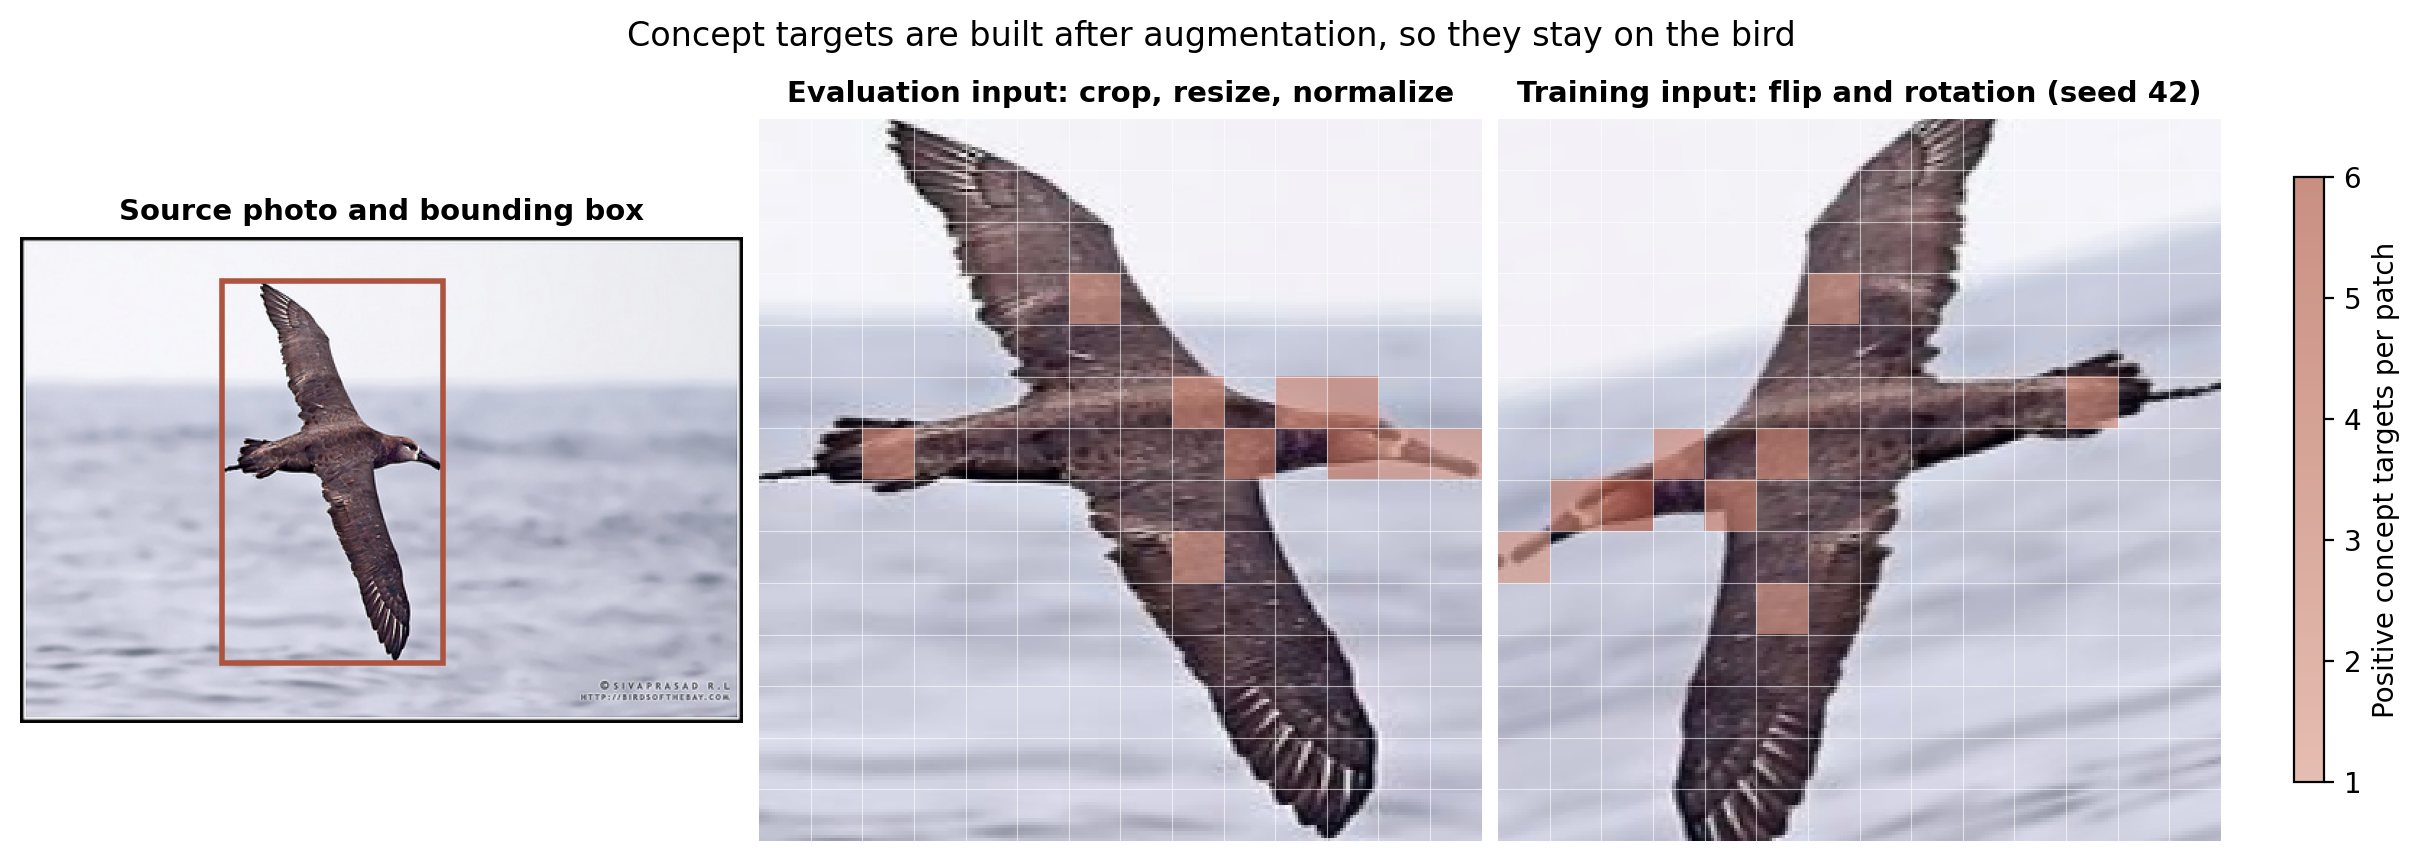

In [9]:
# Live: one training image through the repository's preprocessing, with the concept targets it produces.
SAMPLE_INDEX = 0  # position in the official training set, 0 to len(train_set) - 1
AUG_SEED = 42  # seed for the random flip and rotation

import random
import torch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator
from PIL import Image
from data import CUB2011Parts, CUB2011Parts_dataset

torch.set_num_threads(CPU_THREADS)
DATASET_DIR = DATA_DIR / "CUB_200_2011"
assert (DATASET_DIR / "cropped").is_dir(), "No crop cache: the dataset would start writing crops. See 3.4."
data_module = CUB2011Parts(data_dir=str(DATA_DIR), batch_size=2, num_workers=0)  # holds both transforms
train_set = CUB2011Parts_dataset(root=str(DATA_DIR), train=True, crop=True, download=False)
assert 0 <= SAMPLE_INDEX < len(train_set), f"SAMPLE_INDEX must be below {len(train_set)}"
sample_meta = train_set.data.iloc[SAMPLE_INDEX]


def fetch(transform, seed=None):
    """The sample through one transform; a seed fixes the random flip and rotation, then the RNGs are restored."""
    saved = random.getstate(), np.random.get_state()
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
    train_set.transform = transform
    try:
        return train_set[SAMPLE_INDEX]
    finally:
        random.setstate(saved[0])
        np.random.set_state(saved[1])


def to_rgb(image):
    """Undo the ImageNet normalization for display."""
    mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
    return np.clip(image.permute(1, 2, 0).numpy() * std + mean, 0, 1)


def patch_targets(spatial):
    """(196, 95) targets to a 14 x 14 grid: which patches carry targets, and positives per patch."""
    known = torch.isfinite(spatial).any(dim=1).numpy().reshape(14, 14)
    positives = torch.nan_to_num(spatial, nan=0.0).sum(dim=1).numpy().reshape(14, 14)
    return known, positives


eval_image, eval_global, eval_spatial, class_target = fetch(data_module.test_transform)
aug_image, _, aug_spatial, _ = fetch(data_module.train_transform, seed=AUG_SEED)
with Image.open(DATASET_DIR / "images" / sample_meta.filepath) as photo:
    source_rgb = photo.convert("RGB")

eval_known, eval_positives = patch_targets(eval_spatial)
aug_known, aug_positives = patch_targets(aug_spatial)
cmap = LinearSegmentedColormap.from_list("targets", ["#d99a88", PALETTE["accent"]])
vmax = max(2.0, float(eval_positives.max()), float(aug_positives.max()))  # at least two colour steps
fig, axes = plt.subplots(1, 3, figsize=(12, 4.4), constrained_layout=True)
axes[0].imshow(source_rgb)
axes[0].add_patch(Rectangle((sample_meta.x1, sample_meta.y1), sample_meta.w, sample_meta.h,
                            fill=False, edgecolor=PALETTE["accent"], linewidth=2))
axes[0].set_title("Source photo and bounding box", fontsize=10.5)
panels = [(axes[1], eval_image, eval_known, eval_positives, "Evaluation input: crop, resize, normalize"),
          (axes[2], aug_image, aug_known, aug_positives, f"Training input: flip and rotation (seed {AUG_SEED})")]
for ax, image, known, positives, title in panels:
    ax.imshow(to_rgb(image))
    overlay = ax.imshow(np.ma.masked_where(~known, positives), cmap=cmap, vmin=1, vmax=vmax, alpha=0.65,
                        extent=(-0.5, 223.5, 223.5, -0.5), interpolation="nearest")
    for k in range(1, 14):  # the 14 x 14 grid of 16-pixel patches the spatial concepts live on
        ax.axhline(16 * k - 0.5, color="white", linewidth=0.4, alpha=0.6)
        ax.axvline(16 * k - 0.5, color="white", linewidth=0.4, alpha=0.6)
    ax.set_title(title, fontsize=10.5)
for ax in axes:
    ax.axis("off")
fig.colorbar(overlay, ax=list(axes[1:]), shrink=0.75, ticks=MaxNLocator(integer=True),
             label="Positive concept targets per patch")
fig.suptitle("Concept targets are built after augmentation, so they stay on the bird")
plt.show()

attribute_names = pd.read_csv(DATASET_DIR / "attributes.txt", sep=" ", names=["attr_id", "definition"]).set_index("attr_id").definition
global_present = [attribute_names[train_set.non_spatial_attributes_pos[i]].replace("has_", "").replace("::", ": ").replace("_", " ")
                  for i in np.flatnonzero(eval_global.numpy() == 1)]
species = train_set.class_names[int(class_target)].split(".", 1)[-1].replace("_", " ")
caption(f"<b>Figure 3.1</b> {species}, training image {SAMPLE_INDEX}. Shaded cells are patches with spatial "
        f"concept targets: {int(eval_known.sum())} of {eval_known.size} in the evaluation input, "
        f"{int(aug_known.sum())} after augmentation; colour counts the positive concepts per patch. "
        "An unshaded patch has no target (NaN), which is not the same as a negative one. "
        f"Global concepts annotated present: {', '.join(global_present) or 'none'}.")

### 3.4 Data issues

| Issue | Origin | Handling |
| --- | --- | --- |
| `attributes.txt` extracts one folder above where the loader [reads it](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L176-L179) | Archive layout vs. repository loader | Copy it inward, keep the original, check the bytes match |
| A partial crop cache goes unnoticed | Repository: cropping is [skipped whenever `cropped/` exists](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L76-L80) | Check every expected crop path before training |
| Some attribute rows carry a surplus trailing field | Official annotations | Keep the file; the pinned pandas still reads the ID and presence fields the model uses |
| A few bounding boxes extend past their image | Official annotations | Keep the boxes; the repository's Pillow crop pads them with black pixels |

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; re-checks the files on disk, read-only</span></div>

In [11]:
# Live: re-check each data issue against the files on disk (read-only), beside the saved audit counts.
import hashlib

DATASET_DIR = DATA_DIR / "CUB_200_2011"
source_audit = json.loads((SETUP_LOGS / "cub-download.json").read_text())
crop_audit = json.loads((SETUP_LOGS / "cub-cropping.json").read_text())


def unchanged(relative_path):
    """True when an annotation file still matches the SHA-256 recorded by the source audit."""
    digest = hashlib.sha256((DATASET_DIR / relative_path).read_bytes()).hexdigest()
    return digest == source_audit["annotation_sha256"][relative_path]


outer_attributes, inner_attributes = DATA_DIR / "attributes.txt", DATASET_DIR / "attributes.txt"
attributes_ok = (inner_attributes.is_file() and outer_attributes.is_file()
                 and inner_attributes.read_bytes() == outer_attributes.read_bytes())
image_paths = pd.read_csv(DATASET_DIR / "images.txt", sep=" ", names=["image_id", "path"]).path
crops_present = sum((DATASET_DIR / "cropped" / path).is_file() for path in image_paths)
surplus_rows = source_audit["attributes"]["source_rows_with_surplus_zero_token"]
surplus_images = sorted(source_audit["attributes"]["surplus_token_image_id_counts"], key=int)
boxes = source_audit["images"]
fact_table([
    ("attributes.txt in the loader's folder",
     "present and byte-identical to the archive copy" if attributes_ok else "MISSING or different: copy it before training"),
    ("Crop cache",
     f"{crops_present:,} of {len(image_paths):,} expected crops on disk now; the full crop audit decoded "
     f"{crop_audit['fully_decoded_count']:,}" + (" in the source copy" if Path(crop_audit["data_root"]) != DATA_DIR else "")),
    ("Attribute rows with a surplus field",
     f"{surplus_rows:,} rows, all in images {' and '.join(surplus_images)}; file "
     + ("unchanged since the audit" if unchanged("attributes/image_attribute_labels.txt") else "CHANGED since the audit")),
    ("Boxes extending past their image",
     f"{boxes['bounding_boxes_beyond_image_plus_one_pixel']} of {boxes['bounding_boxes_positive_finite']:,}, "
     "by more than one pixel; file "
     + ("unchanged since the audit" if unchanged("bounding_boxes.txt") else "CHANGED since the audit")),
], title="Data issues, checked now")

### 3.5 Validation split

<div style="border-top: 3px solid #ac543f; background: rgba(172, 84, 63, 0.07); padding: 12px 18px 14px 18px;"><div style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65; margin-bottom: 6px;">Key point</div><div style="font-family: Newsreader, Georgia, serif; font-size: 21px; line-height: 1.4;">The repository chooses its checkpoint on images it later tests on.</div></div>

Its `setup()` [draws the validation set at random from the official test split](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L38-L51), then tests on the whole split. The paper describes no validation split for CUB. This is naturally problematic becasue it chooses a checkpoint that favours the test set. So we kept this protocol as the like-for-like run and trained a second run on a disjoint split, with every other setting unchanged.

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; runs the repository's own <code>setup()</code> &middot; change <code>SEED</code>: the overlap stays the same</span></div>

In [12]:
# Live: run the repository's CUB2011Parts.setup() and count validation images that are also test images.
SEED = 0  # torch seed for random_split; every seed gives the same overlap
UPSTREAM_SHA256 = "b6f1b6f3239718e445b167a94a52395693f3ac3e80786548023a7e86d25021d0"  # data/cub2011parts_datamodule.py at commit 84c9c30

import hashlib
import inspect
import torch
from data import CUB2011Parts

torch.set_num_threads(CPU_THREADS)
assert (DATA_DIR / "CUB_200_2011" / "cropped").is_dir(), "No crop cache: the dataset would start writing crops. See 3.4."
torch.manual_seed(SEED)
repo_module = CUB2011Parts(data_dir=str(DATA_DIR), batch_size=32, num_workers=0)
repo_module.setup()  # stage None builds the training, validation and test sets
val_subset = repo_module.cub_val
val_ids = set(val_subset.dataset.data.img_id.iloc[val_subset.indices])
test_ids = set(repo_module.cub_test.data.img_id)
train_ids = set(repo_module.cub_train.data.img_id)
stat_row([
    {"label": "Validation images", "value": f"{len(val_ids):,}",
     "detail": "drawn by random_split from the official test split", "color": "neg"},
    {"label": "Also in the final test set", "value": f"{len(val_ids & test_ids):,}",
     "detail": f"the test set is all {len(test_ids):,} official test images", "color": "warn"},
    {"label": "Shared with training", "value": f"{len(val_ids & train_ids):,}",
     "detail": "training images stay separate", "color": "pos"},
])
module_file = Path(inspect.getsourcefile(CUB2011Parts))
pinned = hashlib.sha256(module_file.read_bytes()).hexdigest() == UPSTREAM_SHA256
split_line = next((line.strip() for line in inspect.getsource(CUB2011Parts.setup).splitlines()
                   if "random_split(" in line), "no random_split call found")
print(f"{module_file.name} is {'identical to' if pinned else 'DIFFERENT from'} the pinned upstream file.")
print("CUB2011Parts.setup():", split_line)

cub2011parts_datamodule.py is identical to the pinned upstream file.
CUB2011Parts.setup(): self.cub_val, _ = random_split(testset, [1000, len(testset) - 1000])


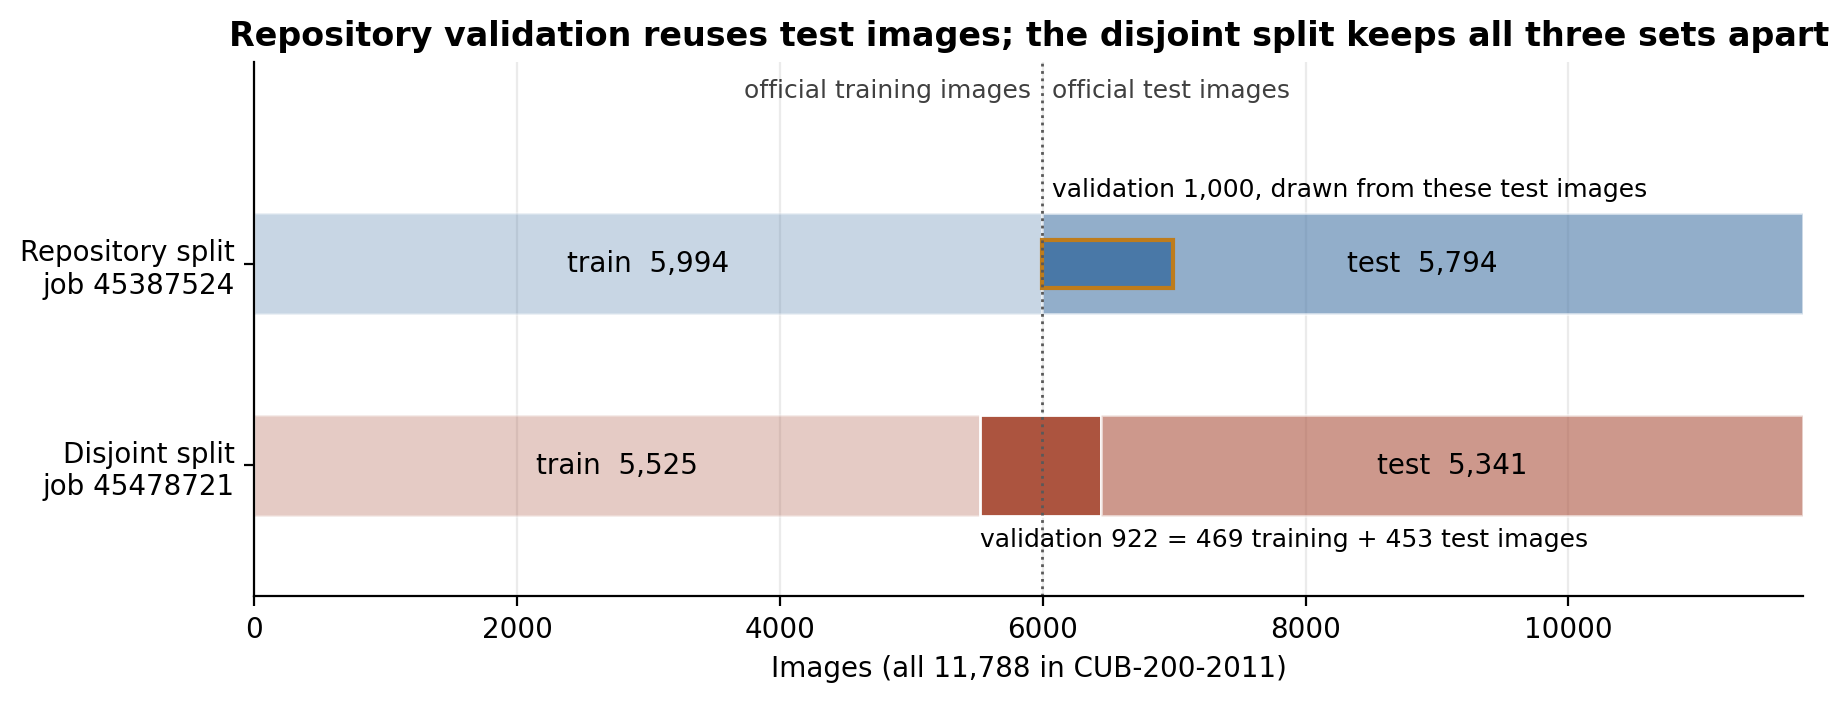

In [13]:
# Evidence: where each completed run drew its images, read from the saved run records.
official = json.loads((SETUP_LOGS / "cub-download.json").read_text())["split_counts"]  # official train / test pools
repo_sizes = RUNS[REPO_RUN]["snapshot"]["dataset_sizes"]
split = RUNS[DISJOINT_RUN]["run"]["split"]
disjoint_sizes, from_pool = split["counts"], split["validation_origin_counts"]
assert repo_sizes["train"] == official["train"] and repo_sizes["test"] == official["test"]
assert str(repo_sizes["validation"]) in RUNS[REPO_RUN]["snapshot"]["split_limitation"]  # "overlap: N image IDs"
assert disjoint_sizes == RUNS[DISJOINT_RUN]["snapshot"]["dataset_sizes"]
assert disjoint_sizes["train"] + from_pool["official_train"] == official["train"]
assert disjoint_sizes["test"] + from_pool["official_test"] == official["test"]
assert split["manifest_sha256"] == EVIDENCE["disjoint_training_job"]["manifest_sha256"]
total = official["train"] + official["test"]
assert sum(disjoint_sizes.values()) == total
ROLE_ALPHA = {"train": 0.30, "validation": 1.0, "test": 0.60}  # solid = validation, the set that picks the checkpoint
rows = [
    (1, REPO_RUN, [(0, official["train"], "train"), (official["train"], official["test"], "test")]),
    (0, DISJOINT_RUN, [(0, disjoint_sizes["train"], "train"),
                       (disjoint_sizes["train"], disjoint_sizes["validation"], "validation"),
                       (official["train"] + from_pool["official_test"], disjoint_sizes["test"], "test")]),
]
fig, ax = plt.subplots(figsize=(9, 3.4), constrained_layout=True)
for y, job, segments in rows:
    for start, width, role in segments:
        ax.barh(y, width, left=start, height=0.5, color=RUN_COLOR[job], alpha=ROLE_ALPHA[role],
                edgecolor="white", linewidth=1)
        if role != "validation":
            ax.text(start + width / 2, y, f"{role}  {width:,}", ha="center", va="center", fontsize=10)
ax.barh(1, repo_sizes["validation"], left=official["train"], height=0.24, color=RUN_COLOR[REPO_RUN],
        edgecolor=PALETTE["warn"], linewidth=1.5)  # the repository's validation set sits inside its test set
ax.text(official["train"] + 80, 1.31, f"validation {repo_sizes['validation']:,}, drawn from these test images",
        ha="left", va="bottom", fontsize=9)
ax.text(disjoint_sizes["train"], -0.31,
        f"validation {disjoint_sizes['validation']:,} = {from_pool['official_train']} training + "
        f"{from_pool['official_test']} test images", ha="left", va="top", fontsize=9)
ax.axvline(official["train"], color="0.35", linestyle=":", linewidth=1)
ax.text(official["train"] - 80, 1.8, "official training images", ha="right", va="bottom", fontsize=9, alpha=0.75)
ax.text(official["train"] + 80, 1.8, "official test images", ha="left", va="bottom", fontsize=9, alpha=0.75)
ax.set_yticks([0, 1])
ax.set_yticklabels([f"{RUN_LABEL[job]}\njob {job}" for job in (DISJOINT_RUN, REPO_RUN)])
ax.set(xlim=(0, total), ylim=(-0.65, 2.0), xlabel=f"Images (all {total:,} in CUB-200-2011)",
       title="Repository validation reuses test images; the disjoint split keeps all three sets apart")
ax.grid(False, axis="y")
ax.set_axisbelow(True)
plt.show()
caption(f"<b>Figure 3.2</b> Where each completed run's images come from. Repository split: its "
        f"{repo_sizes['validation']:,} validation images are drawn from the {official['test']:,} official test "
        "images, which are all tested again. Disjoint split: pairwise overlaps are "
        + ", ".join(f"{pair.replace('_', '–')} {count}" for pair, count in split["pairwise_overlap_counts"].items())
        + f"; its image IDs are fixed in <code>split_manifest.json</code> (SHA-256 {split['manifest_sha256'][:12]}…, "
        f"split seed {split['split_seed']}).")

<details><summary style="cursor: pointer; font-size: 15px;"><b>Backup:</b> how the disjoint split was built</summary>

- Keep the repository's train : validation : test proportions, renormalized over unique images (the repository counts its validation images twice), with largest-remainder rounding.
- Reserve the validation images per class from both official pools. Training then uses only official training images, and the final test only official test images.
- Generate the split once with a fixed seed and save the image IDs in `split_manifest.json`. The training run and the explanation script read that manifest instead of re-splitting inside `setup()`.
- Model, losses, optimizer, schedule, preprocessing and hyperparameters match the repository run. The checkpoint is chosen on validation cross-entropy and tested once.

</details>

<div style="border-top: 1px solid rgba(128, 128, 128, 0.45); padding-top: 10px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65;">Walkthrough · about 2 min</span></div>

## <span style="font-family: Newsreader, Georgia, serif; font-size: 34px; font-weight: 400;">4. Training Run</span>

<div style="font-size: 19px; line-height: 1.5; max-width: 44em;">Two commands took the repository code from a one-batch check on CPU to two full 50-epoch runs on one L4 GPU, with the repository's own hyperparameters. The curves show how training behaved and which epoch each run kept.</div>

### 4.1 Commands

A debug run on CPU came first. It pushes two images through the full model, both concept losses, a backward pass and one optimizer step, then one validation and one test batch, so a broken pipeline fails before any GPU time is spent. Full training then ran as a Slurm job on one L4.

<div><div style="display: inline-block; vertical-align: top; width: 47%; margin-right: 4%; border-top: 3px solid rgba(128, 128, 128, 0.45); padding-top: 8px;"><div style="font-family: Newsreader, Georgia, serif; font-size: 22px; margin-bottom: 4px;">CPU debug check</div><div style="font-size: 15px; line-height: 1.5;"><code>python scripts/run_debug.py</code><br>Runs <code>cvit_cub.py --debug --batch_size 2 --num_workers 0</code>, which is Lightning's <code>fast_dev_run</code>: one training, one validation and one test batch.</div></div><div style="display: inline-block; vertical-align: top; width: 47%; border-top: 3px solid rgba(128, 128, 128, 0.45); padding-top: 8px;"><div style="font-family: Newsreader, Georgia, serif; font-size: 22px; margin-bottom: 4px;">L4 training</div><div style="font-size: 15px; line-height: 1.5;"><code>sbatch scripts/train_l4.sbatch</code><br>Requests one L4 on <code>hpg-turin</code> with 4 CPUs and 32 GB and checks one CUDA mixed-precision step. It then runs <code>cvit_cub.py</code> for 50 epochs at batch size 32 through <code>scripts/run_training.py</code>, which adds batch timing. It fails rather than fall back to CPU.</div></div></div>

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> · set <code>RERUN_DEBUG = True</code> for a fresh one-batch CPU run (needs the cached ViT weights)</span></div>

In [14]:
# CPU debug check: the recorded run by default, or a fresh one-batch run of the full model.
import hashlib
import subprocess

RERUN_DEBUG = False  # True: run scripts/run_debug.py now on CPU; rewrites training_runs/debug/
N_CLASSES = 200  # CUB-200-2011 species; an untrained classifier scores cross-entropy ln(200)


def sha256_of(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


if RERUN_DEBUG:
    assert any((PROJECT_DIR / ".cache" / "torch" / "hub" / "checkpoints").glob("*.npz")), "Prepare the cached ViT weights first."
    assert (PROJECT_DIR / "CUB-200-2011" / "CUB_200_2011").is_dir(), "run_debug.py reads CUB-200-2011/ inside PROJECT_DIR."
    subprocess.run([sys.executable, str(PROJECT_DIR / "scripts" / "run_debug.py")], cwd=str(PROJECT_DIR), check=True)
    debug = json.loads((PROJECT_DIR / "training_runs" / "debug" / "run.json").read_text())
else:
    debug = EVIDENCE["presentation_debug_evidence"]
assert debug["success"] and debug["returncode"] == 0

# The record's hashes name the code the check exercised; compare them with this checkout.
hash_checks = [
    ("cvit_cub.py", debug["entrypoint_sha256"], REPO_DIR / "cvit_cub.py"),
    ("ctc/ctc_model.py", debug["runtime_sha256"], REPO_DIR / "ctc" / "ctc_model.py"),
    ("uv.lock", debug["lock_sha256"], PROJECT_DIR / "uv.lock"),
]
same_code = ", ".join(
    "{} {}".format(name, "matches" if recorded == sha256_of(path) else "DIFFERS") for name, recorded, path in hash_checks
)
run_root = str(Path(debug["command"][0]).parents[2])  # the project copy the check ran in
metrics = debug["test_metrics"]
fact_table([
    ("Command (paths relative to the project)", " ".join(part.replace(run_root, ".") for part in debug["command"])),
    ("Host, Python", "{} · Python {}".format(debug["hostname"], debug["python"])),
    ("Lightning mode", debug["mode"]),
    ("Elapsed, including model load", "{:.1f} s · exit code {}".format(debug["elapsed_seconds"], debug["returncode"])),
    ("Code it ran vs. this checkout", same_code),
    ("Test metrics on two images", "accuracy {:.2f} · CE {:.3f} (chance: ln {} = {:.3f}) · explanation {:.3f} · concentration {:.3f}".format(
        metrics["test_acc"], metrics["test_ce_loss"], N_CLASSES, np.log(N_CLASSES),
        metrics["test_expl_loss"], metrics["test_l1_loss"])),
], title="CPU debug check · " + ("fresh run" if RERUN_DEBUG else "recorded run"))

In [15]:
# L4 training: what Slurm recorded for both runs, and the batch script as submitted.
import hashlib
import subprocess

SHOW_FULL_SCRIPT = False  # True prints the whole batch script, not only its resource lines and launch command

script = PROJECT_DIR / "scripts" / "train_l4.sbatch"
subprocess.run(["bash", "-n", str(script)], check=True)  # syntax check only; nothing is submitted
submission = json.loads((SETUP_LOGS / "slurm-submission.json").read_text())  # the repository-split job
disjoint_job = EVIDENCE["disjoint_training_job"]  # the disjoint-split job, submitted from its run bundle
assert submission["job_id"] == REPO_RUN and disjoint_job["job_id"] == DISJOINT_RUN

stats = []
for job in (REPO_RUN, DISJOINT_RUN):
    snap = RUNS[job]["snapshot"]
    slurm = snap["scheduler"]
    assert slurm["State"] == "COMPLETED" and slurm["ExitCode"] == "0:0"
    stats.append({
        "label": "{} · Slurm elapsed".format(RUN_LABEL[job]),
        "value": slurm["Elapsed"],
        "detail": "job {} · {}, exit {} · {} epochs · {:,} batches".format(
            job, slurm["State"], slurm["ExitCode"], snap["complete_epochs"], snap["train_batches"]),
        "color": RUN_COLOR[job],
    })
stat_row(stats)

commands = [RUNS[job]["run"]["command"] for job in (REPO_RUN, DISJOINT_RUN)]
run_root = str(Path(commands[0][0]).parents[2])  # the Blue working copy the jobs ran in
runner_today = hashlib.sha256((PROJECT_DIR / "scripts" / "run_training.py").read_bytes()).hexdigest()
request = disjoint_job["resource_request"]
fact_table([
    ("Submitted, repository split", " ".join(submission["command"])),
    ("Submitted, disjoint split", " ".join(disjoint_job["command"])),
    ("Repository command inside the job", " ".join(part.replace(run_root, ".") for part in commands[0])
        + (" (same in both runs)" if commands[0] == commands[1] else " (differs between runs)")),
    ("Resources", "{} · {} · {} CPUs · {} memory · time limit {} / {}".format(
        submission["partition"], submission["gres"], submission["cpus"], submission["host_memory"],
        submission["walltime"], request["time_limit"])),
    ("Batch script vs. this checkout",
        "matches" if hashlib.sha256(script.read_bytes()).hexdigest() == submission["script_sha256"] else "DIFFERS"),
    ("Runner vs. this checkout", ", ".join(
        "{} {}".format(RUN_LABEL[job], "matches" if RUNS[job]["run"]["runner_sha256"] == runner_today else "DIFFERS")
        for job in (REPO_RUN, DISJOINT_RUN))),
], title="L4 jobs")

lines = script.read_text().splitlines()
launch = next(i for i, line in enumerate(lines) if "run_training.py" in line)
shown = lines if SHOW_FULL_SCRIPT else [line for line in lines if line.startswith("#SBATCH")] + ["..."] + lines[launch:]
print("\n".join(shown))

#SBATCH --job-name=concept-cub-l4
#SBATCH --account=cruzalmeida
#SBATCH --qos=cruzalmeida
#SBATCH --partition=hpg-turin
#SBATCH --gres=gpu:l4:1
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=4
#SBATCH --mem=32G
#SBATCH --time=24:00:00
#SBATCH --output=training_runs/slurm-%j.out
#SBATCH --error=training_runs/slurm-%j.err
#SBATCH --export=NONE
...
srun --ntasks=1 "$PYTHON" scripts/run_training.py \
    --run-dir "training_runs/l4-${SLURM_JOB_ID}" \
    --batch-size 32 --max-epochs 50 --num-workers 2 --require-cuda


### 4.2 Hyperparameters

We kept every repository default, so the runs test the published configuration rather than our tuning. Two runtime settings changed. The loader uses 2 workers instead of 8 to fit the 4-CPU allocation. The repository's FP16 mixed precision now runs through PyTorch's native AMP instead of NVIDIA Apex (Section 2). The checkpoint kept for testing is the epoch with the lowest validation cross-entropy, which is the repository's own rule.

In [16]:
# Repository defaults, read from the argparse calls in cvit_cub.py, against what each run recorded.
import ast

SETTINGS = [  # (argument, label), in the order shown
    ("learning_rate", "Learning rate"),
    ("weight_decay", "Weight decay"),
    ("warmup", "Warmup epochs, then cosine decay"),
    ("max_epochs", "Epochs"),
    ("batch_size", "Batch size"),
    ("expl_lambda", "Explanation loss weight"),
    ("attention_sparsity", "Attention concentration weight"),
    ("seed", "Seed"),
    ("num_workers", "Data-loader workers"),
]
defaults = {}
for node in ast.walk(ast.parse((REPO_DIR / "cvit_cub.py").read_text())):
    if isinstance(node, ast.Call) and getattr(node.func, "attr", "") == "add_argument":
        options = {keyword.arg: keyword.value for keyword in node.keywords}
        if "default" in options:
            defaults[node.args[0].value.lstrip("-")] = ast.literal_eval(options["default"])

assert EVIDENCE["completed_run_comparison"]["checks"]["shared_hyperparameters_equal"]
jobs = (REPO_RUN, DISJOINT_RUN)
recorded = {job: RUNS[job]["hyperparameters"] for job in jobs}
table = pd.DataFrame(
    [[defaults[key]] + [recorded[job][key] for job in jobs] for key, _ in SETTINGS],
    index=[label for _, label in SETTINGS],
    columns=["Repository default"] + [RUN_LABEL[job] for job in jobs],
).applymap("{:g}".format)
changed = [label for key, label in SETTINGS if any(recorded[job][key] != defaults[key] for job in jobs)]
display(table.style.apply(
    lambda row: ["background: rgba(190, 124, 28, 0.15)" if row.name in changed else "" for _ in row], axis=1))
rules = {RUNS[job]["snapshot"]["checkpoint_selection"] for job in jobs}
print("Changed from the defaults:", ", ".join(changed) or "nothing")
print("Checkpoint kept for testing, both runs:", " / ".join(sorted(rules)))

,Repository default,Repository split,Disjoint split
Learning rate,5e-05,5e-05,5e-05
Weight decay,0.001,0.001,0.001
"Warmup epochs, then cosine decay",10,10,10
Epochs,50,50,50
Batch size,32,32,32
Explanation loss weight,1,1,1
Attention concentration weight,0.5,0.5,0.5
Seed,42,42,42
Data-loader workers,8,2,2


Changed from the defaults: Data-loader workers
Checkpoint kept for testing, both runs: minimum val_ce_loss


### 4.3 Learning curves

Both runs trained the same way. Accuracy rises slowly during the 10-epoch learning-rate warmup, fastest just after it, and levels off in the second half. Validation cross-entropy reaches its minimum mid-run and then creeps up while the training loss keeps falling. The checkpoint rule therefore keeps a mid-run epoch, not the last one.

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> · change <code>EPOCH_RANGE</code>, e.g. <code>(20, 50)</code>, or drop a run from <code>SHOW_JOBS</code>, and re-run</span></div>

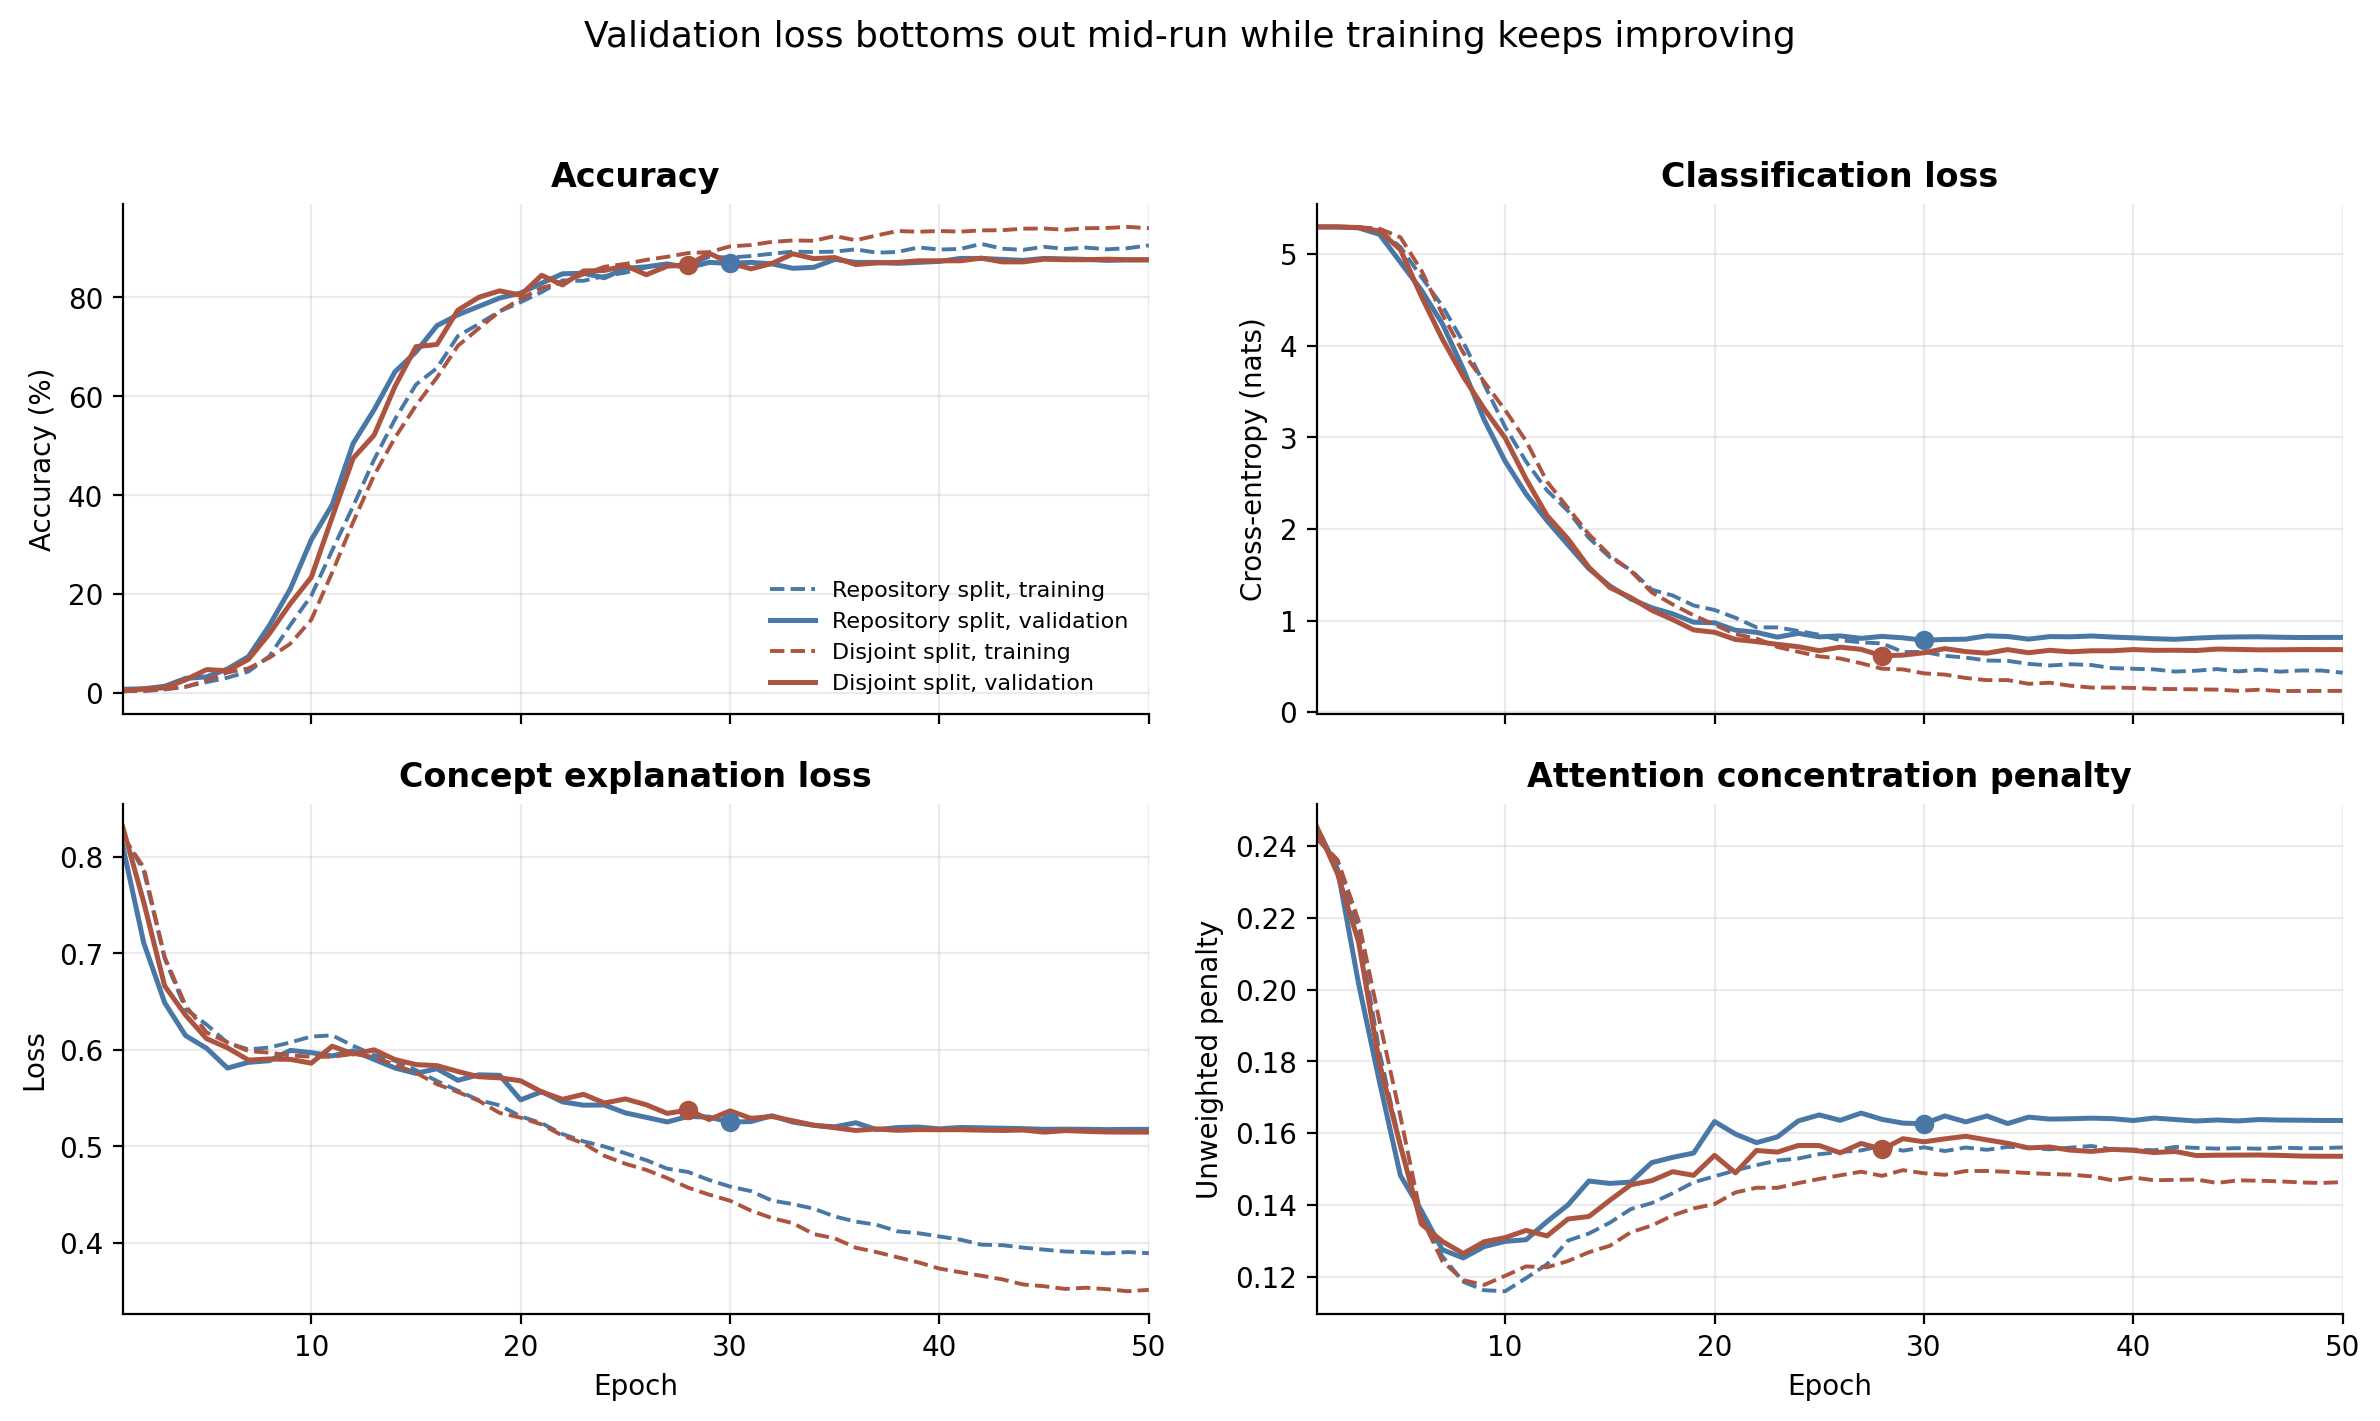

In [17]:
# Figure 4.1: per-epoch curves of both runs, read from the verified TensorBoard records.
SHOW_JOBS = (REPO_RUN, DISJOINT_RUN)  # drop one to show a single run
EPOCH_RANGE = (1, 50)  # first and last epoch shown; e.g. (20, 50) to watch validation CE turn upward

PANELS = [  # (metric suffix, panel title, y-axis label, scale)
    ("acc", "Accuracy", "Accuracy (%)", 100),
    ("ce_loss", "Classification loss", "Cross-entropy (nats)", 1),
    ("expl_loss", "Concept explanation loss", "Loss", 1),
    ("l1_loss", "Attention concentration penalty", "Unweighted penalty", 1),
]
curves = {job: pd.DataFrame(RUNS[job]["epochs"]).set_index("epoch").sort_index() for job in SHOW_JOBS}
kept = {job: int(RUNS[job]["snapshot"]["best_validation_epoch"]) for job in SHOW_JOBS}
for job in SHOW_JOBS:  # the kept epoch is the validation-CE minimum, and training CE keeps falling after it
    assert kept[job] == int(curves[job].val_ce_loss.idxmin())
    assert curves[job].train_ce_loss.iloc[-1] < curves[job].train_ce_loss[kept[job]]

fig, axes = plt.subplots(2, 2, figsize=(12, 7.2), sharex=True)
for ax, (metric, title, ylabel, scale) in zip(axes.flat, PANELS):
    for job in SHOW_JOBS:
        shown = curves[job].loc[EPOCH_RANGE[0]:EPOCH_RANGE[1]]
        ax.plot(shown.index, scale * shown["train_" + metric], color=RUN_COLOR[job], linestyle="--", linewidth=1.4,
                label="{}, training".format(RUN_LABEL[job]))
        ax.plot(shown.index, scale * shown["val_" + metric], color=RUN_COLOR[job], linewidth=1.8,
                label="{}, validation".format(RUN_LABEL[job]))
        if EPOCH_RANGE[0] <= kept[job] <= EPOCH_RANGE[1]:
            ax.scatter([kept[job]], [scale * curves[job].loc[kept[job], "val_" + metric]],
                       color=RUN_COLOR[job], s=36, zorder=5)
    ax.set(title=title, ylabel=ylabel, xlim=EPOCH_RANGE)
for ax in axes[1]:
    ax.set_xlabel("Epoch")
axes[0, 0].legend(fontsize=8, loc="lower right")
fig.suptitle("Validation loss bottoms out mid-run while training keeps improving", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

warmup = RUNS[SHOW_JOBS[0]]["hyperparameters"]["warmup"]
caption(
    "<b>Figure 4.1</b> Training (dashed) and validation (solid) metrics per epoch, from the saved TensorBoard records. "
    "Dots mark the checkpoint each run kept, its lowest validation CE: "
    + "; ".join("{} at epoch {} (validation CE {:.3f}; {:.3f} at the last epoch)".format(
        RUN_LABEL[job], kept[job], curves[job].loc[kept[job], "val_ce_loss"], curves[job].val_ce_loss.iloc[-1])
        for job in SHOW_JOBS)
    + ". The first {} epochs are learning-rate warmup. The concentration penalty is the logged ".format(warmup)
    + "<code>*_l1_loss</code>, an entropy-style term, shown unweighted."
)

In [18]:
# The kept checkpoint against the best-accuracy and last epochs, and the log lines where testing loads it.
rows = []
for job in (REPO_RUN, DISJOINT_RUN):
    curve = pd.DataFrame(RUNS[job]["epochs"]).set_index("epoch").sort_index()
    snap = RUNS[job]["snapshot"]
    kept_epoch = int(snap["best_validation_epoch"])
    assert abs(curve.loc[kept_epoch, "val_acc"] - snap["best_validation_metrics"]["val_acc"]) < 1e-9
    best = curve.val_acc.max()
    last = int(curve.index.max())
    rows.append({
        "Run": RUN_LABEL[job],
        "Kept epoch": kept_epoch,
        "Validation accuracy there (%)": 100 * curve.loc[kept_epoch, "val_acc"],
        "Best validation accuracy (%)": 100 * best,
        "Best at epoch(s)": ", ".join(str(epoch) for epoch in curve.index[curve.val_acc == best]),
        "Validation accuracy, epoch {} (%)".format(last): 100 * curve.loc[last, "val_acc"],
    })
selection = pd.DataFrame(rows).set_index("Run")
display(selection.style.format({name: "{:.2f}" for name in selection.columns if name.endswith("(%)")}))

for job in (REPO_RUN, DISJOINT_RUN):
    print("\nEnd of training, {} (job {}, stderr):".format(RUN_LABEL[job], job))
    print(RUNS[job]["stderr_completion_excerpt"].strip())
    print("Kept checkpoint:", RUNS[job]["snapshot"]["checkpoint_path"])

,Kept epoch,Validation accuracy there (%),Best validation accuracy (%),Best at epoch(s),"Validation accuracy, epoch 50 (%)"
Run,,,,,
Repository split,30,86.90,87.90,"41, 42, 45",87.60
Disjoint split,28,86.55,88.94,29,87.64



End of training, Repository split (job 45387524, stderr):
`Trainer.fit` stopped: `max_epochs=50` reached.
Restoring states from the checkpoint path at ./cub_cvit/CUB2011Parts_expl1.0/binary_mnist_best_ckpt.ckpt
Loaded model weights from checkpoint at ./cub_cvit/CUB2011Parts_expl1.0/binary_mnist_best_ckpt.ckpt
Kept checkpoint: /blue/yonghui.wu/zhangm3/concept_transformer_explain/training_runs/l4-45387524/cub_cvit/CUB2011Parts_expl1.0/binary_mnist_best_ckpt.ckpt

End of training, Disjoint split (job 45478721, stderr):
`Trainer.fit` stopped: `max_epochs=50` reached.
Restoring states from the checkpoint path at ./cub_cvit/CUB2011Parts_expl1.0/binary_mnist_best_ckpt.ckpt
Loaded model weights from checkpoint at ./cub_cvit/CUB2011Parts_expl1.0/binary_mnist_best_ckpt.ckpt
Kept checkpoint: /blue/yonghui.wu/zhangm3/concept_transformer_explain/training_runs/disjoint-proportional-seed42-20261010/l4-45478721/cub_cvit/CUB2011Parts_expl1.0/binary_mnist_best_ckpt.ckpt


<div style="border-top: 1px solid rgba(128, 128, 128, 0.45); padding-top: 10px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65;">Walkthrough &middot; about 3 min</span></div>

## <span style="font-family: Newsreader, Georgia, serif; font-size: 34px; font-weight: 400;">5. Results & Visualization</span>

<div style="font-size: 19px; line-height: 1.5; max-width: 44em;">How both runs score on their test images beside the paper's result, then what the concept explanations reveal about single predictions, right and wrong.</div>

### 5.1 Final test accuracy against the paper

Each run was tested once, with the checkpoint that had the lowest validation cross-entropy. The paper's CUB section describes no validation split, so the like-for-like comparison with its Table 1 is the repository-split run, which keeps the repository's own split and settings.

In [19]:
# Headline: test accuracy of both runs' selected checkpoints, beside the paper's reported CUB result.
PAPER_CT_ACCURACY = (88.0, 0.4)  # cited constant: Table 1 of 2647_attention_based_interpretabili.pdf, "CT", test accuracy (%)
# (Table 1 also reports 76.9 ± 3 for the same model trained without concepts, "CT [w/o]".)

from html import escape

paper_mean, paper_spread = PAPER_CT_ACCURACY
test_accuracy = {job: 100 * RUNS[job]["snapshot"]["test_metrics"]["test_acc"] for job in (REPO_RUN, DISJOINT_RUN)}
tiles = [{"label": "Paper · Table 1", "value": f"{paper_mean:.1f} ± {paper_spread:.1f}",
          "detail": "Concept Transformer on CUB, test accuracy (%)", "color": "rule"}]
for job in (REPO_RUN, DISJOINT_RUN):
    snapshot = RUNS[job]["snapshot"]
    tiles.append({
        "label": f"{RUN_LABEL[job]} · test accuracy",
        "value": f"{test_accuracy[job]:.2f}%",
        "detail": (f"{test_accuracy[job] - paper_mean:+.2f} points vs paper · epoch {snapshot['best_validation_epoch']}"
                   f" · {snapshot['dataset_sizes']['test']:,} test images"),
        "color": RUN_COLOR[job],
    })
stat_row(tiles)

gap = test_accuracy[REPO_RUN] - paper_mean
verdict = (f"Like for like, the repository-split run lands {abs(gap):.2f} percentage points "
           f"{'below' if gap < 0 else 'above'} the paper's {paper_mean:.1f}%, "
           f"{'inside' if abs(gap) <= paper_spread else 'outside'} its reported ±{paper_spread:.1f}, from one training seed.")
display(HTML(
    f'<div style="border-top: 3px solid {PALETTE["accent"]}; background: rgba(172, 84, 63, 0.07); '
    'padding: 12px 18px 14px 18px; margin-top: 18px;">'
    '<div style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65; margin-bottom: 6px;">'
    'Reproduction verdict</div>'
    f'<div style="font-family: Newsreader, Georgia, serif; font-size: 21px; line-height: 1.4;">{escape(verdict)}</div></div>'
))

In [20]:
# Evidence: each selected checkpoint's validation and test metrics, read from the saved run records.
metrics = {}
for job in (REPO_RUN, DISJOINT_RUN):
    snapshot = RUNS[job]["snapshot"]
    test, validation, sizes = snapshot["test_metrics"], snapshot["best_validation_metrics"], snapshot["dataset_sizes"]
    metrics[f"{RUN_LABEL[job]} ({job})"] = {
        "Selected epoch (lowest validation CE)": str(snapshot["best_validation_epoch"]),
        "Validation accuracy at that epoch": f"{100 * validation['val_acc']:.2f}%",
        "Test accuracy": f"{100 * test['test_acc']:.2f}%",
        "Test classification CE": f"{test['test_ce_loss']:.4f}",
        "Test explanation loss": f"{test['test_expl_loss']:.4f}",
        "Test attention-concentration penalty": f"{test['test_l1_loss']:.4f}",
        "Train / validation / test images": f"{sizes['train']:,} / {sizes['validation']:,} / {sizes['test']:,}",
    }
display(pd.DataFrame(metrics))

,Repository split (45387524),Disjoint split (45478721)
Selected epoch (lowest validation CE),30,28
Validation accuracy at that epoch,86.90%,86.55%
Test accuracy,87.33%,86.29%
Test classification CE,0.7376,0.6853
Test explanation loss,0.5344,0.5346
Test attention-concentration penalty,0.1626,0.1557
Train / validation / test images,"5,994 / 1,000 / 5,794","5,525 / 922 / 5,341"


### 5.2 Six test predictions, explained by their concepts

Six images from the disjoint run's test split, scored by its selected checkpoint. A fixed rule chose them, not us: the first three correct and the first three wrong predictions found at evenly spaced test positions. Each panel shows the spatial concept with the strongest attention in that image.

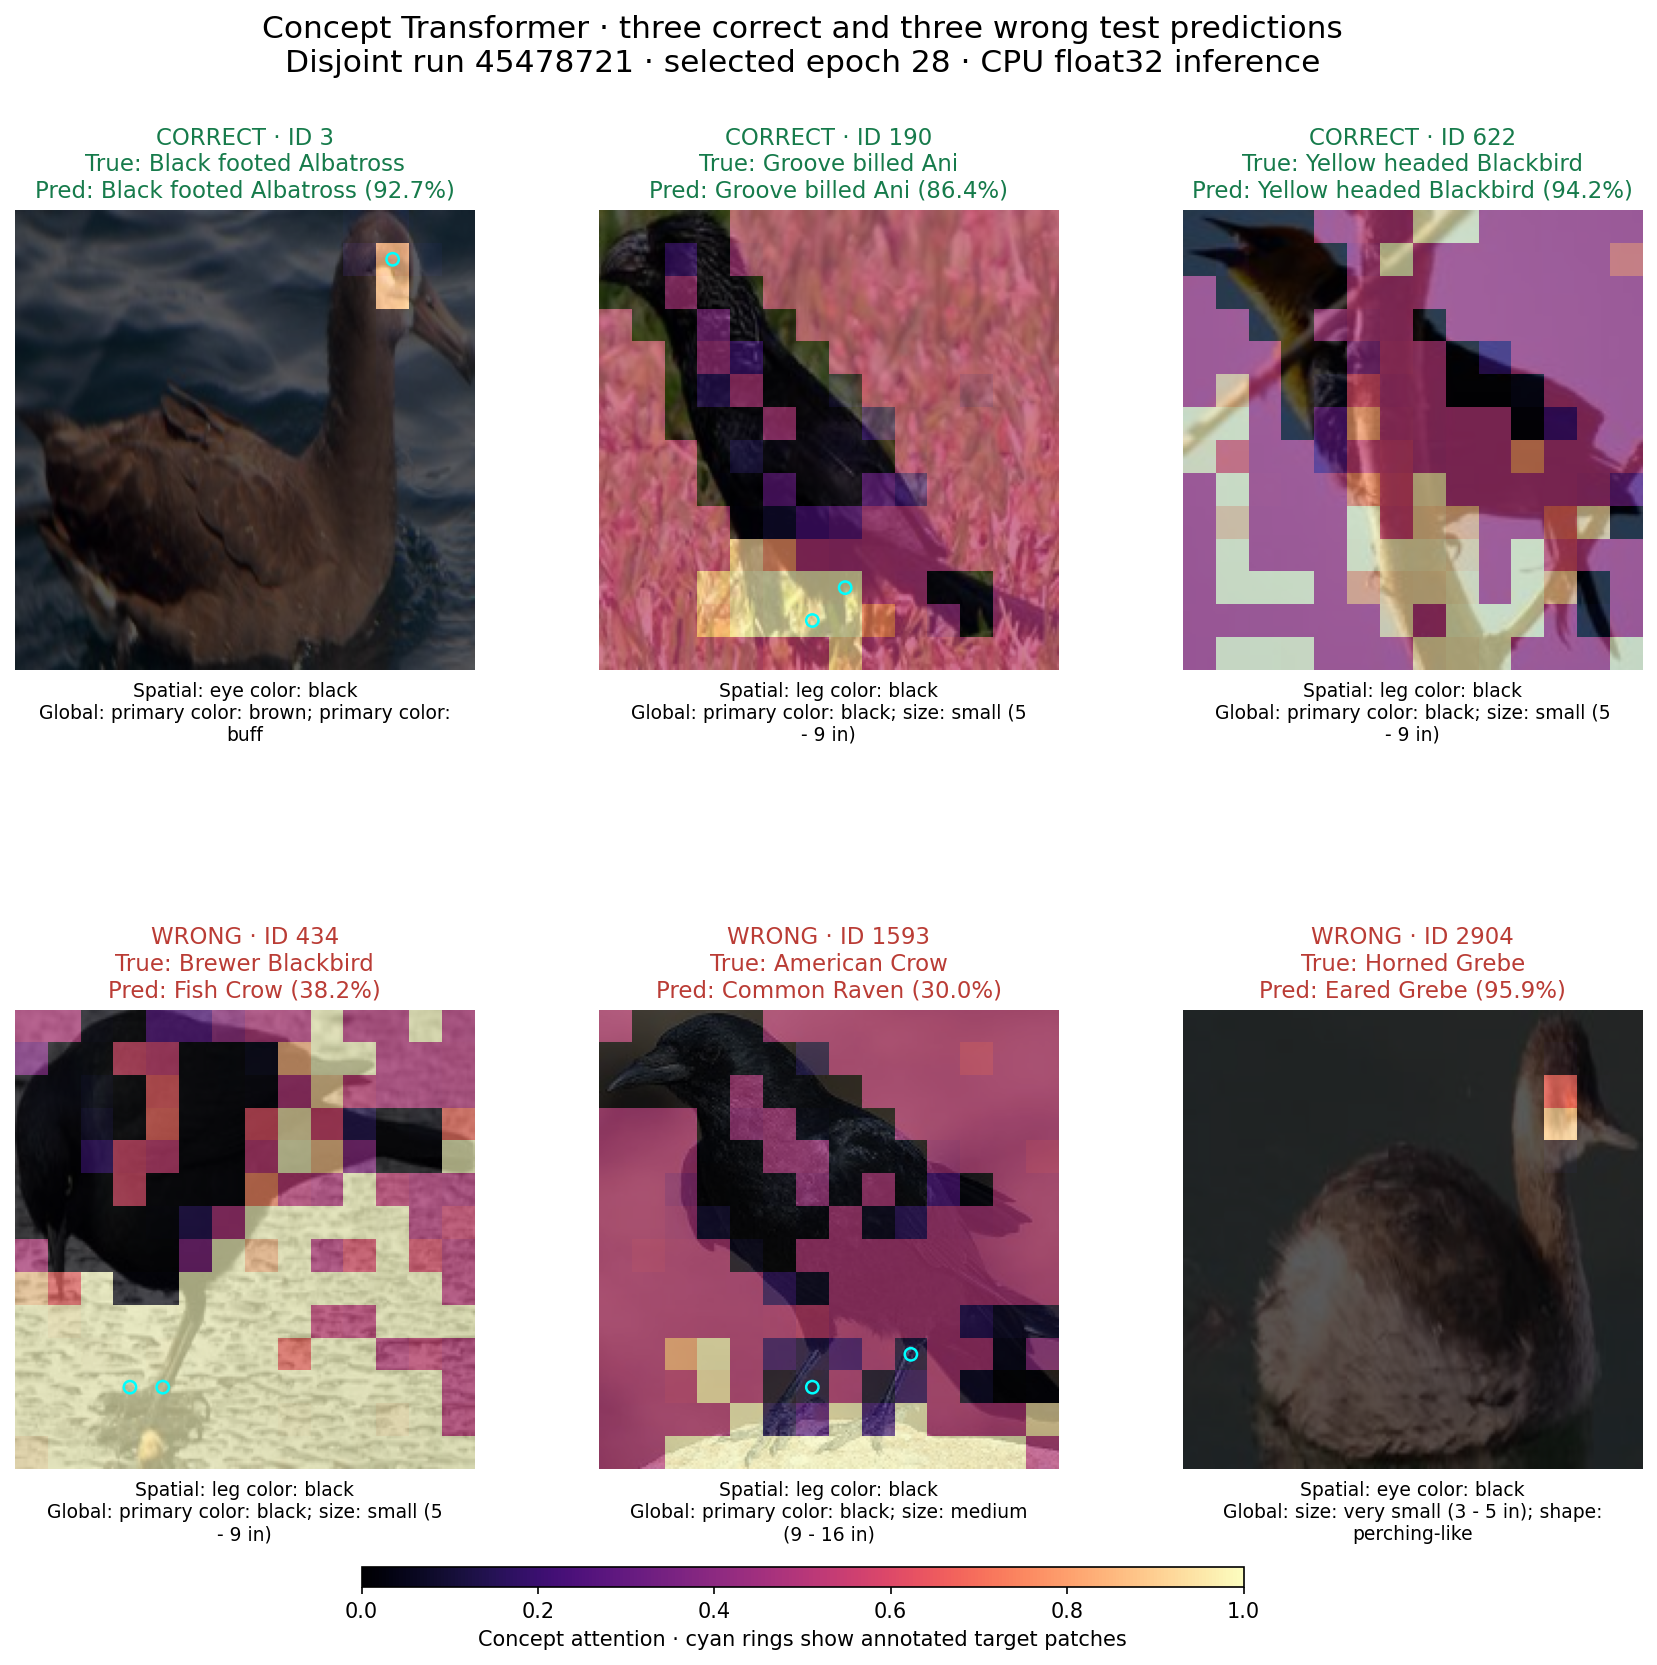

In [21]:
# All six cached examples at a glance, as rendered by scripts/visualize_test_explanations.py.
show_image(ARTIFACT_DIR / "overview.png", width=900, caption_text=(
    "<b>Figure 5.1</b> Three correct (green titles) and three wrong (red titles) test predictions from the disjoint run, "
    "with predicted probabilities. Each image shows its strongest spatial concept on a fixed 0–1 attention scale over "
    "the 14 × 14 patch grid; cyan rings mark patches where CUB annotates that attribute. Under each image: the "
    "spatial concept shown and the two global concepts with the most attention."))

In [22]:
# Evidence: the cached examples come from the disjoint run's selected checkpoint, and their contributions rebuild every logit.
explanations = json.loads((ARTIFACT_DIR / "examples.json").read_text())
with np.load(ARTIFACT_DIR / "selected_examples.npz") as saved:
    tensors = dict(saved)
disjoint_job = EVIDENCE["disjoint_training_job"]
assert explanations["job_id"] == DISJOINT_RUN
assert explanations["manifest_sha256"] == disjoint_job["manifest_sha256"]
assert explanations["checkpoint_path"] == disjoint_job["completion_verification"]["checkpoint_path"]
assert explanations["checkpoint_epoch_one_based"] == RUNS[DISJOINT_RUN]["snapshot"]["best_validation_epoch"]
assert explanations["split_counts"] == RUNS[DISJOINT_RUN]["snapshot"]["dataset_sizes"]
examples = explanations["examples"]
assert len(examples) == 6 and sum(sample["correct"] for sample in examples) == 3
rebuilt = tensors["contributions"].sum(axis=1) + tensors["bias"]  # sum over the concepts, plus the classifier biases
np.testing.assert_allclose(rebuilt, tensors["logits"], atol=1e-4, rtol=1e-4)
for index, sample in enumerate(examples):
    assert sample["correct"] == (sample["true_label"] == sample["predicted_label"])
    assert int(tensors["logits"][index].argmax()) == sample["predicted_label"]
    contributions = tensors["contributions"][index]
    margin = (contributions[:, sample["predicted_label"]] - contributions[:, sample["comparison_label"]]).sum()
    np.testing.assert_allclose(margin + sample["bias_margin"], sample["logit_margin"], atol=1e-4)
    assert (ARTIFACT_DIR / sample["figure_png"]).is_file()

display(pd.DataFrame([{
    "Outcome": "Correct" if sample["correct"] else "Wrong", "Image": sample["image_id"],
    "True species": sample["true_class"], "Predicted species": sample["predicted_class"],
    "Predicted probability (%)": 100 * sample["predicted_probability"],
    "True-class probability (%)": 100 * sample["true_probability"],
    "Compared with": sample["comparison_class"], "Logit margin": sample["logit_margin"],
} for sample in examples]).set_index(["Outcome", "Image"]).style.format({
    "Predicted probability (%)": "{:.1f}", "True-class probability (%)": "{:.2f}", "Logit margin": "{:.2f}",
}))
n_concepts, n_classes = tensors["contributions"].shape[1:]
print(f"Verified against the run records: job {explanations['job_id']}, checkpoint from epoch "
      f"{explanations['checkpoint_epoch_one_based']}, {explanations['split_counts']['test']:,}-image test split.")
print(f"{n_concepts} concept contributions plus the classifier biases rebuild all {n_classes} logits of each example; "
      f"largest error recorded at extraction: {explanations['maximum_logit_reconstruction_error']:.1e}.")

Verified against the run records: job 45478721, checkpoint from epoch 28, 5,341-image test split.
108 concept contributions plus the classifier biases rebuild all 200 logits of each example; largest error recorded at extraction: 9.5e-06.


### 5.3 Reading one explanation, right and wrong

Each detail figure answers three questions: where the model looks, what it sees in the whole bird, and which concepts decide.

The bars add up exactly to the logit gap because the logits are linear in the concepts, which is the paper's faithfulness property:

$$
\operatorname{logit}_k(x) = \sum_{c=1}^{108} \underbrace{\sum_{h} \bar{a}_{hc}(x)\, \beta_{hck}}_{\text{contribution of concept } c} + b_k
$$

Here $\bar{a}_{hc}(x)$ is head $h$'s attention to concept $c$, averaged over the class token or the 196 patches, and $\beta_{hck}$ is concept $c$'s value vector in head $h$, projected onto class $k$. High attention is therefore not class support: a concept can draw attention while its $\beta$ favors the other class.

**Correct: Black-footed Albatross.** Brown primary color draws the most global attention, is annotated for this image, and gives the strongest push over the runner-up, Sooty Albatross. The same figure carries two warnings. Medium size draws the third-most attention yet favors Sooty Albatross, and buff leg color adds support while its attention lies mostly on the water.

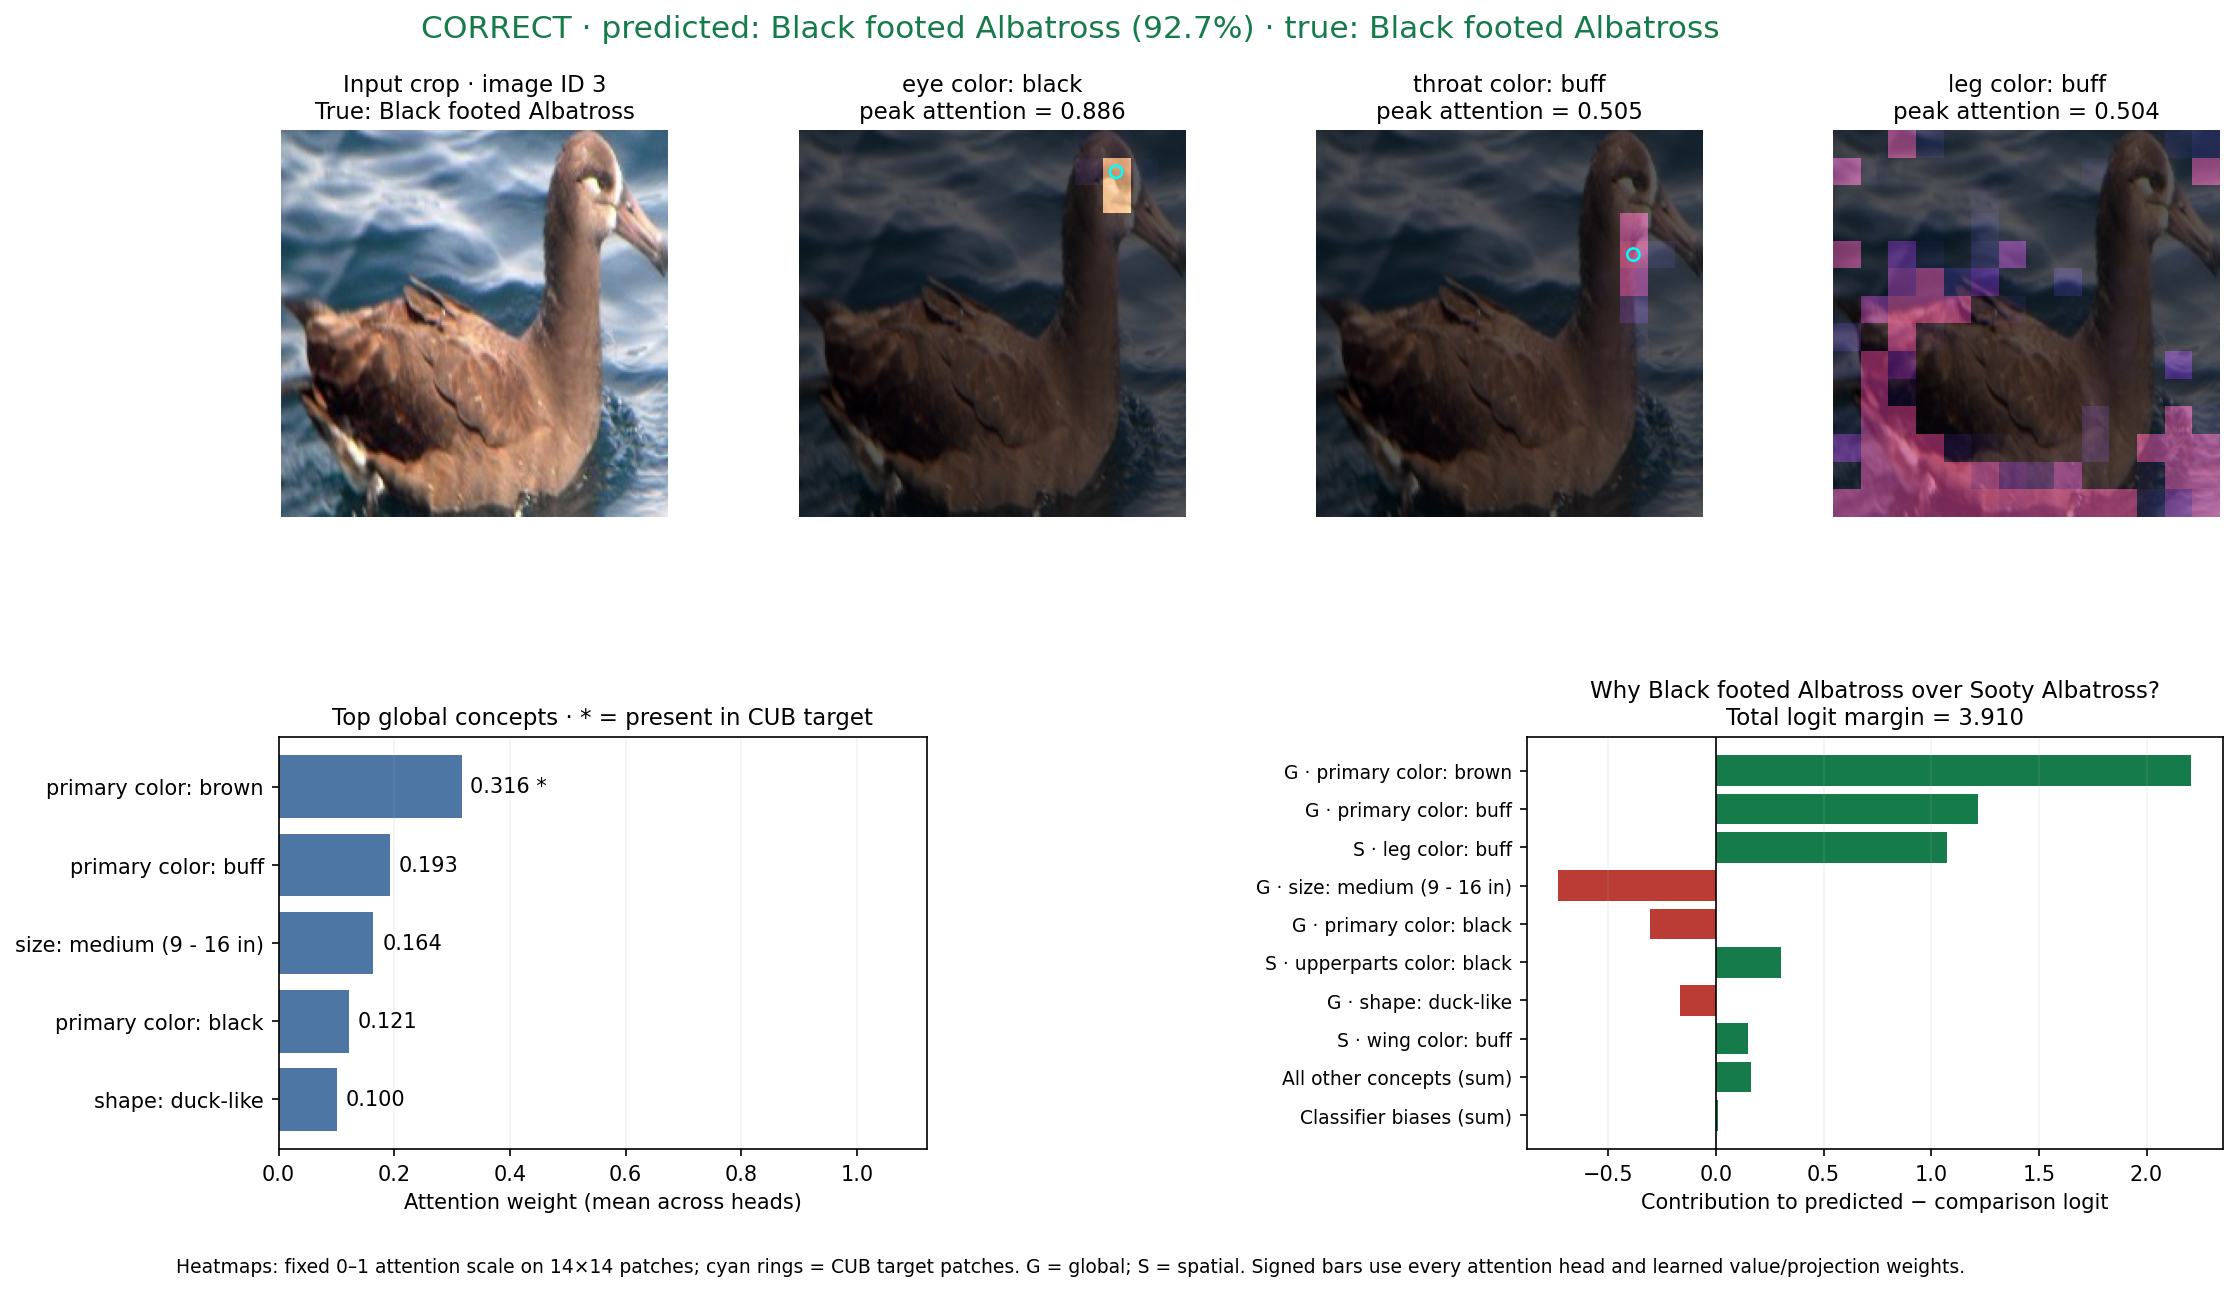

In [23]:
# One example in detail: the figure rendered from the checkpoint by scripts/visualize_test_explanations.py.
EXAMPLE_ID = 3  # Black-footed Albatross, a correct prediction; any image ID from the table in 5.2 works

explanations = json.loads((ARTIFACT_DIR / "examples.json").read_text())
by_id = {sample["image_id"]: sample for sample in explanations["examples"]}
assert EXAMPLE_ID in by_id, f"EXAMPLE_ID must be one of {sorted(by_id)}"
sample = by_id[EXAMPLE_ID]
if sample["correct"]:
    summary = (f"Correct: {sample['true_class']} at {sample['predicted_probability']:.1%}, "
               f"compared with the runner-up, {sample['comparison_class']}.")
else:
    summary = (f"Wrong: {sample['true_class']} predicted as {sample['predicted_class']} at "
               f"{sample['predicted_probability']:.1%}; the true species gets {sample['true_probability']:.2%}.")
show_image(ARTIFACT_DIR / sample["figure_png"], width=1100, caption_text=(
    f"<b>Figure 5.2</b> {summary} The signed bars add up to the logit margin of {sample['logit_margin']:.2f}."))

**Wrong: a Horned Grebe called an Eared Grebe, with high confidence.** Grey upperparts, attended across the water as well as the body, gives by far the largest push toward Eared Grebe; black upperparts favors the true species but is outweighed. None of the five most-attended global concepts is annotated for this image, and the top shape concept is perching-like, for a water bird. The explanation does not prevent the mistake, but it shows which concepts made it.

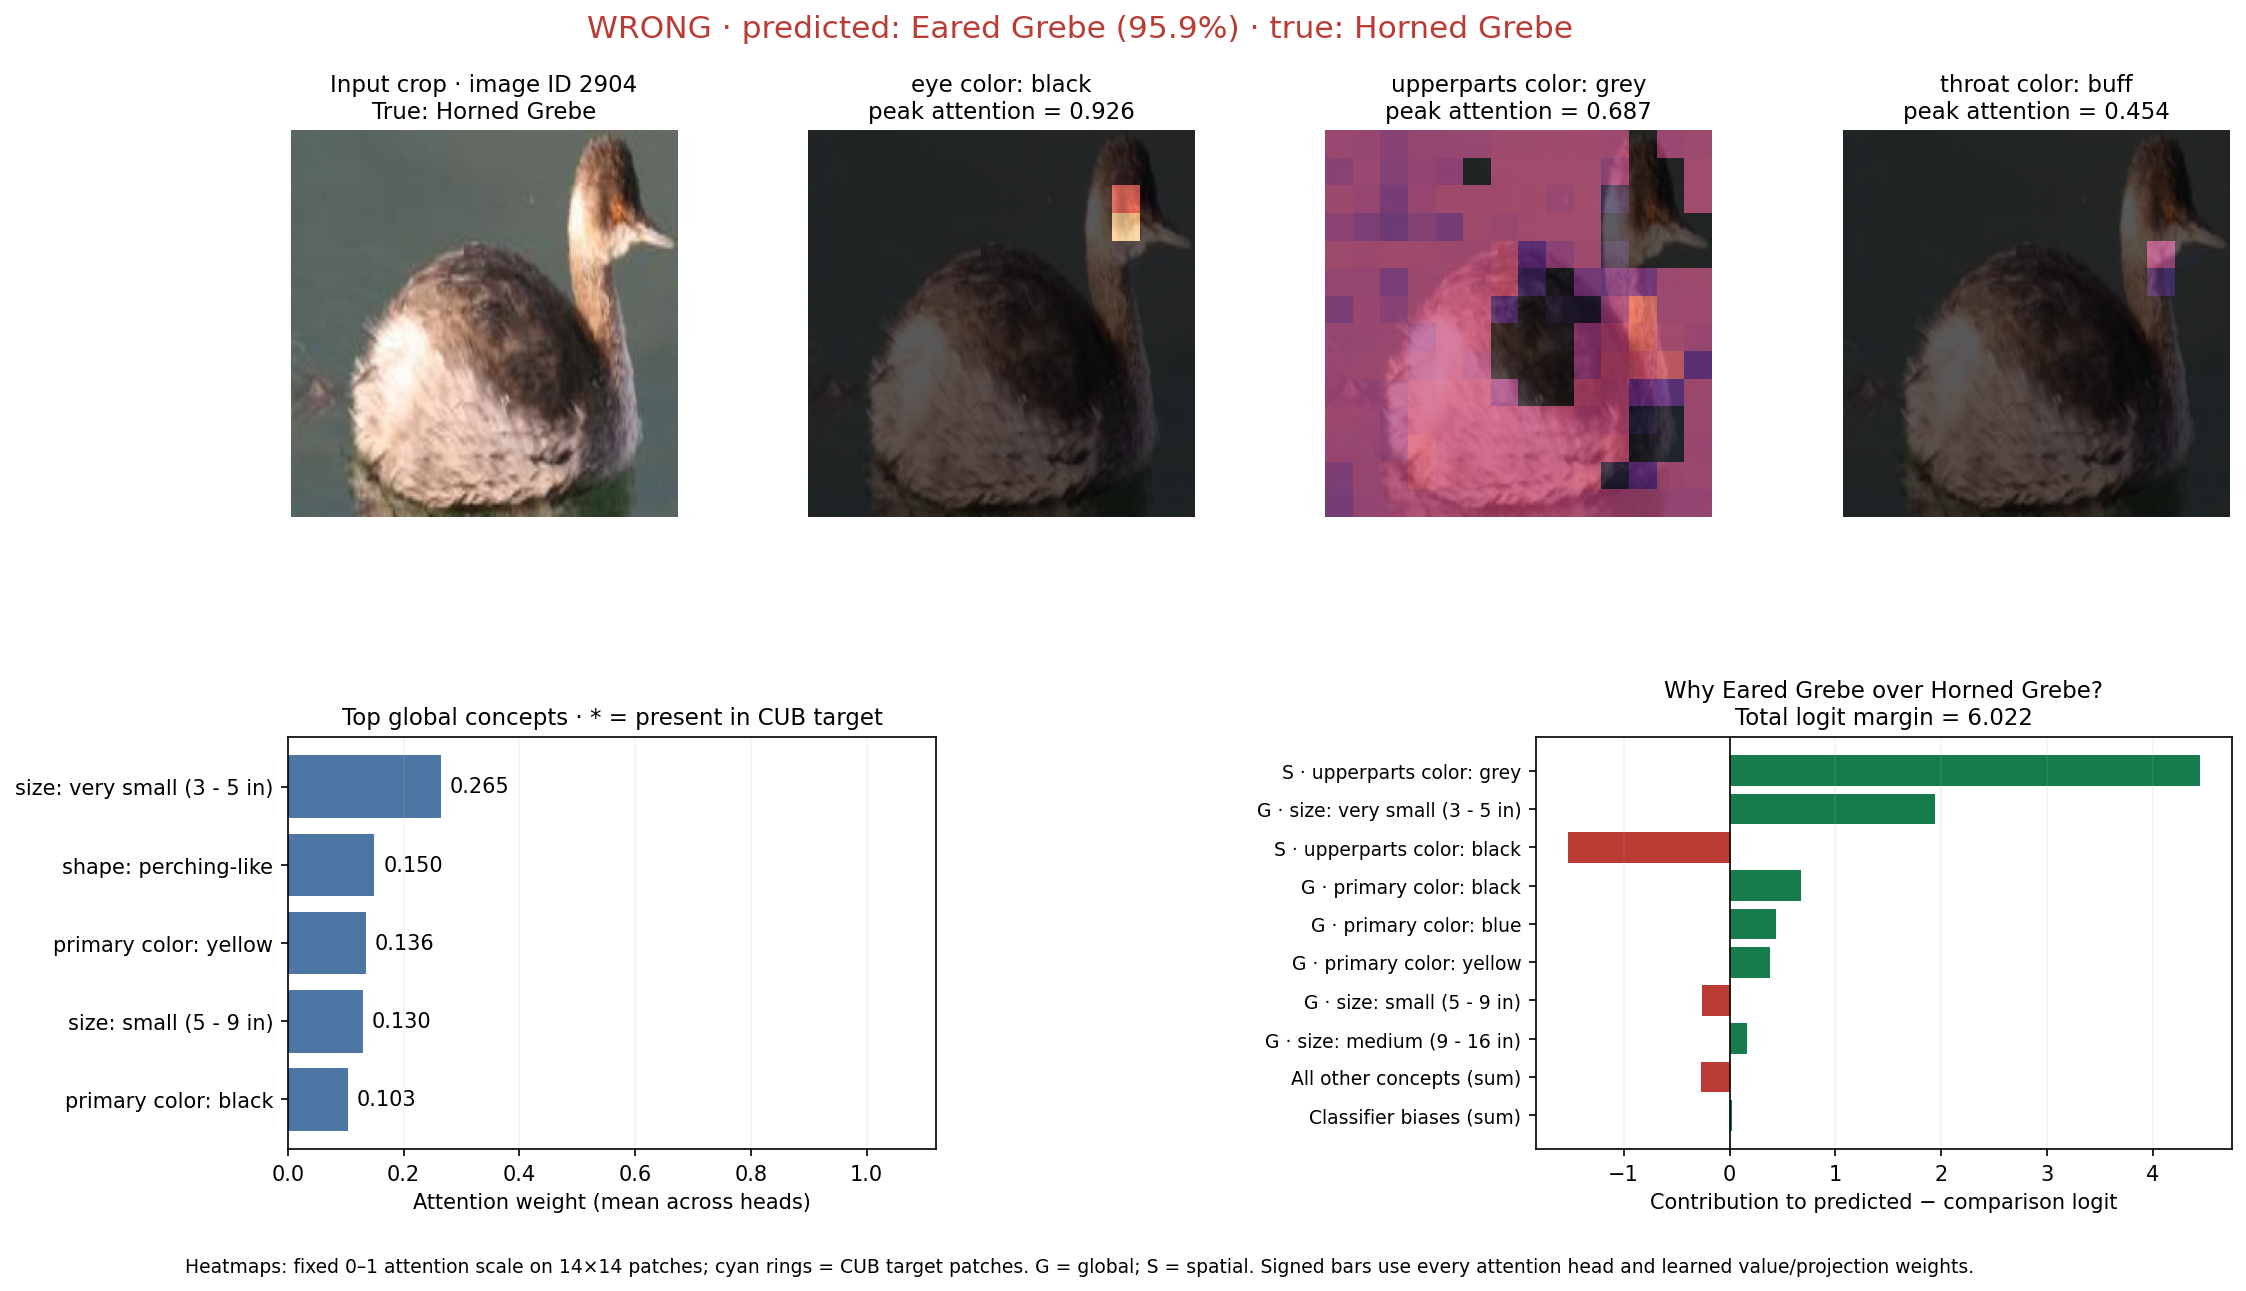

In [24]:
# One example in detail: the figure rendered from the checkpoint by scripts/visualize_test_explanations.py.
EXAMPLE_ID = 2904  # Horned Grebe predicted as Eared Grebe, a confident error; any image ID from the table in 5.2 works

explanations = json.loads((ARTIFACT_DIR / "examples.json").read_text())
by_id = {sample["image_id"]: sample for sample in explanations["examples"]}
assert EXAMPLE_ID in by_id, f"EXAMPLE_ID must be one of {sorted(by_id)}"
sample = by_id[EXAMPLE_ID]
if sample["correct"]:
    summary = (f"Correct: {sample['true_class']} at {sample['predicted_probability']:.1%}, "
               f"compared with the runner-up, {sample['comparison_class']}.")
else:
    summary = (f"Wrong: {sample['true_class']} predicted as {sample['predicted_class']} at "
               f"{sample['predicted_probability']:.1%}; the true species gets {sample['true_probability']:.2%}.")
show_image(ARTIFACT_DIR / sample["figure_png"], width=1100, caption_text=(
    f"<b>Figure 5.3</b> {summary} The signed bars add up to the logit margin of {sample['logit_margin']:.2f}."))

<div style="border-top: 3px solid #ac543f; background: rgba(172, 84, 63, 0.07); padding: 12px 18px 14px 18px;"><div style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65; margin-bottom: 6px;">Key point</div><div style="font-family: Newsreader, Georgia, serif; font-size: 21px; line-height: 1.4;">The bars are exactly what the classifier computed, so the explanation is faithful by construction. Whether its concepts are right is a separate question: attention can sit on water, or on attributes the annotation does not list.</div></div>

### 5.4 Global concepts: where their attention depends on the image

Global concepts have no patch map in this model: only the class token attends to them, as the grey cells in Figure 1.2 show. To see which image regions a global concept's attention depends on, we compute a Grad-CAM map: the gradient of that concept's attention weight with respect to the patch tokens entering the last ViT block, the last place where the class token reads the patches. Each feature channel is weighted by its mean gradient over the 196 patches, and only the positive part is kept.

These maps are not the model's own explanation. They are a post-hoc approximation, the kind Section 1.2 criticizes: they show where the attention weight is sensitive to the image, not what the model computed, and each map is scaled to its own maximum. Read them next to the bar charts in 5.3, which remain the faithful account.

In [ ]:
# Figure 5.4: Grad-CAM maps for each example's three most-attended global concepts, from scripts/global_concept_gradcam.py.
GRADCAM_REPORT = ARTIFACT_DIR / "global_gradcam.json"
gradcam = json.loads(GRADCAM_REPORT.read_text()) if GRADCAM_REPORT.is_file() else None
if gradcam is not None and gradcam["mode"] == "checkpoint":
    assert gradcam["checkpoint_sha256"] == json.loads((ARTIFACT_DIR / "examples.json").read_text())["checkpoint_sha256"]
    show_image(ARTIFACT_DIR / "global_gradcam.png", width=900, caption_text=(
        "<b>Figure 5.4</b> For each of the six examples, its three most-attended global concepts. Color is Grad-CAM of "
        "the concept's attention weight with respect to the patch tokens entering the last ViT block, scaled to each "
        "map's own maximum. A post-hoc approximation, not attention the model computed."))
else:
    print("Not computed yet: these maps need the disjoint run's checkpoint, which this account cannot read.\n"
          "Once it is readable, run from the repository root:\n"
          "  .venv/bin/python scripts/global_concept_gradcam.py --checkpoint <path to binary_mnist_best_ckpt.ckpt>\n"
          "The script checks that the checkpoint matches the cached examples before writing the figure.")

### 5.5 Live: any example, redrawn from its saved tensors

The six examples' attention maps, contributions and logits are cached, so this cell redraws any of them without loading the model, and re-checks that the contributions rebuild the logits. Image 622 is a correct prediction whose strongest support, black leg color, is attended across the background.

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; cached tensors, no model &middot; change <code>EXAMPLE_ID</code>, <code>SPATIAL_CONCEPT</code> or <code>TOP_K</code> and re-run</span></div>

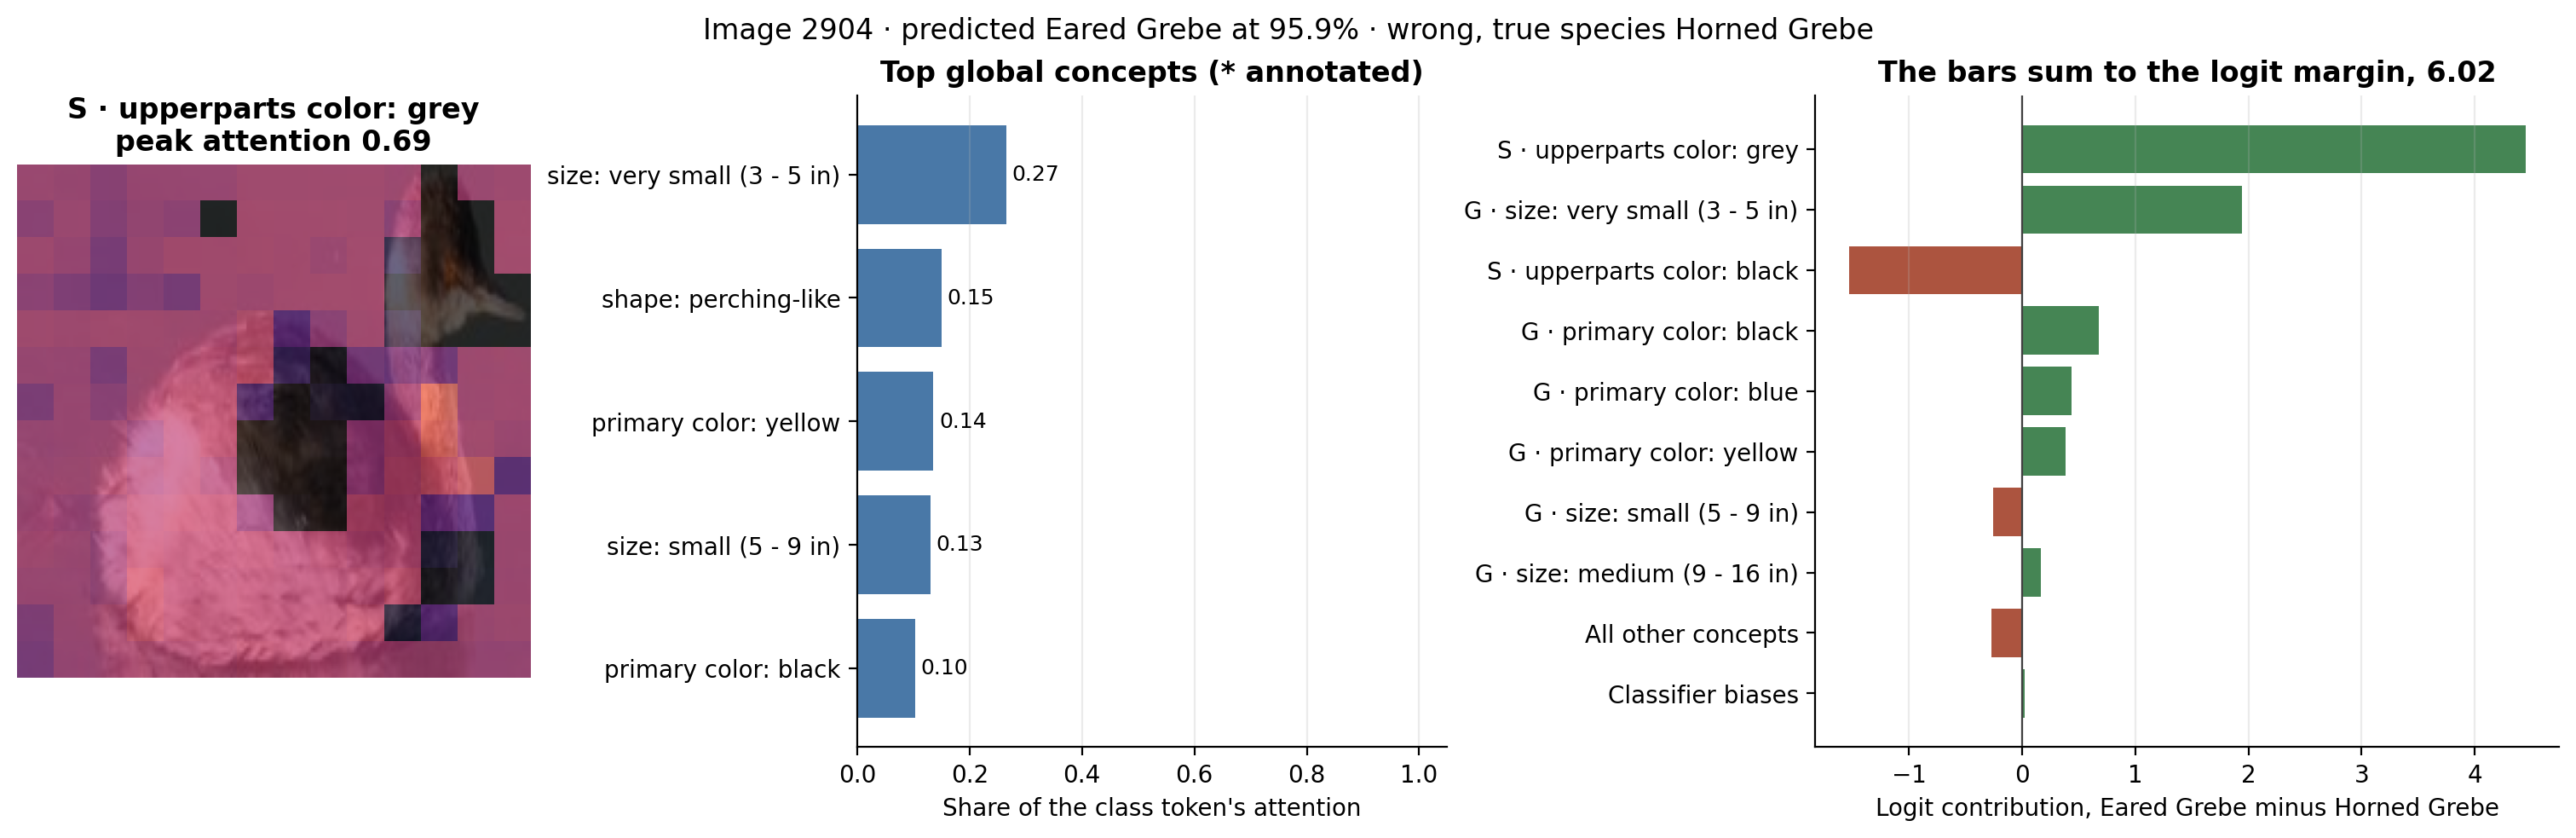

In [35]:
# Live: one of the six examples, redrawn from its cached tensors; no model or GPU needed.
EXAMPLE_ID = 2904  # image ID: 3, 190, 622 (correct) or 434, 1593, 2904 (wrong)
SPATIAL_CONCEPT = "upperparts color: grey"  # None = strongest peak attention; or part of a concept name, e.g. "wing color: black"
TOP_K = 8  # concepts with the largest signed contributions to draw, 1 to 12


def pretty(name):
    """'has_leg_color::black' -> 'leg color: black'."""
    return name.replace("has_", "").replace("_", " ").replace("::", ": ")


explanations = json.loads((ARTIFACT_DIR / "examples.json").read_text())
with np.load(ARTIFACT_DIR / "selected_examples.npz") as saved:
    tensors = dict(saved)
position = {sample["image_id"]: index for index, sample in enumerate(explanations["examples"])}
assert EXAMPLE_ID in position, f"EXAMPLE_ID must be one of {sorted(position)}"
assert 1 <= TOP_K <= 12, "TOP_K must be between 1 and 12"
i = position[EXAMPLE_ID]
sample = explanations["examples"][i]
global_names = [pretty(name) for name in explanations["global_attributes"]]
spatial_names = [pretty(name) for name in explanations["spatial_attributes"]]
if SPATIAL_CONCEPT is None:
    concept = sample["displayed_spatial_indices"][0]
else:
    matches = [j for j, name in enumerate(spatial_names) if pretty(SPATIAL_CONCEPT) in name]
    assert len(matches) == 1, f"{SPATIAL_CONCEPT!r} matches {len(matches)} spatial concepts; choose from {spatial_names}"
    concept = matches[0]

# The classifier is linear in the concepts, so contributions plus biases rebuild every class logit.
contributions = tensors["contributions"][i]  # 108 concepts (13 global, then 95 spatial) x 200 classes
logits = tensors["logits"][i]
np.testing.assert_allclose(contributions.sum(axis=0) + tensors["bias"], logits, atol=1e-4, rtol=1e-4)
pred, other = sample["predicted_label"], sample["comparison_label"]
margin = contributions[:, pred] - contributions[:, other]
top = np.argsort(-np.abs(margin), kind="stable")[:TOP_K]
names = ["G · " + name for name in global_names] + ["S · " + name for name in spatial_names]
values = [float(margin[j]) for j in top]
values += [float(margin.sum() - margin[top].sum()), float(tensors["bias"][pred] - tensors["bias"][other])]
labels = [names[j] for j in top] + ["All other concepts", "Classifier biases"]
probability = np.exp(logits - logits.max())
probability /= probability.sum()

fig, (ax_map, ax_global, ax_signed) = plt.subplots(
    1, 3, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.15, 1.45]}, constrained_layout=True)
weights = tensors["spatial_attention"][i, :, concept].reshape(14, 14)  # one weight per 16 x 16-pixel patch
ax_map.imshow(tensors["images"][i])
ax_map.imshow(weights, cmap="magma", vmin=0, vmax=1, alpha=0.65, extent=(-0.5, 223.5, 223.5, -0.5),
              interpolation="nearest")
target_rows, target_cols = np.where(tensors["spatial_targets"][i, :, concept].reshape(14, 14) == 1)
ax_map.scatter((target_cols + 0.5) * 16 - 0.5, (target_rows + 0.5) * 16 - 0.5, s=35, facecolors="none",
               edgecolors="cyan", linewidths=1.2)
ax_map.set_title(f"S · {spatial_names[concept]}\npeak attention {weights.max():.2f}")
ax_map.axis("off")

attention = tensors["global_attention"][i]
order = np.argsort(-attention, kind="stable")[:5]
ax_global.barh(np.arange(5), attention[order], color=PALETTE["neg"])
for row, j in enumerate(order):
    ax_global.text(attention[j] + 0.01, row, f"{attention[j]:.2f}", va="center", fontsize=9)
ax_global.set_yticks(np.arange(5))
ax_global.set_yticklabels([global_names[j] + (" *" if tensors["global_targets"][i, j] == 1 else "") for j in order])
ax_global.invert_yaxis()
ax_global.set(xlim=(0, 1.05), xlabel="Share of the class token's attention", title="Top global concepts (* annotated)")
ax_global.grid(False, axis="y")

ax_signed.barh(np.arange(len(values)), values, color=[PALETTE["pos"] if v >= 0 else PALETTE["accent"] for v in values])
ax_signed.set_yticks(np.arange(len(values)))
ax_signed.set_yticklabels(labels)
ax_signed.invert_yaxis()
ax_signed.axvline(0, color="0.25", linewidth=0.8)
ax_signed.set(xlabel=f"Logit contribution, {sample['predicted_class']} minus {sample['comparison_class']}",
              title=f"The bars sum to the logit margin, {sum(values):.2f}")
ax_signed.grid(False, axis="y")
outcome = "correct" if sample["correct"] else f"wrong, true species {sample['true_class']}"
fig.suptitle(f"Image {EXAMPLE_ID} · predicted {sample['predicted_class']} at {probability[pred]:.1%} · {outcome}")
plt.show()
caption(f"<b>Figure 5.5</b> Redrawn from <code>selected_examples.npz</code>; the check above rebuilt all {logits.size} "
        f"logits from {contributions.shape[0]} concept contributions plus biases. Left: attention to "
        f"<i>{spatial_names[concept]}</i>, cyan rings on annotated patches. Right: green favors "
        f"{sample['predicted_class']}, terracotta favors {sample['comparison_class']}.")

<details><summary style="cursor: pointer; font-size: 15px;"><b>Backup:</b> how the six examples were chosen and computed</summary>

- **Chosen by rule, not by eye:** 64 evenly spaced positions in the disjoint test split, scanned in order. The first three correct and the first three wrong predictions with different true species were kept. Their probabilities describe these six images, not a new test accuracy.
- **Inference:** the disjoint run's selected checkpoint in evaluation mode, CPU float32, with the repository's test transform (resize to 224 × 224 and ImageNet normalization, no augmentation).
- **Contributions:** forward hooks capture each head's attention over the concepts, and the output layer projects each concept's value vector onto the 200 classes. Attention times projected value, summed over heads, gives one contribution per concept and class.
- **Code:** `scripts/visualize_test_explanations.py` extracts and renders everything in `explanation_artifacts/disjoint-45478721/`; its `--render-only` flag redraws the figures from the cached tensors. The cell below reruns the extraction.

</details>

In [26]:
# Backup: recompute the six examples from the disjoint run's checkpoint. Slow on CPU; the cells above use the cache.
RERUN_EXPLANATIONS = False  # True loads the 3.7 GB checkpoint and overwrites ARTIFACT_DIR; then re-run 5.2 to 5.5

import subprocess

if RERUN_EXPLANATIONS:
    result = subprocess.run(
        [sys.executable, str(PROJECT_DIR / "scripts" / "visualize_test_explanations.py"), "--data-dir", str(DATA_DIR),
         "--output-dir", str(ARTIFACT_DIR), "--threads", str(CPU_THREADS)],
        capture_output=True, text=True)
    print(result.stdout[-3000:], result.stderr[-3000:], sep="\n")
    result.check_returncode()
else:
    print(f"Skipped: the figures above come from {ARTIFACT_DIR.relative_to(PROJECT_DIR)}. "
          "Set RERUN_EXPLANATIONS = True to rebuild them from the checkpoint.")

Skipped: the figures above come from explanation_artifacts/disjoint-45478721. Set RERUN_EXPLANATIONS = True to rebuild them from the checkpoint.


<div style="border-top: 1px solid rgba(128, 128, 128, 0.45); padding-top: 10px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65;">Discussion &middot; about 5 min</span></div>

## <span style="font-family: Newsreader, Georgia, serif; font-size: 34px; font-weight: 400;">6. Discussion</span>

<div style="font-size: 19px; line-height: 1.5; max-width: 44em;">The explanations are exact about how the classifier head combined its concepts, and unchecked about whether those concepts are what the image shows. This section shows that gap on our six examples, traces it to the training setup and to the labels the method depends on, and lists what would close it.</div>

Two terms used below:

<div><div style="display: inline-block; vertical-align: top; width: 47%; margin-right: 4%; border-top: 3px solid #4978a7; padding-top: 8px;"><div style="font-family: Newsreader, Georgia, serif; font-size: 22px; margin-bottom: 4px;">Scored patch</div><div style="font-size: 15px; line-height: 1.5;">A patch of the 14 &times; 14 grid that contains a CUB part keypoint. These are the only patches the explanation loss scores. CUB marks 15 parts, so at most 15 of the 196 patches in an image are scored; in our six images, 7 to 13 are.</div></div><div style="display: inline-block; vertical-align: top; width: 47%; border-top: 3px solid #4978a7; padding-top: 8px;"><div style="font-family: Newsreader, Georgia, serif; font-size: 22px; margin-bottom: 4px;">Concentration penalty</div><div style="font-size: 15px; line-height: 1.5;">The training term <code>attention_sparsity</code> (weight 0.5) that rewards each patch for putting its attention on few concepts. It applies to all 196 patches, scored or not. The paper's loss has no such term.</div></div></div>

### 6.1 Faithful is not the same as correct

Section 5 showed that the concept bars rebuild every class score exactly. That guarantee covers two things: which concept slots the head attended to, and how much each slot counted toward each class. It does not cover a third: whether what a slot responds to matches its name. The name "leg color: black" is a training target. The explanation loss applies it at the patches where CUB marks a leg, and nowhere else. On every other patch the slot can respond to whatever helps classification, and the explanation still reports it under that name.

The six examples show this happening:

- **Yellow-headed Blackbird (image 622, correct, 94.2%).** The largest single contribution is "leg color: black", +3.15 of the 4.01 logit margin. The image has no scored leg patch, and the map in Figure 5.1 is bright on the background and dark on the bird. The prediction is right; the reason reported is a leg the model is not looking at.
- **Horned Grebe called Eared Grebe (image 2904, wrong, 95.9%).** The largest push toward the wrong species is "upperparts color: grey", +4.45, attended across the water as well as the body.
- **Attention is not support either.** Of the 30 most-attended global concepts in the six examples (five per image), 12 push toward the other class. On the albatross, "medium size" draws the third-most attention and votes against it.

So a reader of these explanations learns exactly what the head did with each named slot. Whether the slot saw what its name says has to be checked separately.

### 6.2 Why?

1. **Only scored patches are supervised.** A patch gets a concept target only if a CUB part keypoint falls in it; `spatial_concepts_cost` drops every other patch. At most 15 of 196 patches per image are scored.
2. **Every patch votes.** The head averages the class scores of all 196 patches (`out_s.mean(1)`), so an unscored patch shapes the prediction as much as a scored one.
3. **Every patch is pushed to commit.** The concentration penalty rewards each patch for putting its attention on few concepts. In our examples the median patch puts half its attention on a single concept.

So about 185 patches per image must pick a concept with no prior knowledge, and whatever they pick counts just as much as a scored patch.

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; instant: cached tensors, no model &middot; change <code>SHOW_TOP</code> and re-run</span></div>

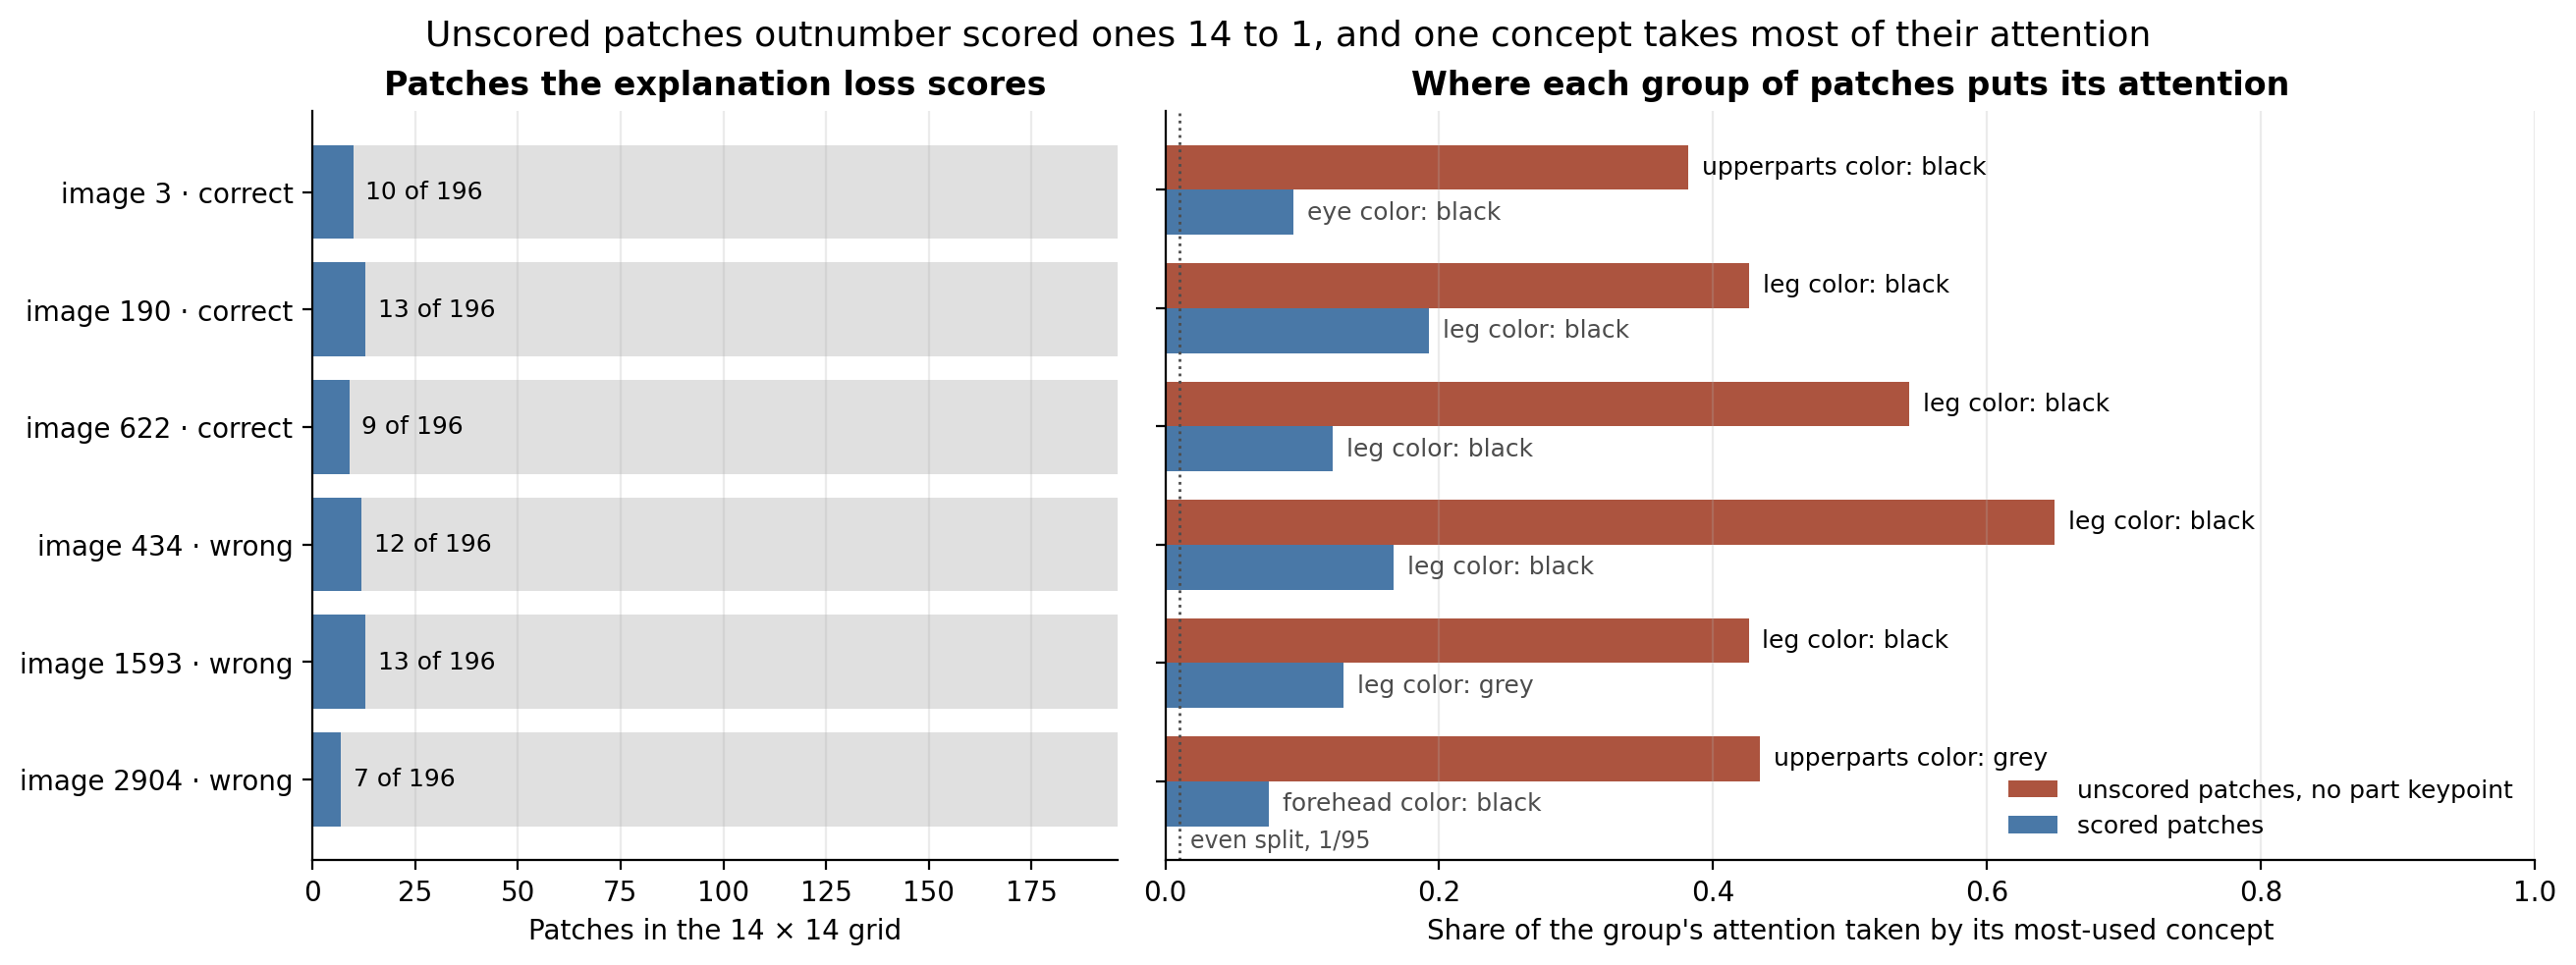

Unscored patches, pooled over the six images, give their attention to: leg color: black 34%; upperparts color: black 17%; upperparts color: grey 12% (an even split would be 1.1% each).
The median patch puts 50% of its attention on one concept.
  image    3: unscored patches' top concepts: upperparts color: black 38%, leg color: buff 13%, wing color: buff 13%
  image  190: unscored patches' top concepts: leg color: black 43%, upperparts color: black 20%, upperparts color: grey 6%
  image  622: unscored patches' top concepts: leg color: black 54%, upperparts color: grey 19%, wing color: white 7%
  image  434: unscored patches' top concepts: leg color: black 65%, wing color: black 9%, wing pattern: solid 7%
  image 1593: unscored patches' top concepts: leg color: black 43%, wing pattern: solid 16%, wing color: black 10%
  image 2904: unscored patches' top concepts: upperparts color: grey 43%, upperparts color: black 35%, wing color: white 2%


In [36]:
# Figure 6.1: how few patches the explanation loss scores, and where the unscored patches put their attention.
SHOW_TOP = 3  # concepts named in the printed summary

explanations = json.loads((ARTIFACT_DIR / "examples.json").read_text())
with np.load(ARTIFACT_DIR / "selected_examples.npz") as saved:
    spatial_attention, spatial_targets = saved["spatial_attention"], saved["spatial_targets"]
examples = explanations["examples"]
n_images, n_patches, n_spatial = spatial_attention.shape
N_PARTS = 15  # CUB marks 15 part locations per image; each falls in one patch


def concept_label(attribute):
    """'has_leg_color::black' -> 'leg color: black'; size ranges are dropped."""
    family, value = attribute.replace("has_", "").split("::")
    return "{}: {}".format(family.replace("_", " "), value.split("_(")[0].replace("_", " "))


spatial_names = [concept_label(name) for name in explanations["spatial_attributes"]]
np.testing.assert_allclose(spatial_attention.sum(axis=2), 1.0, atol=1e-4)  # each patch's weights sum to 1

rows, pooled = [], np.zeros(n_spatial)
for i, sample in enumerate(examples):
    scored = ~np.isnan(spatial_targets[i]).all(axis=1)  # patches holding a part keypoint: the only ones the loss sees
    assert 0 < scored.sum() <= N_PARTS
    unscored_mean = spatial_attention[i, ~scored].mean(axis=0)  # a mean of rows that sum to 1, so it sums to 1
    scored_mean = spatial_attention[i, scored].mean(axis=0)
    pooled += spatial_attention[i, ~scored].sum(axis=0)
    rows.append({
        "image_id": sample["image_id"], "correct": sample["correct"], "scored": int(scored.sum()),
        "unscored_top": int(unscored_mean.argmax()), "unscored_share": float(unscored_mean.max()),
        "scored_top": int(scored_mean.argmax()), "scored_share": float(scored_mean.max()),
        "unscored_ranked": [int(j) for j in np.argsort(-unscored_mean)[:SHOW_TOP]], "unscored_mean": unscored_mean,
    })
pooled /= pooled.sum()
even_share = 1 / n_spatial
median_peak = float(np.median(spatial_attention.max(axis=2)))  # the largest weight in each patch's row

fig, (ax_count, ax_share) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.7]},
                                         constrained_layout=True)
y = np.arange(n_images)
ax_count.barh(y, [n_patches] * n_images, color="0.88")
ax_count.barh(y, [r["scored"] for r in rows], color=PALETTE["neg"])
for row, r in zip(y, rows):
    ax_count.text(r["scored"] + 3, row, "{} of {}".format(r["scored"], n_patches), va="center", fontsize=9)
ax_count.set_yticks(y)
ax_count.set_yticklabels(["image {} · {}".format(r["image_id"], "correct" if r["correct"] else "wrong") for r in rows])
ax_count.invert_yaxis()
ax_count.set(xlim=(0, n_patches), xlabel="Patches in the 14 × 14 grid", title="Patches the explanation loss scores")
ax_count.grid(False, axis="y")

height = 0.38
ax_share.barh(y - height / 2, [r["unscored_share"] for r in rows], height=height, color=PALETTE["accent"],
              label="unscored patches, no part keypoint")
ax_share.barh(y + height / 2, [r["scored_share"] for r in rows], height=height, color=PALETTE["neg"],
              label="scored patches")
for row, r in zip(y, rows):
    ax_share.text(r["unscored_share"] + 0.01, row - height / 2, spatial_names[r["unscored_top"]], va="center", fontsize=9)
    ax_share.text(r["scored_share"] + 0.01, row + height / 2, spatial_names[r["scored_top"]], va="center", fontsize=9,
                  alpha=0.7)
ax_share.axvline(even_share, color="0.3", linestyle=":", linewidth=1)
ax_share.text(even_share + 0.008, n_images - 0.5, "even split, 1/{}".format(n_spatial), fontsize=8.5, color="0.3",
              va="center")
ax_share.set_yticks(y)
ax_share.set_yticklabels([])
ax_share.invert_yaxis()
ax_share.set(xlim=(0, 1), xlabel="Share of the group's attention taken by its most-used concept",
             title="Where each group of patches puts its attention")
ax_share.legend(loc="lower right", fontsize=9)
ax_share.grid(False, axis="y")
fig.suptitle("Unscored patches outnumber scored ones 14 to 1, and one concept takes most of their attention", fontsize=13)
plt.show()

unscored_range = (min(r["unscored_share"] for r in rows), max(r["unscored_share"] for r in rows))
scored_range = (min(r["scored_share"] for r in rows), max(r["scored_share"] for r in rows))
leg_black = sum(spatial_names[r["unscored_top"]] == "leg color: black" for r in rows)
caption("<b>Figure 6.1</b> Left: patches that carry a CUB part keypoint, the only ones the explanation loss scores. "
        "Right: for each image, the share of attention taken by the single most-used concept, averaged over the "
        "unscored patches (terracotta) and over the scored patches (blue-grey), with that concept named. Scored patches "
        "follow targets that differ by part, so their average is spread ({:.0%} to {:.0%}). Unscored patches have no "
        "target, and in every image a single concept takes {:.0%} to {:.0%} of their attention: <i>leg color: black</i> in "
        "{} of {}. Cached tensors from the disjoint run's selected checkpoint.".format(
            *scored_range, *unscored_range, leg_black, n_images))
order = np.argsort(-pooled)[:SHOW_TOP]
print("Unscored patches, pooled over the six images, give their attention to: "
      + "; ".join("{} {:.0%}".format(spatial_names[j], pooled[j]) for j in order)
      + " (an even split would be {:.1%} each).".format(even_share))
print("The median patch puts {:.0%} of its attention on one concept.".format(median_peak))
for r in rows:
    print("  image {:>4}: unscored patches' top concepts: ".format(r["image_id"])
          + ", ".join("{} {:.0%}".format(spatial_names[j], r["unscored_mean"][j]) for j in r["unscored_ranked"]))

**"leg color: black".** Over all 196 patches of the six images, "leg color: black" takes a third of the spatial attention and is the largest weight in half of the patches; it is the top concept over the whole image in four of the six.

But it is not a frequent label: a quarter of CUB images have it, rank 33 of the 95 spatial concepts, while "eye color: black" is in 84% of images and does not spread. 

The difference is likely caused by what the slot is trained on. A leg is thin, so the 16-pixel patch at a leg keypoint is mostly ground, grass or pavement with a line of leg across it. The slot named "leg color: black" learns that appearance, and every unscored patch that looks like ground matches it: its attention rises with distance from the bird. The two water images use other concepts the same way: the sea around the albatross goes to "upperparts color: black", the lake around the grebe to "upperparts color: grey".

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; instant: cached tensors and images, no model &middot; change <code>CONCEPT</code> to follow another slot</span></div>

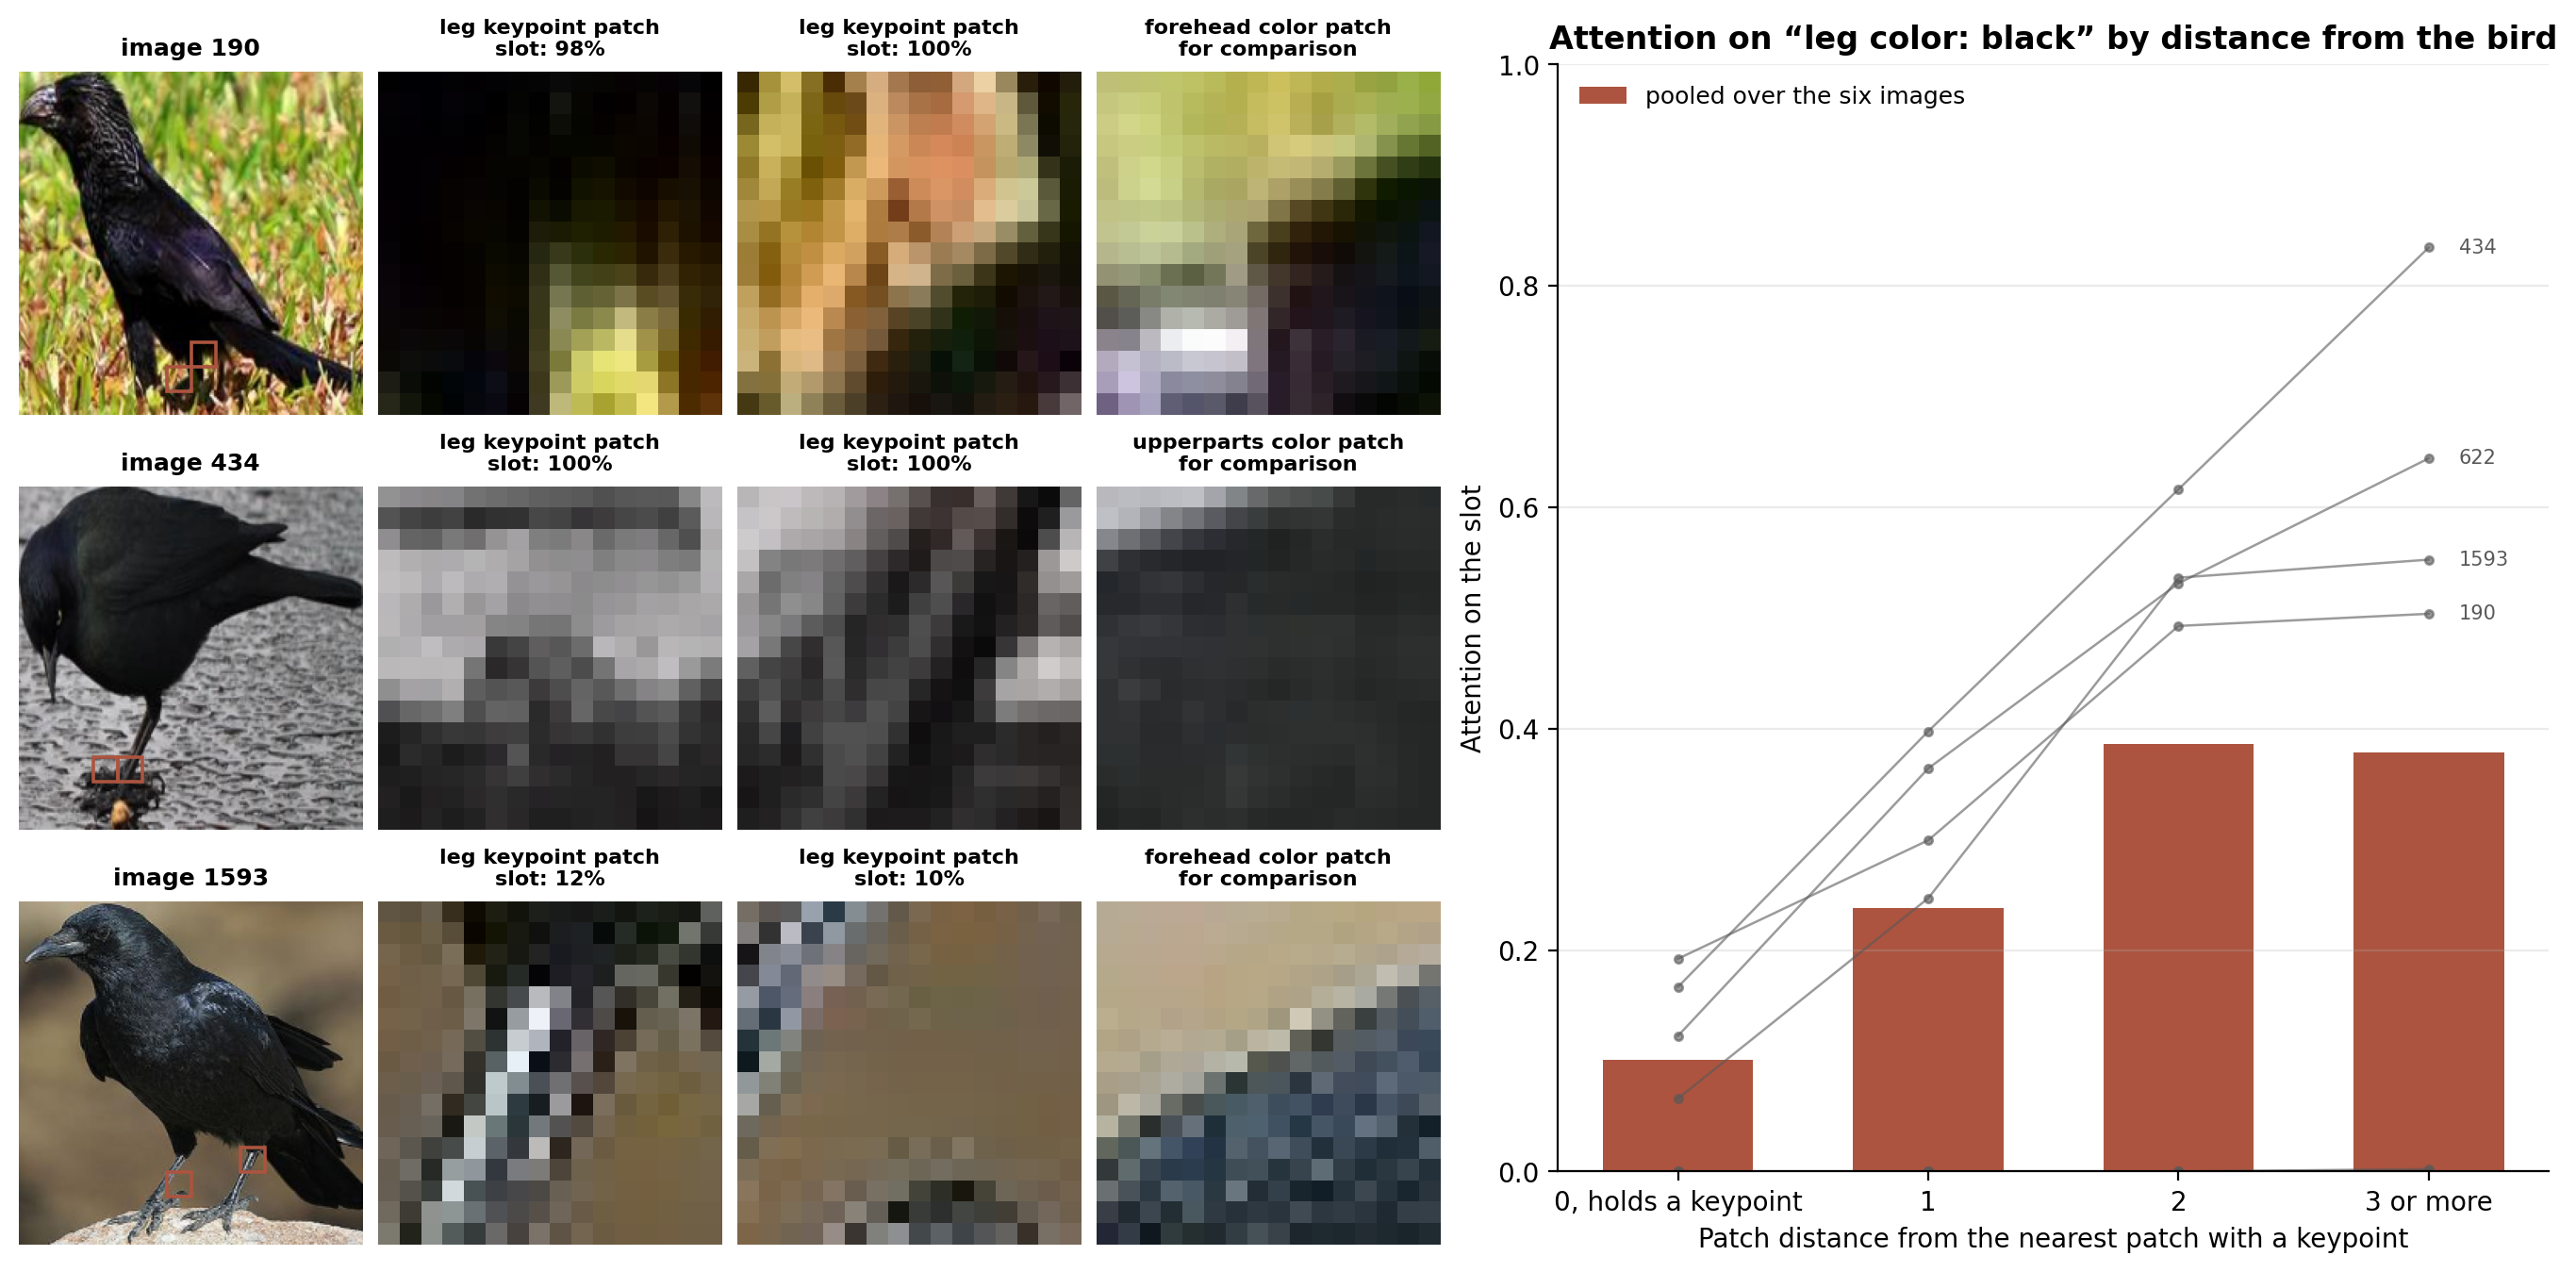

Over all 1176 patches of the six images, the slot takes 33% of the spatial attention, is the largest weight in 594 patches, and is the top concept over the whole image in 4 of 6.
Label frequency in CUB: has_leg_color::black is present in 25% of images, rank 33 of 95; has_eye_color::black is present in 84% and takes 0.9% of the attention here.


In [37]:
# Figure 6.2: what the "leg color: black" slot is trained on, and how its attention grows with distance from the bird.
import pandas as pd

CONCEPT = "has_leg_color::black"
CONTRAST = "has_eye_color::black"  # the most frequent spatial label, for comparison
PATCH, N_THUMBS = 16, 2  # 16-px patches; leg patches shown per image

with np.load(ARTIFACT_DIR / "selected_examples.npz") as saved:
    images, spatial_attention, spatial_targets = saved["images"], saved["spatial_attention"], saved["spatial_targets"]
explanations = json.loads((ARTIFACT_DIR / "examples.json").read_text())
examples, spatial_attributes = explanations["examples"], explanations["spatial_attributes"]
n_images, n_patches, n_spatial = spatial_attention.shape
grid = int(round(n_patches ** 0.5))
c = spatial_attributes.index(CONCEPT)
family = CONCEPT.split("::")[0]
family_idx = [k for k, name in enumerate(spatial_attributes) if name.startswith(family)]

# How often the label occurs in CUB, for every spatial concept.
attribute_ids = pd.read_csv(DATA_DIR / "attributes.txt", sep=" ", header=None, names=["attr", "name"]).set_index("name")["attr"]
label_rate = pd.read_csv(DATA_DIR / "CUB_200_2011" / "attributes" / "image_attribute_labels.txt", sep=r"\s+", header=None,
                         engine="c", names=["img", "attr", "present", "certainty", "time"], on_bad_lines="skip"
                         ).groupby("attr")["present"].mean()
frequency = pd.Series({name: label_rate[attribute_ids[name]] for name in spatial_attributes}).sort_values(ascending=False)

# Attention on CONCEPT by Chebyshev distance from the nearest patch that holds a keypoint.
yy, xx = np.divmod(np.arange(n_patches), grid)
distances, keypoint_patches, leg_patches = [], [], []
for i in range(n_images):
    scored = ~np.isnan(spatial_targets[i]).all(axis=1)
    ys, xs = np.divmod(np.nonzero(scored)[0], grid)
    distances.append(np.min(np.maximum(np.abs(yy[:, None] - ys[None]), np.abs(xx[:, None] - xs[None])), axis=1))
    targets = np.nan_to_num(spatial_targets[i], nan=0.0)
    leg_patches.append(np.nonzero(targets[:, family_idx].sum(axis=1) > 0)[0])  # keypoint patches whose target is a leg concept
    keypoint_patches.append(np.nonzero(scored & (targets[:, family_idx].sum(axis=1) == 0))[0])  # other part patches
distances = np.array(distances)
bands = [(0, "0, holds a keypoint"), (1, "1"), (2, "2"), (3, "3 or more")]
in_band = lambda d, b: (d >= 3) if b == 3 else (d == b)
pooled = [spatial_attention[:, :, c][in_band(distances, b)].mean() for b, _ in bands]
share_all = spatial_attention[:, :, c].mean() / spatial_attention.mean(axis=(0, 1)).sum()
won = int((spatial_attention.argmax(axis=2) == c).sum())
top_in = sum(int(spatial_attention[i].mean(axis=0).argmax() == c) for i in range(n_images))

with_legs = [i for i in range(n_images) if len(leg_patches[i])]
fig = plt.figure(figsize=(13.5, 1.9 * len(with_legs) + 0.9), constrained_layout=True)
outer = fig.add_gridspec(1, 2, width_ratios=[1.45, 1])
thumbs = outer[0].subgridspec(len(with_legs), N_THUMBS + 2)
for r, i in enumerate(with_legs):
    ax = fig.add_subplot(thumbs[r, 0])
    ax.imshow(images[i])
    for pch in leg_patches[i]:
        y, x = divmod(int(pch), grid)
        ax.add_patch(plt.Rectangle((x * PATCH, y * PATCH), PATCH, PATCH, fill=False, color=PALETTE["accent"], lw=1.3))
    ax.set_title("image {}".format(examples[i]["image_id"]), fontsize=9)
    ax.set_axis_off()
    for k, pch in enumerate(list(leg_patches[i])[:N_THUMBS]):
        y, x = divmod(int(pch), grid)
        ax = fig.add_subplot(thumbs[r, 1 + k])
        ax.imshow(images[i, y * PATCH:(y + 1) * PATCH, x * PATCH:(x + 1) * PATCH], interpolation="nearest")
        ax.set_title("leg keypoint patch\nslot: {:.0%}".format(spatial_attention[i, pch, c]), fontsize=8)
        ax.set_axis_off()
    pch = int(keypoint_patches[i][0])
    y, x = divmod(pch, grid)
    ax = fig.add_subplot(thumbs[r, N_THUMBS + 1])
    ax.imshow(images[i, y * PATCH:(y + 1) * PATCH, x * PATCH:(x + 1) * PATCH], interpolation="nearest")
    target_names = [spatial_attributes[k].split("::")[0].replace("has_", "").replace("_", " ")
                    for k in np.nonzero(np.nan_to_num(spatial_targets[i], nan=0.0)[pch])[0]]
    ax.set_title("{} patch\nfor comparison".format(target_names[0] if target_names else "other part"), fontsize=8)
    ax.set_axis_off()
ax = fig.add_subplot(outer[1])
x = np.arange(len(bands))
ax.bar(x, pooled, color=PALETTE["accent"], width=0.6, label="pooled over the six images")
for i in range(n_images):
    per_image = [spatial_attention[i, :, c][in_band(distances[i], b)].mean() if in_band(distances[i], b).any() else np.nan
                 for b, _ in bands]
    ax.plot(x, per_image, color="0.35", lw=0.9, marker="o", ms=3, alpha=0.6)
    if per_image[-1] > 0.02:  # the flat lines at zero are left unlabelled
        ax.text(x[-1] + 0.12, per_image[-1], str(examples[i]["image_id"]), fontsize=7.5, va="center", color="0.35")
ax.set_xticks(x)
ax.set_xticklabels([label for _, label in bands])
ax.set(xlabel="Patch distance from the nearest patch with a keypoint", ylabel="Attention on the slot", ylim=(0, 1),
       title="Attention on \u201c{}\u201d by distance from the bird".format(
           CONCEPT.replace("has_", "").replace("::", ": ").replace("_", " ")))
ax.legend(loc="upper left", fontsize=9)
ax.grid(False, axis="x")
plt.show()

caption("<b>Figure 6.2</b> Left: the patches at the leg keypoints (boxes) in the three images that have them, enlarged, beside "
        "a patch at another annotated part of the same bird. A leg crosses its patch as a line; the rest is ground. Right: "
        "attention on the slot by distance from the nearest patch with a keypoint, pooled over the six images (bars) and per "
        "image (lines): {:.0%} on keypoint patches, {:.0%} three or more patches away; the two lines at zero are the water "
        "images 3 and 2904, whose background goes to other slots. Cached tensors and images from the "
        "disjoint run's selected checkpoint.".format(pooled[0], pooled[-1]))
print("Over all {} patches of the six images, the slot takes {:.0%} of the spatial attention, is the largest weight in {} patches, "
      "and is the top concept over the whole image in {} of {}.".format(n_images * n_patches, share_all, won, top_in, n_images))
print("Label frequency in CUB: {} is present in {:.0%} of images, rank {} of {}; {} is present in {:.0%} and takes {:.1%} of the "
      "attention here.".format(CONCEPT, frequency[CONCEPT], int(np.nonzero(frequency.index == CONCEPT)[0][0]) + 1, n_spatial,
                                CONTRAST, frequency[CONTRAST],
                                spatial_attention[:, :, spatial_attributes.index(CONTRAST)].mean() / spatial_attention.mean(axis=(0, 1)).sum()))

### 6.3 Improvements and Next Steps

#### 6.3.1 Give every patch a target

Add a 96th spatial concept, "background", with its vote fixed at zero. With CUB's segmentation masks, every patch outside the bird targets it, and every patch inside the bird targets the concepts of the nearest part keypoint, so all 196 patches are scored. Background attention then appears as its own bar, with no vote, instead of under "leg color: black".

#### 6.3.2 Weight patches instead of averaging them

Replace `out_s.mean(1)` with a learned softmax weight per patch; the global stream already has one (`token_attention_pool`). Each patch's contribution becomes weight × attention × vote, still exact, and the weights show which patches the head counted.

#### 6.3.3 Penalize concentration only when the patches have a target

The concentration penalty is averaged over all 196 patches (`concepts_sparsity_cost` in `ctc/ctc.py`). Give it the keypoint mask the explanation loss already uses, so unscored patches are free to spread their attention.

#### 6.3.4 The labels are the handicap

The method's accuracy depends on the concept labels. The paper's Table 1 reports 88.0 ± 0.4 with them and 76.9 ± 3 without.

**What the labels are, on one species.** Every CUB image was labelled by one crowd worker who answered 312 yes/no questions about the bird and said how sure they were. The loader keeps 108 of the attributes and turns the answers into the training targets: an image's global target is the global attributes its worker marked yes, and its spatial targets are the part attributes marked yes, placed at the part's keypoint. Nothing else enters. The table shows what that gives for the Black-footed Albatross from Section 5: six single images, then the share of all 60 images labelled yes, then CUB's own class-level file for the species.

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; instant: reads CUB's label files, no model &middot; change <code>SPECIES</code>, <code>ATTRIBUTES</code> or <code>SAMPLE_IMAGES</code></span></div>

In [38]:
# One species' labels: six single images, the share of all its images labelled yes, and CUB's class-level file.
import pandas as pd
from data import CUB2011Parts_dataset

SPECIES = "Black_footed_Albatross"  # any species folder name from classes.txt, without its number
ATTRIBUTES = ["has_size::medium_(9_-_16_in)", "has_primary_color::brown", "has_shape::duck-like",  # global concepts
              "has_belly_pattern::solid", "has_leg_color::black"]  # spatial concepts
SAMPLE_IMAGES = [3, 1, 2, 4, 5, 6]  # image 3 is the Section 5 example; the others are the species' first images

CUB = DATA_DIR / "CUB_200_2011"
answers = pd.read_csv(CUB / "attributes" / "image_attribute_labels.txt", sep=r"\s+", header=None, engine="c",
                      names=["img", "attr", "present", "certainty", "time"], on_bad_lines="skip")
attribute_id = pd.read_csv(DATA_DIR / "attributes.txt", sep=" ", header=None, names=["attr", "name"]).set_index("name")["attr"]
species_id = pd.read_csv(CUB / "classes.txt", sep=" ", header=None, names=["cls", "name"]).set_index("name")["cls"]
image_species = pd.read_csv(CUB / "image_class_labels.txt", sep=" ", header=None, names=["img", "cls"]).set_index("img")["cls"]
class_file = np.loadtxt(CUB / "attributes" / "class_attribute_labels_continuous.txt")  # 200 species x 312 attributes, in percent
global_concepts = set(json.loads((ARTIFACT_DIR / "examples.json").read_text())["global_attributes"])
certainty = {1: "not visible", 2: "guessing", 3: "probably", 4: "definitely"}

cls = species_id[[name for name in species_id.index if name.endswith(SPECIES)][0]]
species_answers = answers[answers["img"].map(image_species) == cls]
assert all(image_species[img] == cls for img in SAMPLE_IMAGES), "SAMPLE_IMAGES must belong to SPECIES"


def answer(img, name):
    """One worker's answer for one image and attribute, with the certainty they gave."""
    row = species_answers[(species_answers["img"] == img) & (species_answers["attr"] == attribute_id[name])].iloc[0]
    if row["present"] == 1:
        return "yes, " + certainty[int(row["certainty"])]
    return "not visible" if row["certainty"] == 1 else "no"


def column(name):
    family, value = name.replace("has_", "").split("::")
    kind = "global" if name in global_concepts else "spatial"
    return "{}: {} ({})".format(family.replace("_", " "), value.split("_(")[0].replace("_", " "), kind)


rows = {}
for img in SAMPLE_IMAGES:
    rows["image {}{}".format(img, ", the Section 5 example" if img == SAMPLE_IMAGES[0] else "")] = [answer(img, n) for n in ATTRIBUTES]
n_species = species_answers["img"].nunique()
rows["all {} images: share labelled yes".format(n_species)] = [
    "{:.0%}".format(species_answers[species_answers["attr"] == attribute_id[n]]["present"].mean()) for n in ATTRIBUTES]
rows["CUB's class-level file"] = ["{:.0f}%".format(class_file[cls - 1, attribute_id[n] - 1]) for n in ATTRIBUTES]
table = pd.DataFrame.from_dict(rows, orient="index", columns=[column(n) for n in ATTRIBUTES])
table.index.name = SPECIES.replace("_", " ")
display(table)

# How sure the yes answers were, for this species and for all of CUB.
sure = species_answers[species_answers["present"] == 1]["certainty"].map(certainty).value_counts(normalize=True)
sure_all = answers[answers["present"] == 1]["certainty"].map(certainty).value_counts(normalize=True)
print("{}: of its {:,} yes answers, {:.0%} were given as 'definitely', {:.0%} 'probably', {:.0%} 'guessing'.".format(
    SPECIES.replace("_", " "), int((species_answers["present"] == 1).sum()),
    sure.get("definitely", 0), sure.get("probably", 0), sure.get("guessing", 0)))
print("All of CUB: {:,} yes answers; {:.0%} 'definitely', {:.0%} 'probably', {:.0%} 'guessing'.".format(
    int((answers["present"] == 1).sum()), sure_all.get("definitely", 0), sure_all.get("probably", 0), sure_all.get("guessing", 0)))

# How much the images of a species agree, over the 108 concepts the model learns.
kept = answers[answers["attr"].isin(CUB2011Parts_dataset.attributes_to_retain)].copy()
kept["cls"] = kept["img"].map(image_species)
rate = kept.groupby(["cls", "attr"])["present"].mean().unstack()  # share of each species' images labelled yes
per_image = pd.concat(  # of the concepts that characterise its species (yes in at least 45% of its images), the share an image carries
    group[group["attr"].isin(rate.columns[rate.loc[c] >= 0.45])].groupby("img")["present"].mean() for c, group in kept.groupby("cls"))
print("Over the 108 kept concepts, an image is labelled with {:.0%} of the concepts that characterise its species "
      "(median {:.0%}); the rest are labelled no or not visible.".format(per_image.mean(), per_image.median()))

,size: medium (global),primary color: brown (global),shape: duck-like (global),belly pattern: solid (spatial),leg color: black (spatial)
Black footed Albatross,,,,,
"image 3, the Section 5 example",no,"yes, definitely",no,not visible,not visible
image 1,no,no,no,not visible,not visible
image 2,no,no,no,not visible,no
image 4,"yes, probably","yes, definitely",no,not visible,not visible
image 5,no,"yes, definitely",no,"yes, definitely",not visible
image 6,no,"yes, probably",no,not visible,not visible
all 60 images: share labelled yes,67%,48%,33%,45%,13%
CUB's class-level file,67%,48%,34%,82%,40%


Black footed Albatross: of its 1,592 yes answers, 47% were given as 'definitely', 41% 'probably', 12% 'guessing'.
All of CUB: 371,047 yes answers; 60% 'definitely', 33% 'probably', 7% 'guessing'.


Over the 108 kept concepts, an image is labelled with 65% of the concepts that characterise its species (median 69%); the rest are labelled no or not visible.


Read down a column: the same species gets different targets from different workers. For "primary color: brown", the concept the model used most on image 3 in Section 5, images 1 and 2 are labelled no and images 3 to 5 yes, definitely. Image 3's worker also marked the bird not medium-sized and could not see its belly, while two thirds of the species' images are labelled medium and the class-level file gives a solid belly pattern 82%. The explanation loss trains toward each worker's answers as given, and across all of CUB 40% of the yes answers were given as "probably" or "guessing". That is the handicap: the model's ground truth for a concept is one person's quick answers per image, and most datasets have no such answers at all. The three points below reduce what the method needs from them.

##### 6.3.4.1 Get the targets without hand labels

Global concepts: CUB ships class-level vectors (`class_attribute_labels_continuous.txt`: for each class, the share of workers marking each attribute present), and the code ignores them. Replace each image's global target with its class's vector; the explanation loss normalizes its targets, so the shares work as they are. A new domain then needs one vector per class, written by an expert or a language model, instead of 312 decisions per image.

Spatial concepts: get part regions from an open-vocabulary segmenter prompted with the part names (beak, wing, leg, ...), and give every patch in a region the class's concepts for that part. The explanations then inherit the segmenter's errors instead of the workers' disagreement.

##### 6.3.4.2 Measure how much annotation the method needs

Train with 50%, 10% and 1% of the training images annotated, which needs only a loader change because the loss skips missing targets, and report accuracy and the on-bird attention share against the fraction. The paper says the gain is largest with little data and shows no such curve.

##### 6.3.4.3 Let the model find concepts, then name them

The code has a stream of concept slots without targets (`n_unsup_concepts`, default off for CUB; its forward pass routes through the supervised module). We can train it, then name each slot by the images and patches it fires on. This is still faithful, only that the names are given afterwards rather than before.